# Python · NumPy · Pandas · 기계학습 전체 예제 정리와 빈칸 연습

강의자료 **02)Python_Numpy_Pandas.pptx(46장)**와 **03)DAnML_기계학습_Beginning.pptx(34장)**를 순서대로 정리했습니다. 슬라이드의 모든 코드 예제와 수치 예제를 다루며, 개념·그림만 있는 사례는 **개념 예제의 실습화**라고 표시합니다. 표지·언어 소개 같은 설명 슬라이드는 단원 개요와 마지막 슬라이드별 안내표에서 확인할 수 있습니다.

각 항목의 순서는 **핵심 정리 → 실행 가능한 예제 → 바로 아래 빈칸 문제 → 접힌 정답**입니다. 코드는 Python 3 기준입니다.

## 빠른 이동

- [Python 문법 (01–14)](#example-01)
- [NumPy (15–29)](#example-15)
- [Pandas (30–41)](#example-30)
- [회귀 개념·선형회귀 (42–51)](#example-42)
- [로지스틱 회귀 (52–59)](#example-52)
- [논리 게이트·XOR·역전파 (60–67)](#example-60)
- [MNIST·Keras (68–71)](#example-68)

## 사용 방법

1. 아래 준비 셀을 먼저 실행하세요. `Shift+Enter`로 셀을 실행할 수 있습니다.
2. 예제의 설명과 결과를 확인한 뒤 바로 아래 문제 셀의 `____1____` 같은 빈칸을 채우세요.
3. 문제 셀 마지막의 `# practice_01()` 같은 호출 줄에서 `#`을 지우고 실행하세요. 조건을 만족하면 `✅ 문제 01 통과`가 나옵니다.
4. 막히면 힌트를 읽고, 정답은 마지막에 접힌 영역을 펼쳐 확인하세요.

빈칸 함수는 기본적으로 호출하지 않아 **전체 실행**으로 예제만 읽을 수 있습니다. 각 문제는 자체 데이터를 만들므로 앞 문제를 풀지 않아도 됩니다. 단, 2부의 문제는 **기계학습 공통 함수** 셀을 먼저 실행해야 합니다. NumPy·Pandas·Matplotlib이 필요합니다. MNIST는 TensorFlow와 첫 실행 시 인터넷 연결이 추가로 필요하며 기본적으로 실행을 꺼 두었습니다.

설치가 필요한 환경에서는 새 코드 셀에서 다음을 실행한 뒤 커널을 다시 시작하세요.

```python
%pip install numpy pandas matplotlib
# MNIST까지 실행할 때만, 사용하는 Python을 지원하는 TensorFlow 환경에서 실행
# %pip install tensorflow
```

## 자료를 읽을 때 주의할 점

- 스마트 따옴표, 빠진 콜론·괄호, `import Pandas` 등의 문법 오타를 수정했습니다. 수정 위치는 해당 예제에 표시했습니다.
- Series의 위치 선택은 `iloc`로 명시했습니다. `df.describe()`는 기본적으로 count·mean·std·min·사분위수·max를 제공합니다. 합계·분산은 `sum()`·`var()`를 별도로 사용합니다.
- 다변수 회귀의 원본 입력에 슬라이드의 학습률 `0.0005`를 적용하면 발산할 수 있어, 원본 입력용 학습률 `1e-5`를 사용합니다. 슬라이드의 보고값과 실제 실행 결과는 구분합니다.
- 분류의 크로스엔트로피는 강의의 수치와 비교하기 위해 **합계**를 기본으로 사용합니다. 평균값은 합계를 표본 수로 나눈 값이며, 기울기와 적절한 학습률도 달라집니다.
- 난수는 예제마다 시드를 고정했습니다. 자료에 인쇄된 난수·학습 결과와 실행 결과가 정확히 같을 필요는 없습니다.
- `MNIST`는 정수 레이블 1개와 픽셀 784개를 함께 저장한 CSV라면 한 행이 785개입니다. Keras의 이미지 배열은 `(N, 28, 28)`, 레이블 배열은 `(N,)`로 별도 제공됩니다.


In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns', 12)
plt.rcParams['figure.figsize'] = (6, 3.5)

RUN_MNIST = False  # TensorFlow 설치와 데이터 다운로드 준비가 되면 True로 변경
print('준비 완료. 빈칸 문제는 각 practice 함수의 호출 주석을 해제해 채점하세요.')


준비 완료. 빈칸 문제는 각 practice 함수의 호출 주석을 해제해 채점하세요.


# 1부. Python · NumPy · Pandas


02번 자료 1–6장은 Python의 간결한 문법, REPL·Jupyter·Colab, CPython·Jython·IronPython·Skulpt·PyPy와 라이브러리 활용을 소개합니다. 7–23장은 Python 문법, 24–38장은 NumPy, 39–46장은 Pandas 예제입니다.


<a id="example-01"></a>

## 01. 산술 연산과 연산 순서

**출처:** 02번 슬라이드 7

`/`는 나눗셈, `//`는 몫, `**`는 거듭제곱입니다. 괄호 안의 연산을 먼저 계산합니다.

### 예제 코드


In [6]:
results = [2 + 4 - 5, 10 / 4, 10 // 4, 2 ** 3,
           100 / (3 * (10 - (3 * 2)) + 8)]
print(results)


[1, 2.5, 2, 8, 5.0]


### 빈칸 문제 01

결과가 `[1, 2.5, 2, 8, 5.0]`이 되도록 나눗셈·몫·거듭제곱을 완성하세요.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [7]:
def practice_01():
    results = [2 + 4 - 5, 5.0 / 2, 102 % 10, 2**3,
               100 / (3 * (10 - (3 * 2)) + 8)]
    print(results)
    assert results == [1, 2.5, 2, 8, 5.0]
    print("✅ 문제 01 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_01()


[1, 2.5, 2, 8, 5.0]
✅ 문제 01 통과


<details>
<summary>문제 01 정답과 확인 코드 보기</summary>

- `____1____` → `10 / 4`
- `____2____` → `10 // 4`
- `____3____` → `2 ** 3`

```python
def practice_01():
    results = [2 + 4 - 5, 10 / 4, 10 // 4, 2 ** 3,
               100 / (3 * (10 - (3 * 2)) + 8)]
    print(results)
    assert results == [1, 2.5, 2, 8, 5.0]
    print("✅ 문제 01 통과")

practice_01()
```

</details>


<a id="example-02"></a>

## 02. 관계 연산과 논리 연산

**출처:** 02번 슬라이드 8

비교 결과는 True 또는 False입니다. `and`·`or`·`not`을 사용하며 NumPy 배열의 원소별 비교에는 뒤에서 `&`·`|`를 사용합니다.

### 예제 코드


In [8]:
checks = [2 == 2, 2 != 2, 3 <= 3, 2 > 0 and 2 < 3,
          2 > 2 or not 3 != 3]
print(checks)


[True, False, True, True, True]


### 빈칸 문제 02

각 식이 `[True, False, True, True, True]`를 반환하도록 완성하세요.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [9]:
def practice_02():
    checks = [201 > 3, 10 & 5, 3 <= 3, not 0, 2 > 2 or not 3 != 3]
    print(checks)
    assert checks == [True, False, True, True, True]
    print("✅ 문제 02 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_02()


[True, 0, True, True, True]
✅ 문제 02 통과


<details>
<summary>문제 02 정답과 확인 코드 보기</summary>

- `____1____` → `2 == 2`
- `____2____` → `2 != 2`
- `____3____` → `2 > 0 and 2 < 3`
- `____4____` → `2 > 2 or not 3 != 3`

```python
def practice_02():
    checks = [2 == 2, 2 != 2, 3 <= 3, 2 > 0 and 2 < 3,
              2 > 2 or not 3 != 3]
    print(checks)
    assert checks == [True, False, True, True, True]
    print("✅ 문제 02 통과")

practice_02()
```

</details>


<a id="example-03"></a>

## 03. 변수와 지수 표기

**출처:** 02번 슬라이드 9

`=`는 대입입니다. `123e2`는 123×10², `123.456e-3`은 123.456×10⁻³을 뜻합니다.

### 예제 코드


In [10]:
a = 4
valid = a > 0 and a <= 10
large = 123e2
small = 123.456e-3
print(valid, large, small)


True 12300.0 0.123456


### 빈칸 문제 03

a가 0 초과 10 이하인지 확인하고 지수 표기로 12300.0과 0.123456을 만드세요.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [11]:
def practice_03():
    a = 4
    valid = (a > 0) and (a <= 10)
    large = 1.23e+4
    small = 1.23456e-1
    print(valid, large, small)
    assert valid is True
    assert large == 12300.0
    assert np.isclose(small, 0.123456)
    print("✅ 문제 03 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_03()


True 12300.0 0.123456
✅ 문제 03 통과


<details>
<summary>문제 03 정답과 확인 코드 보기</summary>

- `____1____` → `a > 0 and a <= 10`
- `____2____` → `123e2`
- `____3____` → `123.456e-3`

```python
def practice_03():
    a = 4
    valid = a > 0 and a <= 10
    large = 123e2
    small = 123.456e-3
    print(valid, large, small)
    assert valid is True
    assert large == 12300.0
    assert np.isclose(small, 0.123456)
    print("✅ 문제 03 통과")

practice_03()
```

</details>


<a id="example-04"></a>

## 04. 문자열과 print

**출처:** 02번 슬라이드 10

`str()`로 숫자를 문자열로 바꾸고, 문자열의 `+`와 `*`로 연결·반복할 수 있습니다. `\n`은 줄바꿈입니다.

### 예제 코드


In [12]:
a = "Hello World!"
n = 10
message = "별표를 " + str(n) + "번 출력합니다."
stars = "*" * n
lines = "한 줄 쓰고\n그 다음 줄을 쓴다."
quote = "파이썬은 '귀도 로섬'이 개발하고, " + '이름은 "Monty Python Flying Circus"에서 따왔다'
print(a)
print(message)
print(stars)
print(lines)
print(quote)


Hello World!
별표를 10번 출력합니다.
**********
한 줄 쓰고
그 다음 줄을 쓴다.
파이썬은 '귀도 로섬'이 개발하고, 이름은 "Monty Python Flying Circus"에서 따왔다


### 빈칸 문제 04

숫자 변환, 별 10개 반복, 두 줄 문자열을 완성하세요.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [13]:
def practice_04():
    a = "Hello World!"
    n = 10
    message = "별표를 " + str(n) + "번 출력합니다."
    stars = "*" * 10
    lines = "한줄\n두줄"
    quote = "파이썬은 '귀도 로섬'이 개발하고, " + '이름은 "Monty Python Flying Circus"에서 따왔다'
    print(a)
    print(message)
    print(stars)
    print(lines)
    print(quote)
    assert message == "별표를 10번 출력합니다."
    assert stars == "**********"
    assert len(lines.splitlines()) == 2
    print("✅ 문제 04 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_04()


Hello World!
별표를 10번 출력합니다.
**********
한줄
두줄
파이썬은 '귀도 로섬'이 개발하고, 이름은 "Monty Python Flying Circus"에서 따왔다
✅ 문제 04 통과


<details>
<summary>문제 04 정답과 확인 코드 보기</summary>

- `____1____` → `str(n)`
- `____2____` → `"*" * n`
- `____3____` → `"한 줄 쓰고\n그 다음 줄을 쓴다."`

```python
def practice_04():
    a = "Hello World!"
    n = 10
    message = "별표를 " + str(n) + "번 출력합니다."
    stars = "*" * n
    lines = "한 줄 쓰고\n그 다음 줄을 쓴다."
    quote = "파이썬은 '귀도 로섬'이 개발하고, " + '이름은 "Monty Python Flying Circus"에서 따왔다'
    print(a)
    print(message)
    print(stars)
    print(lines)
    print(quote)
    assert message == "별표를 10번 출력합니다."
    assert stars == "**********"
    assert len(lines.splitlines()) == 2
    print("✅ 문제 04 통과")

practice_04()
```

</details>


<a id="example-05"></a>

## 05. %를 이용한 출력 형식

**출처:** 02번 슬라이드 11

`%s`는 문자열, `%d`는 정수, `%f`는 실수입니다. 폭 앞의 `-`는 왼쪽 정렬이며 `.4f`는 소수점 이하 네 자리입니다.

### 예제 코드


In [14]:
right = "이것은 괄호사이에 [%20s]" % "출력한다"
left = "이것은 괄호사이에 [%-20d]" % 123
x = 2 / 3.0
real = "x의 값은 x=(%-10.4f)이다." % x
print(right)
print(left)
print(real)


이것은 괄호사이에 [                출력한다]
이것은 괄호사이에 [123                 ]
x의 값은 x=(0.6667    )이다.


### 빈칸 문제 05

문자열 우측 정렬 20칸, 정수 좌측 정렬 20칸, 실수 좌측 정렬 10칸·소수점 4자리를 만드세요.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [15]:
def practice_05():
    x = 2 / 3.0
    right = "%20s" % "출력한다"
    left = "%-20d" % 123
    real = "%-10.4f" % x
    print(repr(right), repr(left), repr(real))
    assert len(right) == 20 and right.endswith("출력한다")
    assert len(left) == 20 and left.startswith("123")
    assert real == "0.6667    "
    print("✅ 문제 05 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_05()


'                출력한다' '123                 ' '0.6667    '
✅ 문제 05 통과


<details>
<summary>문제 05 정답과 확인 코드 보기</summary>

- `____1____` → `"%20s" % "출력한다"`
- `____2____` → `"%-20d" % 123`
- `____3____` → `"%-10.4f" % x`

```python
def practice_05():
    x = 2 / 3.0
    right = "%20s" % "출력한다"
    left = "%-20d" % 123
    real = "%-10.4f" % x
    print(repr(right), repr(left), repr(real))
    assert len(right) == 20 and right.endswith("출력한다")
    assert len(left) == 20 and left.startswith("123")
    assert real == "0.6667    "
    print("✅ 문제 05 통과")

practice_05()
```

</details>


<a id="example-06"></a>

## 06. format과 f 문자열

**출처:** 02번 슬라이드 12

`>`·`<`·`^`는 우측·좌측·중앙 정렬입니다. f 문자열은 `{변수:형식}`으로 작성합니다.

### 예제 코드


In [16]:
print("나는 {}이며, {}세입니다".format("홍길동", 25))
aligned = "나는 [{:^9}]이며, [{:<5}]세입니다".format("홍길동", 25)
x = 2 / 3.0
real = "x의 값은 x=({:20.5f})이다.".format(x)
short = f"x의 값은 x=({x:.5f})이다."
print(aligned)
print(real)
print(short)


나는 홍길동이며, 25세입니다
나는 [   홍길동   ]이며, [25   ]세입니다
x의 값은 x=(             0.66667)이다.
x의 값은 x=(0.66667)이다.


### 빈칸 문제 06

홍길동을 9칸 중앙 정렬, 25를 5칸 좌측 정렬, 2/3을 소수점 5자리로 표시하세요.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [17]:
def practice_06():
    x = 2 / 3.0
    y = '홍길동'
    center = f"{y:^9}"
    left = f"{25:<5}"
    rounded = f"{x:.5f}"
    print(repr(center), repr(left), rounded)
    assert center == "   홍길동   "
    assert left == "25   "
    assert rounded == "0.66667"
    print("✅ 문제 06 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_06()


'   홍길동   ' '25   ' 0.66667
✅ 문제 06 통과


<details>
<summary>문제 06 정답과 확인 코드 보기</summary>

- `____1____` → `"{:^9}".format("홍길동")`
- `____2____` → `"{:<5}".format(25)`
- `____3____` → `f"{x:.5f}"`

```python
def practice_06():
    x = 2 / 3.0
    center = "{:^9}".format("홍길동")
    left = "{:<5}".format(25)
    rounded = f"{x:.5f}"
    print(repr(center), repr(left), rounded)
    assert center == "   홍길동   "
    assert left == "25   "
    assert rounded == "0.66667"
    print("✅ 문제 06 통과")

practice_06()
```

</details>


<a id="example-07"></a>

## 07. 리스트·딕셔너리와 중첩 접근

**출처:** 02번 슬라이드 13

리스트는 위치 번호로, 딕셔너리는 키로 값을 꺼냅니다. 중첩 구조는 `d[3][1]`처럼 차례대로 접근합니다.

### 예제 코드


In [18]:
x = [88, 90, 100]
b = {"수학": 88, "영어": 90, "국어": 100}
avg = (x[0] + x[1]) / 2
print(avg, b["영어"], (b["수학"] + b["영어"]) / 2)
d = [1, 3.14, "pi", [10, 20, 30], {"일백": 100, "이백": 200}]
g = {"a": [1, 2, 3], "b": {0: 1, 1: 2}}
nested = (d[3][1], d[4]["이백"], g["b"][0])
print(nested)


89.0 90 89.0
(20, 200, 1)


### 빈칸 문제 07

평균 89.0과 중첩 자료의 `(20, 200, 1)`을 꺼내세요.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [19]:
def practice_07():
    x = [88, 90, 100]
    b = {"수학": 88, "영어": 90, "국어": 100}
    avg = (x[0] + x[1]) / 2.0
    print(avg, b["영어"], (b["수학"] + b["영어"]) / 2)
    d = [1, 3.14, "pi", [10, 20, 30], {"일백": 100, "이백": 200}]
    g = {"a": [1, 2, 3], "b": {0: 1, 1: 2}}
    nested = (d[3][1], d[4]["이백"], g["a"][0])
    print(nested)
    assert avg == 89.0
    assert nested == (20, 200, 1)
    print("✅ 문제 07 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_07()


89.0 90 89.0
(20, 200, 1)
✅ 문제 07 통과


<details>
<summary>문제 07 정답과 확인 코드 보기</summary>

- `____1____` → `(x[0] + x[1]) / 2`
- `____2____` → `d[3][1]`
- `____3____` → `d[4]["이백"]`
- `____4____` → `g["b"][0]`

```python
def practice_07():
    x = [88, 90, 100]
    b = {"수학": 88, "영어": 90, "국어": 100}
    avg = (x[0] + x[1]) / 2
    print(avg, b["영어"], (b["수학"] + b["영어"]) / 2)
    d = [1, 3.14, "pi", [10, 20, 30], {"일백": 100, "이백": 200}]
    g = {"a": [1, 2, 3], "b": {0: 1, 1: 2}}
    nested = (d[3][1], d[4]["이백"], g["b"][0])
    print(nested)
    assert avg == 89.0
    assert nested == (20, 200, 1)
    print("✅ 문제 07 통과")

practice_07()
```

</details>


<a id="example-08"></a>

## 08. range·append·삭제·슬라이싱

**출처:** 02번 슬라이드 14

`range(start, stop, step)`과 위치 슬라이스는 끝을 포함하지 않습니다. 음수 인덱스는 뒤에서 센 위치입니다.

### 예제 코드


In [20]:
b = list(range(10))
c = list(range(4, 10))
d = list(range(1, 10, 3))
print("c의 개수는 {}".format(len(c)))
d.append(10)
d.append(13)
del d[0]
pieces = [b[0:5], b[:4], b[3:8], b[6:], b[-1], b[-4:-2]]
print(d)
print("리스트의 슬라이싱 예 " + "#" * 20)
for piece in pieces:
    print(piece)


c의 개수는 6
[4, 7, 10, 13]
리스트의 슬라이싱 예 ####################
[0, 1, 2, 3, 4]
[0, 1, 2, 3]
[3, 4, 5, 6, 7]
[6, 7, 8, 9]
9
[6, 7]


### 빈칸 문제 08

단계가 3인 범위와 슬라이싱을 완성하세요. d의 최종 값은 `[4, 7, 10, 13]`입니다.

`____1____`, `____2____` 등의 표시는 각각 알맞은 코드로 바꾸세요. 함수 정의 셀은 그대로 실행할 수 있고, 채점은 빈칸을 채운 뒤 마지막 호출 줄의 주석을 해제하면 진행됩니다.


In [21]:
def practice_08():
    b = list(range(10))
    c = list(range(4, 10))
    d = list(range(1,10, 3))
    print("c의 개수는 {}".format(len(c)))
    d.append(10)
    d.append(13)
    del d[0]
    pieces = [b[0:5], b[:4], b[3:8], b[6:], b[-1], b[6:8]]
    print(d)
    print("리스트의 슬라이싱 예 " + "#" * 20)
    for piece in pieces:
        print(piece)
    assert d == [4, 7, 10, 13]
    assert pieces == [[0,1,2,3,4],[0,1,2,3],[3,4,5,6,7],[6,7,8,9],9,[6,7]]
    print("✅ 문제 08 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_08()


c의 개수는 6
[4, 7, 10, 13]
리스트의 슬라이싱 예 ####################
[0, 1, 2, 3, 4]
[0, 1, 2, 3]
[3, 4, 5, 6, 7]
[6, 7, 8, 9]
9
[6, 7]
✅ 문제 08 통과


<details>
<summary>문제 08 정답과 확인 코드 보기</summary>

- `____1____` → `list(range(1, 10, 3))`
- `____2____` → `len(c)`
- `____3____` → `b[3:8]`
- `____4____` → `b[-4:-2]`

```python
def practice_08():
    b = list(range(10))
    c = list(range(4, 10))
    d = list(range(1, 10, 3))
    print("c의 개수는 {}".format(len(c)))
    d.append(10)
    d.append(13)
    del d[0]
    pieces = [b[0:5], b[:4], b[3:8], b[6:], b[-1], b[-4:-2]]
    print(d)
    print("리스트의 슬라이싱 예 " + "#" * 20)
    for piece in pieces:
        print(piece)
    assert d == [4, 7, 10, 13]
    assert pieces == [[0,1,2,3,4],[0,1,2,3],[3,4,5,6,7],[6,7,8,9],9,[6,7]]
    print("✅ 문제 08 통과")

practice_08()
```

</details>


<a id="example-09"></a>

## 09. 조건문과 윤년 계산 두 방법

**출처:** 02번 슬라이드 15–16

400의 배수는 윤년, 나머지 100의 배수는 평년, 나머지 4의 배수는 윤년입니다. `input()`은 문자열을 반환하므로 `int()`로 바꿉니다.

> **보완:** 전체 실행에서 입력 대기를 피하려고 int(input(...)) 대신 int("2032")를 사용했습니다.

### 예제 코드


In [22]:
def leap_by_branch(year):
    if year % 400 == 0:
        return True
    elif year % 100 == 0:
        return False
    elif year % 4 == 0:
        return True
    else:
        return False

def leap_by_expression(year):
    return (year % 4 == 0 and year % 100 != 0) or year % 400 == 0

# 원본의 year = int(input('연도 입력 : '))를 재현 가능한 값으로 대체
year = int('2032')
print(f"{year}년은 {'윤년' if leap_by_branch(year) else '평년'}이다")
for year in [2030, 1900, 2000, 2032]:
    print(year, leap_by_branch(year), leap_by_expression(year))


2032년은 윤년이다
2030 False False
1900 False False
2000 True True
2032 True True


### 빈칸 문제 09

**문제 상황과 목표**

연도를 입력받았다고 가정하고, 그 해가 윤년인지 판별하는 두 함수를 완성하세요. 윤년은 2월이 29일까지 있는 해입니다. 같은 판정 규칙을 여러 갈래 if문과 하나의 논리식으로 각각 표현하는 연습입니다.

**주어진 데이터와 변수**

`year`는 정수 연도입니다. 판정 결과는 윤년이면 `True`, 평년이면 `False`로 반환합니다. `leap_by_branch`는 if/elif/else 방식, `leap_by_expression`은 논리식 방식입니다.

**빈칸별 요구사항**

1. `____1____`: 첫 if의 조건: 연도가 **400의 배수**인지 확인하세요. 이 경우는 무조건 윤년입니다.
2. `____2____`: 첫 elif의 조건: 앞에서 400의 배수가 아닌 경우만 남았습니다. 여기서는 **100의 배수**인지 확인하세요. 맞으면 평년입니다.
3. `____3____`: 두 번째 elif의 조건: 앞의 두 조건을 통과한 연도 중 **4의 배수**인지 확인하세요. 맞으면 윤년이고, 나머지는 else에서 평년이 됩니다.
4. `____4____`: 두 번째 함수의 반환식: **4의 배수이면서 100의 배수가 아니거나, 400의 배수**이면 True가 되는 하나의 논리식을 작성하세요.

**기대 결과와 확인 기준**

`2030 → False`, `1900 → False`, `2000 → True`, `2032 → True`. 특히 1900과 2000은 둘 다 100의 배수지만 판정이 달라야 합니다. 두 함수는 같은 연도에 같은 결과를 내야 합니다.

**풀이 힌트**

나누어떨어지는지는 나머지 연산 `%`으로 판단합니다. 예를 들어 “n이 3의 배수인가?”는 나머지가 0인지 검사합니다. if/elif는 위에서부터 검사하고, 처음 True가 나온 분기 하나만 실행합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_09()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [23]:
def practice_09():
    def leap_by_branch(year):
        if year % 400 == 0:
            return True
        elif year % 100 == 0:
            return False
        elif year % 4 == 0:
            return True
        else:
            return False

    def leap_by_expression(year):
        return (year % 4 == 0 and year % 100 != 0) or (year % 400 == 0)

    # 원본의 year = int(input('연도 입력 : '))를 재현 가능한 값으로 대체
    year = int('2032')
    print(f"{year}년은 {'윤년' if leap_by_branch(year) else '평년'}이다")
    for year in [2030, 1900, 2000, 2032]:
        print(year, leap_by_branch(year), leap_by_expression(year))
    assert [leap_by_branch(y) for y in [2030,1900,2000,2032]] == [False,False,True,True]
    assert all(leap_by_branch(y) == leap_by_expression(y) for y in range(1800,2101))
    print("✅ 문제 09 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_09()


2032년은 윤년이다
2030 False False
1900 False False
2000 True True
2032 True True
✅ 문제 09 통과


<details>
<summary>문제 09 정답과 확인 코드 보기</summary>

- `____1____` → `year % 400 == 0`
- `____2____` → `year % 100 == 0`
- `____3____` → `year % 4 == 0`
- `____4____` → `(year % 4 == 0 and year % 100 != 0) or year % 400 == 0`

```python
def practice_09():
    def leap_by_branch(year):
        if year % 400 == 0:
            return True
        elif year % 100 == 0:
            return False
        elif year % 4 == 0:
            return True
        else:
            return False

    def leap_by_expression(year):
        return (year % 4 == 0 and year % 100 != 0) or year % 400 == 0

    # 원본의 year = int(input('연도 입력 : '))를 재현 가능한 값으로 대체
    year = int('2032')
    print(f"{year}년은 {'윤년' if leap_by_branch(year) else '평년'}이다")
    for year in [2030, 1900, 2000, 2032]:
        print(year, leap_by_branch(year), leap_by_expression(year))
    assert [leap_by_branch(y) for y in [2030,1900,2000,2032]] == [False,False,True,True]
    assert all(leap_by_branch(y) == leap_by_expression(y) for y in range(1800,2101))
    print("✅ 문제 09 통과")

practice_09()
```

</details>


<a id="example-10"></a>

## 10. for와 enumerate

**출처:** 02번 슬라이드 17

`for`는 그룹의 원소를 하나씩 순회합니다. `enumerate()`는 위치 번호와 원소를 함께 반환합니다.

### 예제 코드


In [24]:
numbers = []
for i in range(3):
    numbers.append(i)
    print(i)
for item in ['a', 'b', 'c']:
    print(item)
pairs = []
for i, item in enumerate(['a', 'b', 'c']):
    pairs.append((i, item))
    print("{}번째 자료 -> {}".format(i, item))


0
1
2
a
b
c
0번째 자료 -> a
1번째 자료 -> b
2번째 자료 -> c


### 빈칸 문제 10

**문제 상황과 목표**

반복 횟수로 순회하는 방법과, 리스트의 위치·값을 함께 순회하는 방법을 각각 완성하세요.

**주어진 데이터와 변수**

`numbers`와 `pairs`는 처음에 빈 리스트입니다. 문자 데이터는 a, b, c 세 개입니다. append와 출력 코드는 이미 주어져 있으므로 for문의 순회 대상을 작성하면 됩니다.

**빈칸별 요구사항**

1. `____1____`: 첫 for문이 0, 1, 2를 순서대로 순회하게 하는 정수 범위를 만드세요.
2. `____2____`: 두 번째 for문에 매번 `(위치 번호, 문자)`가 나오도록 순회 대상을 만드세요. 번호는 0부터 시작해야 합니다.

**기대 결과와 확인 기준**

`numbers == [0, 1, 2]`, `pairs == [(0, "a"), (1, "b"), (2, "c")]`. 출력 문구도 `0번째 자료 -> a`처럼 나옵니다.

**풀이 힌트**

`range`의 끝은 포함하지 않습니다. `enumerate`는 원소에 번호를 붙여 주며, for문의 두 변수로 번호와 값을 나눠 받을 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_10()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [25]:
def practice_10():
    numbers = []
    for i in range(3):
        numbers.append(i)
        print(i)
    for item in ['a', 'b', 'c']:
        print(item)
    pairs = []
    # index랑 a, b, c 출력
    for i, item in enumerate(['a', 'b', 'c']):
        pairs.append((i, item))
        print("{}번째 자료 -> {}".format(i, item))
    assert numbers == [0,1,2]
    assert pairs == [(0,'a'),(1,'b'),(2,'c')]
    print("✅ 문제 10 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_10()


0
1
2
a
b
c
0번째 자료 -> a
1번째 자료 -> b
2번째 자료 -> c
✅ 문제 10 통과


<details>
<summary>문제 10 정답과 확인 코드 보기</summary>

- `____1____` → `range(3)`
- `____2____` → `enumerate(['a', 'b', 'c'])`

```python
def practice_10():
    numbers = []
    for i in range(3):
        numbers.append(i)
        print(i)
    for item in ['a', 'b', 'c']:
        print(item)
    pairs = []
    for i, item in enumerate(['a', 'b', 'c']):
        pairs.append((i, item))
        print("{}번째 자료 -> {}".format(i, item))
    assert numbers == [0,1,2]
    assert pairs == [(0,'a'),(1,'b'),(2,'c')]
    print("✅ 문제 10 통과")

practice_10()
```

</details>


<a id="example-11"></a>

## 11. 함수·기본 인수·여러 반환값·가변 인수

**출처:** 02번 슬라이드 18

기본 인수는 값을 생략할 때 사용합니다. 여러 반환값은 튜플로 묶이며, `*x`는 여러 위치 인수를 튜플로 받습니다.

> **보완:** 원본의 sum 변수명을 total로 바꿔 내장 함수 sum을 가리지 않게 했으며, 채점을 위해 합 반환을 추가했습니다.

### 예제 코드


In [26]:
def add_times(x, y=1):
    return x + y, x * y

a, b = add_times(6, 7)
print("x+y={}\nx*y={}".format(a, b))
print('기본 인수:', add_times(6))

def multi_args(*x):
    total = 0
    for i in x:
        total = total + i
    print("입력된 변수는 {}이며, 합은 {}이다".format(x, total))
    return total

total1 = multi_args(1, 2, 3)
total2 = multi_args(2, 3, 4, 5, 6, 7, 8, 9)


x+y=13
x*y=42
기본 인수: (7, 6)
입력된 변수는 (1, 2, 3)이며, 합은 6이다
입력된 변수는 (2, 3, 4, 5, 6, 7, 8, 9)이며, 합은 44이다


### 빈칸 문제 11

**문제 상황과 목표**

두 수의 합과 곱을 돌려주는 함수와, 개수가 정해지지 않은 숫자들의 합을 구하는 함수를 완성하세요.

**주어진 데이터와 변수**

`add_times(x, y=1)`은 x와 y를 받고 y를 생략하면 1을 사용합니다. `multi_args(*x)`는 받은 인수들을 하나씩 i로 꺼내며, 누적 합 total은 0에서 시작합니다.

**빈칸별 요구사항**

1. `____1____`: 첫 함수에서 합을 먼저, 곱을 나중에 반환하세요. 두 결과를 한 번에 반환하여 `a, b`로 나눠 받을 수 있어야 합니다.
2. `____2____`: 반복문에서 지금까지의 합 total에 현재 숫자 i를 더한 새 누적값을 작성하세요.

**기대 결과와 확인 기준**

`add_times(6, 7) → (13, 42)`, `add_times(6) → (7, 6)`. 가변 인수 `(1,2,3)`의 합은 6, `(2,3,4,5,6,7,8,9)`의 합은 44입니다.

**풀이 힌트**

return 뒤에서 쉼표로 결과를 나열하면 튜플로 반환됩니다. 누적 합은 기존 total을 매 반복마다 새 값으로 갱신해야 합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_11()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [27]:
def practice_11():
    def add_times(x, y=1):
        return x+y, x*y

    a, b = add_times(6, 7)
    print("x+y={}\nx*y={}".format(a, b))
    print('기본 인수:', add_times(6))

    def multi_args(*x):
        total = 0
        for i in x:
            total = total + i
        print("입력된 변수는 {}이며, 합은 {}이다".format(x, total))
        return total

    total1 = multi_args(1, 2, 3)
    total2 = multi_args(2, 3, 4, 5, 6, 7, 8, 9)
    assert add_times(6,7) == (13,42)
    assert add_times(6) == (7,6)
    assert total1 == 6 and total2 == 44
    print("✅ 문제 11 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_11()


x+y=13
x*y=42
기본 인수: (7, 6)
입력된 변수는 (1, 2, 3)이며, 합은 6이다
입력된 변수는 (2, 3, 4, 5, 6, 7, 8, 9)이며, 합은 44이다
✅ 문제 11 통과


<details>
<summary>문제 11 정답과 확인 코드 보기</summary>

- `____1____` → `x + y, x * y`
- `____2____` → `total + i`

```python
def practice_11():
    def add_times(x, y=1):
        return x + y, x * y

    a, b = add_times(6, 7)
    print("x+y={}\nx*y={}".format(a, b))
    print('기본 인수:', add_times(6))

    def multi_args(*x):
        total = 0
        for i in x:
            total = total + i
        print("입력된 변수는 {}이며, 합은 {}이다".format(x, total))
        return total

    total1 = multi_args(1, 2, 3)
    total2 = multi_args(2, 3, 4, 5, 6, 7, 8, 9)
    assert add_times(6,7) == (13,42)
    assert add_times(6) == (7,6)
    assert total1 == 6 and total2 == 44
    print("✅ 문제 11 통과")

practice_11()
```

</details>


<a id="example-12"></a>

## 12. lambda와 함수를 값으로 전달하기

**출처:** 02번 슬라이드 19

`lambda`는 한 표현식으로 함수를 만듭니다. 함수도 반환값이나 다른 함수의 인수로 사용할 수 있습니다.

### 예제 코드


In [28]:
def return_func(t):
    if t == 0:
        return lambda x, y: x + y
    elif t == 1:
        return lambda x, y: x * y

print(return_func(0)(2, 7))
print(return_func(1)(2, 7))
lf = lambda x, y: x**2 + 3*y

def func(f, a, b):
    value = f(a, b)
    print(value)
    return value

value = func(lf, 3, 2)


9
14
15


### 빈칸 문제 12

**문제 상황과 목표**

함수를 반환하거나 다른 함수에 전달할 수 있다는 점을 lambda로 연습하세요. return_func는 계산 결과가 아니라, 나중에 호출할 함수를 돌려줘야 합니다.

**주어진 데이터와 변수**

`return_func(t)`는 t가 0이면 덧셈 함수, 1이면 곱셈 함수를 반환합니다. `lf`는 두 인수를 받아 x²+3y를 계산하며, `func(f, a, b)`는 전달받은 f를 a, b로 호출합니다.

**빈칸별 요구사항**

1. `____1____`: x, y 두 인수를 더하는 한 줄 함수를 반환하세요.
2. `____2____`: x, y 두 인수를 곱하는 한 줄 함수를 반환하세요.
3. `____3____`: x, y 두 인수로 x의 제곱에 y의 세 배를 더하는 한 줄 함수를 작성하세요.

**기대 결과와 확인 기준**

`return_func(0)(2,7) → 9`, `return_func(1)(2,7) → 14`, `func(lf,3,2) → 15`.

**풀이 힌트**

lambda의 콜론 앞은 매개변수 목록, 뒤는 반환할 계산식입니다. 이 문제에서는 일반 def 함수를 새로 만들지 않고 lambda를 사용하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_12()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [29]:
def practice_12():
    def return_func(t):
        if t == 0:
            return lambda x, y: x+y
        elif t == 1:
            return lambda x, y: x * y

    print(return_func(0)(2, 7))
    print(return_func(1)(2, 7))
    lf = lambda x, y: x ** 2 + y * 3

    def func(f, a, b):
        value = f(a, b)
        print(value)
        return value

    value = func(lf, 3, 2)
    assert return_func(0)(2,7) == 9
    assert return_func(1)(2,7) == 14
    assert value == 15
    print("✅ 문제 12 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_12()


9
14
15
✅ 문제 12 통과


<details>
<summary>문제 12 정답과 확인 코드 보기</summary>

- `____1____` → `lambda x, y: x + y`
- `____2____` → `lambda x, y: x * y`
- `____3____` → `lambda x, y: x**2 + 3*y`

```python
def practice_12():
    def return_func(t):
        if t == 0:
            return lambda x, y: x + y
        elif t == 1:
            return lambda x, y: x * y

    print(return_func(0)(2, 7))
    print(return_func(1)(2, 7))
    lf = lambda x, y: x**2 + 3*y

    def func(f, a, b):
        value = f(a, b)
        print(value)
        return value

    value = func(lf, 3, 2)
    assert return_func(0)(2,7) == 9
    assert return_func(1)(2,7) == 14
    assert value == 15
    print("✅ 문제 12 통과")

practice_12()
```

</details>


<a id="example-13"></a>

## 13. Rectangle 클래스와 인스턴스

**출처:** 02번 슬라이드 20–21

`self`는 해당 객체입니다. 생성자가 W·H를 저장하고 메서드가 넓이·둘레를 계산합니다. 서로 다른 인스턴스는 서로 다른 속성값을 갖습니다.

> **보완:** 슬라이드의 def perimeter(self)에 콜론을 추가하고 print의 닫는 괄호를 보완했습니다. 상속·오버라이딩·오버로딩은 용어로만 제시되어 있습니다.

### 예제 코드


In [30]:
class Rectangle:
    def __init__(self, W, H):
        self.W = W
        self.H = H
    def area(self):
        return self.W * self.H
    def perimeter(self):
        return (self.W + self.H) * 2

r1 = Rectangle(10, 20)
r2 = Rectangle(8, 22)
print("r1의 면적은 {}, 둘레는 {}".format(r1.area(), r1.perimeter()))
print("r2의 면적은 {}, 둘레는 {}".format(r2.area(), r2.perimeter()))


r1의 면적은 200, 둘레는 60
r2의 면적은 176, 둘레는 60


### 빈칸 문제 13

**문제 상황과 목표**

너비와 높이를 가진 직사각형 객체를 만들고, 객체마다 넓이와 둘레를 계산하도록 완성하세요.

**주어진 데이터와 변수**

생성자는 너비를 `self.W`, 높이를 `self.H`에 저장합니다. r1은 너비 10·높이 20, r2는 너비 8·높이 22인 객체여야 합니다.

**빈칸별 요구사항**

1. `____1____`: area 메서드에서 **해당 객체의 너비 × 높이**를 반환하세요.
2. `____2____`: perimeter 메서드에서 **(해당 객체의 너비 + 높이) × 2**를 반환하세요.
3. `____3____`: Rectangle 클래스를 호출해 너비 10·높이 20인 인스턴스를 만드세요.

**기대 결과와 확인 기준**

r1의 넓이·둘레는 `(200,60)`, r2는 `(176,60)`입니다. 메서드가 특정 숫자를 반환하게 하지 말고 속성으로 계산해야 합니다.

**풀이 힌트**

클래스 안에서 객체 자신의 속성을 읽을 때는 `self.속성명`을 사용합니다. 객체 생성은 클래스 이름 뒤 괄호에 생성자 인수를 넣습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_13()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [31]:
def practice_13():
    class Rectangle:
        def __init__(self, W, H):
            self.W = W
            self.H = H
        def area(self):
            return self.W * self.H
        def perimeter(self):
            return (self.H + self.W) * 2 

    r1 = Rectangle(10, 20)
    r2 = Rectangle(8, 22)
    print("r1의 면적은 {}, 둘레는 {}".format(r1.area(), r1.perimeter()))
    print("r2의 면적은 {}, 둘레는 {}".format(r2.area(), r2.perimeter()))
    assert (r1.area(),r1.perimeter()) == (200,60)
    assert (r2.area(),r2.perimeter()) == (176,60)
    print("✅ 문제 13 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_13()


r1의 면적은 200, 둘레는 60
r2의 면적은 176, 둘레는 60
✅ 문제 13 통과


<details>
<summary>문제 13 정답과 확인 코드 보기</summary>

- `____1____` → `self.W * self.H`
- `____2____` → `(self.W + self.H) * 2`
- `____3____` → `Rectangle(10, 20)`

```python
def practice_13():
    class Rectangle:
        def __init__(self, W, H):
            self.W = W
            self.H = H
        def area(self):
            return self.W * self.H
        def perimeter(self):
            return (self.W + self.H) * 2

    r1 = Rectangle(10, 20)
    r2 = Rectangle(8, 22)
    print("r1의 면적은 {}, 둘레는 {}".format(r1.area(), r1.perimeter()))
    print("r2의 면적은 {}, 둘레는 {}".format(r2.area(), r2.perimeter()))
    assert (r1.area(),r1.perimeter()) == (200,60)
    assert (r2.area(),r2.perimeter()) == (176,60)
    print("✅ 문제 13 통과")

practice_13()
```

</details>


<a id="example-14"></a>

## 14. import·별칭·배열 생성과 사인 그래프

**출처:** 02번 슬라이드 22–23

`import numpy as np`, `import pandas as pd`, `import matplotlib.pyplot as plt`처럼 별칭을 사용합니다. scikit-learn은 sklearn, TensorFlow는 tensorflow라는 이름으로 가져옵니다.

> **보완:** 패키지 설치와 import는 별도 단계입니다. 일반 import는 모듈을 가져오며 모든 함수 이름을 현재 이름공간에 직접 풀어 넣는 뜻은 아닙니다.

### 예제 코드


[0 2 4 6 8] <class 'numpy.ndarray'>
[0, 1, 2] <class 'list'>


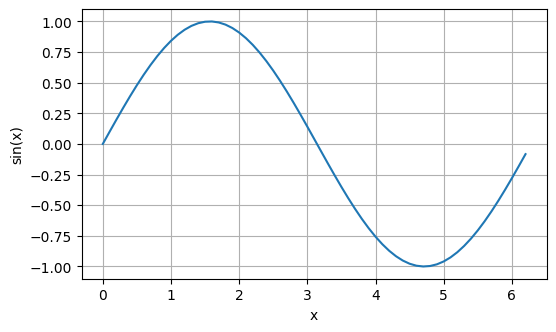

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import sin

a = np.arange(0, 10, 2)
print(a, type(a))
print([0, 1, 2], type([0, 1, 2]))
x = np.arange(0, 2*np.pi, 0.1)
y = sin(x)
plt.figure()
plt.plot(x, y)
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.grid(True)
plt.show()


### 빈칸 문제 14

**문제 상황과 목표**

일정 간격의 숫자 배열을 만들고, 각 x에 대응하는 sin(x)를 구해 사인 곡선을 그리세요.

**주어진 데이터와 변수**

NumPy는 np, Matplotlib는 plt로 가져왔으며 `sin`도 NumPy에서 직접 가져왔습니다. 배열 a는 짝수 다섯 개, x는 라디안 단위의 각도 배열입니다.

**빈칸별 요구사항**

1. `____1____`: 0부터 시작하여 10 미만까지 2씩 증가하는 NumPy 배열 a를 만드세요.
2. `____2____`: 0부터 2π 미만까지 0.1씩 증가하는 x 배열을 만드세요. π는 NumPy 상수를 사용하세요.
3. `____3____`: x 배열의 각 원소에 사인 함수를 적용한 y 배열을 만드세요.

**기대 결과와 확인 기준**

`a == [0,2,4,6,8]`. x와 y의 shape이 같고, 그래프는 (0,0) 근처에서 시작해 한 주기를 그립니다.

**풀이 힌트**

간격을 지정해 배열을 만드는 함수의 인수 순서는 시작, 끝, 간격입니다. NumPy 함수는 배열 전체를 한 번에 계산할 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_14()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


[0 2 4 6 8] <class 'numpy.ndarray'>
[0, 1, 2] <class 'list'>


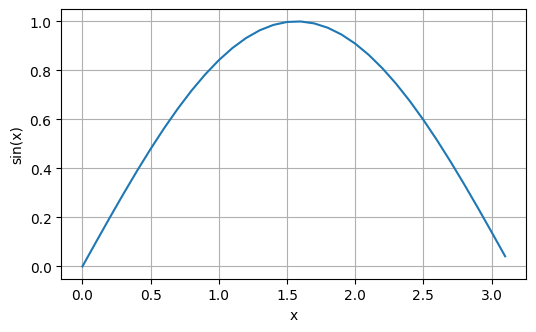

✅ 문제 14 통과


In [33]:
def practice_14():
    import numpy as np
    import matplotlib.pyplot as plt
    from numpy import sin

    a = np.arange(0, 10, 2)
    print(a, type(a))
    print([0, 1, 2], type([0, 1, 2]))
    x = np.arange(0, np.pi, 0.1)
    y = np.sin(x)
    plt.figure()
    plt.plot(x, y)
    plt.xlabel('x')
    plt.ylabel('sin(x)')
    plt.grid(True)
    plt.show()
    assert np.array_equal(a,[0,2,4,6,8])
    assert x.shape == y.shape
    assert np.allclose(y,np.sin(x))
    print("✅ 문제 14 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_14()


<details>
<summary>문제 14 정답과 확인 코드 보기</summary>

- `____1____` → `np.arange(0, 10, 2)`
- `____2____` → `np.arange(0, 2*np.pi, 0.1)`
- `____3____` → `sin(x)`

```python
def practice_14():
    import numpy as np
    import matplotlib.pyplot as plt
    from numpy import sin

    a = np.arange(0, 10, 2)
    print(a, type(a))
    print([0, 1, 2], type([0, 1, 2]))
    x = np.arange(0, 2*np.pi, 0.1)
    y = sin(x)
    plt.figure()
    plt.plot(x, y)
    plt.xlabel('x')
    plt.ylabel('sin(x)')
    plt.grid(True)
    plt.show()
    assert np.array_equal(a,[0,2,4,6,8])
    assert x.shape == y.shape
    assert np.allclose(y,np.sin(x))
    print("✅ 문제 14 통과")

practice_14()
```

</details>


## NumPy 배열

배열 원소는 하나의 dtype으로 저장됩니다. shape은 각 축의 길이이고, ndim은 축의 개수입니다.


<a id="example-15"></a>

## 15. ndarray와 dtype

**출처:** 02번 슬라이드 24

정수·실수가 섞이면 보통 실수 dtype으로 통일됩니다. dtype을 지정해 명시적으로 변환할 수도 있습니다.

> **보완:** 기본 정수 dtype의 비트 수는 실행 환경에 따라 달라질 수 있어 int64 고정 대신 정수형인지 확인합니다.

### 예제 코드


In [34]:
x = np.array([1, 2, 3])
f = np.array([1, 2, 3], dtype='f')
mixed = np.array([1, 2, 3.0])
print(x, x.dtype)
print(f, f.dtype)
print(mixed, mixed.dtype)


[1 2 3] int64
[1. 2. 3.] float32
[1. 2. 3.] float64


### 빈칸 문제 15

**문제 상황과 목표**

같은 숫자를 넣더라도 dtype 지정과 실수 포함 여부에 따라 배열 자료형이 달라지는지 확인하세요.

**주어진 데이터와 변수**

`x`는 정수 1,2,3 배열입니다. f와 mixed에도 값 1,2,3이 들어가되, 두 배열이 실수 자료형이 되도록 생성 과정을 작성합니다.

**빈칸별 요구사항**

1. `____1____`: 리스트 [1,2,3]으로 배열 f를 만들고, 생성할 때 dtype을 float32로 지정하세요.
2. `____2____`: 배열 mixed를 만들 때 1,2는 정수, 마지막 3은 실수 리터럴로 넣으세요. dtype은 따로 지정하지 마세요.

**기대 결과와 확인 기준**

x는 정수 배열, f는 float32 배열, mixed는 float64 배열입니다. f와 mixed를 출력하면 원소에 소수점이 표시됩니다.

**풀이 힌트**

np.array에는 dtype 인수를 줄 수 있고, 코드의 dtype 문자 f는 float32를 뜻합니다. 정수와 실수가 섞이면 하나의 실수 dtype으로 저장됩니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_15()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [35]:
import numpy as np
def practice_15():
    x = np.array([1, 2, 3])
    f = np.array([1, 2, 3], dtype = 'f')
    mixed = np.array([1, 2, 3.])
    print(x, x.dtype)
    print(f, f.dtype)
    print(mixed, mixed.dtype)
    assert np.issubdtype(x.dtype,np.integer)
    assert f.dtype == np.dtype("float32")
    assert mixed.dtype == np.dtype("float64")
    print("✅ 문제 15 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_15()


[1 2 3] int64
[1. 2. 3.] float32
[1. 2. 3.] float64
✅ 문제 15 통과


<details>
<summary>문제 15 정답과 확인 코드 보기</summary>

- `____1____` → `np.array([1, 2, 3], dtype='f')`
- `____2____` → `np.array([1, 2, 3.0])`

```python
def practice_15():
    x = np.array([1, 2, 3])
    f = np.array([1, 2, 3], dtype='f')
    mixed = np.array([1, 2, 3.0])
    print(x, x.dtype)
    print(f, f.dtype)
    print(mixed, mixed.dtype)
    assert np.issubdtype(x.dtype,np.integer)
    assert f.dtype == np.dtype("float32")
    assert mixed.dtype == np.dtype("float64")
    print("✅ 문제 15 통과")

practice_15()
```

</details>


<a id="example-16"></a>

## 16. 2차원 배열·shape·인덱싱·슬라이싱

**출처:** 02번 슬라이드 25

`d[행, 열]`로 하나의 원소, `d[:2, 1:3]`으로 부분 배열을 선택합니다.

### 예제 코드


In [36]:
d = np.array([[1,2,3,4],[5,6,7,8],[9,10,11,12]])
value = d[1, 2]
block = d[:2, 1:3]
tail = d[1:, :3]
print(type(d), d.ndim, d.shape)
print(value)
print(block)
print(tail)


<class 'numpy.ndarray'> 2 (3, 4)
7
[[2 3]
 [6 7]]
[[ 5  6  7]
 [ 9 10 11]]


### 빈칸 문제 16

**문제 상황과 목표**

3행 4열 배열에서 하나의 값과 두 가지 부분 배열을 행·열 인덱스로 선택하세요.

**주어진 데이터와 변수**

`d = [[1,2,3,4],[5,6,7,8],[9,10,11,12]]`입니다. 사람 기준 행·열 번호는 1부터지만 코드의 위치 인덱스는 0부터입니다.

**빈칸별 요구사항**

1. `____1____`: 두 번째 행, 세 번째 열에 있는 값 하나를 value로 꺼내세요.
2. `____2____`: 처음 두 행에서 두 번째·세 번째 열만 선택해 block을 만드세요.
3. `____3____`: 마지막 두 행에서 처음 세 열을 선택해 tail을 만드세요.

**기대 결과와 확인 기준**

`value == 7`, `block == [[2,3],[6,7]]`, `tail == [[5,6,7],[9,10,11]]`. block은 (2,2), tail은 (2,3)입니다.

**풀이 힌트**

배열 인덱스는 대괄호 안에 행 선택과 열 선택을 쉼표로 나눕니다. 슬라이스의 끝 위치는 포함하지 않습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_16()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [37]:
def practice_16():
    d = np.array([[1,2,3,4],[5,6,7,8],[9,10,11,12]])
    value = d[1][2]
    block = d[:2, 1:3]
    tail = d[1:, :3]
    print(type(d), d.ndim, d.shape)
    print(value)
    print(block)
    print(tail)
    assert d.shape == (3,4) and d.ndim == 2
    assert value == 7
    assert np.array_equal(block,[[2,3],[6,7]])
    assert np.array_equal(tail,[[5,6,7],[9,10,11]])
    print("✅ 문제 16 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_16()


<class 'numpy.ndarray'> 2 (3, 4)
7
[[2 3]
 [6 7]]
[[ 5  6  7]
 [ 9 10 11]]
✅ 문제 16 통과


<details>
<summary>문제 16 정답과 확인 코드 보기</summary>

- `____1____` → `d[1, 2]`
- `____2____` → `d[:2, 1:3]`
- `____3____` → `d[1:, :3]`

```python
def practice_16():
    d = np.array([[1,2,3,4],[5,6,7,8],[9,10,11,12]])
    value = d[1, 2]
    block = d[:2, 1:3]
    tail = d[1:, :3]
    print(type(d), d.ndim, d.shape)
    print(value)
    print(block)
    print(tail)
    assert d.shape == (3,4) and d.ndim == 2
    assert value == 7
    assert np.array_equal(block,[[2,3],[6,7]])
    assert np.array_equal(tail,[[5,6,7],[9,10,11]])
    print("✅ 문제 16 통과")

practice_16()
```

</details>


<a id="example-17"></a>

## 17. 벡터화 연산과 리스트 반복의 차이

**출처:** 02번 슬라이드 26

배열의 `2*a`는 원소별 두 배이고 리스트의 `2*L`은 리스트 두 번 연결입니다. 배열 조건은 괄호로 묶고 `&`로 연결합니다.

### 예제 코드


In [38]:
L = [1,2,3,4,5]
L2 = []
for i in L:
    L2.append(2*i)
a = np.array(L)
b = np.array([10,20,30,40,50])
doubled = 2*a
repeated = 2*L
combined = 2*a + b
mask = (a > 2) & (b > 10)
print(L2, doubled, repeated, combined, mask, sep='\n')


[2, 4, 6, 8, 10]
[ 2  4  6  8 10]
[1, 2, 3, 4, 5, 1, 2, 3, 4, 5]
[12 24 36 48 60]
[False False  True  True  True]


### 빈칸 문제 17

**문제 상황과 목표**

같은 두 배 연산이 NumPy 배열과 Python 리스트에서 어떻게 다른지 확인하고, 배열 계산과 조건식을 작성하세요.

**주어진 데이터와 변수**

`L=[1,2,3,4,5]`, a는 L로 만든 NumPy 배열, `b=[10,20,30,40,50]`인 NumPy 배열입니다.

**빈칸별 요구사항**

1. `____1____`: 배열 a의 각 원소를 두 배로 만든 doubled를 계산하세요.
2. `____2____`: 리스트 L 전체를 두 번 이어 붙인 repeated를 만드세요.
3. `____3____`: a의 각 원소를 두 배로 한 값에 같은 위치의 b 원소를 더하세요.
4. `____4____`: 각 위치에서 a가 2보다 크고 b가 10보다 큰지를 동시에 확인하는 불리언 배열을 만드세요.

**기대 결과와 확인 기준**

`doubled=[2,4,6,8,10]`, repeated는 `[1,2,3,4,5,1,2,3,4,5]`, `combined=[12,24,36,48,60]`, `mask=[False,False,True,True,True]`.

**풀이 힌트**

배열의 원소별 조건 결합에는 각각의 비교식을 괄호로 감싼 뒤 `&`를 씁니다. 스칼라용 and를 쓰면 배열의 참·거짓을 하나로 정할 수 없어 오류가 납니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_17()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [39]:
def practice_17():
    L = [1,2,3,4,5]
    L2 = []
    for i in L:
        L2.append(2*i)
    a = np.array(L)
    b = np.array([10,20,30,40,50])
    doubled = a * 2
    repeated = L + L
    combined = doubled + b
    mask = (a > 2) & (b > 10)
    print(L2, doubled, repeated, combined, mask, sep='\n')
    assert np.array_equal(doubled,[2,4,6,8,10])
    assert repeated == L+L
    assert np.array_equal(combined,[12,24,36,48,60])
    assert np.array_equal(mask,[False,False,True,True,True])
    print("✅ 문제 17 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_17()


[2, 4, 6, 8, 10]
[ 2  4  6  8 10]
[1, 2, 3, 4, 5, 1, 2, 3, 4, 5]
[12 24 36 48 60]
[False False  True  True  True]
✅ 문제 17 통과


<details>
<summary>문제 17 정답과 확인 코드 보기</summary>

- `____1____` → `2*a`
- `____2____` → `2*L`
- `____3____` → `2*a + b`
- `____4____` → `(a > 2) & (b > 10)`

```python
def practice_17():
    L = [1,2,3,4,5]
    L2 = []
    for i in L:
        L2.append(2*i)
    a = np.array(L)
    b = np.array([10,20,30,40,50])
    doubled = 2*a
    repeated = 2*L
    combined = 2*a + b
    mask = (a > 2) & (b > 10)
    print(L2, doubled, repeated, combined, mask, sep='\n')
    assert np.array_equal(doubled,[2,4,6,8,10])
    assert repeated == L+L
    assert np.array_equal(combined,[12,24,36,48,60])
    assert np.array_equal(mask,[False,False,True,True,True])
    print("✅ 문제 17 통과")

practice_17()
```

</details>


<a id="example-18"></a>

## 18. 팬시 인덱싱과 불리언 인덱싱

**출처:** 02번 슬라이드 27

정수 배열은 선택할 위치를 나열하고, 불리언 배열은 True인 위치를 선택합니다. 정수 인덱스를 반복하면 같은 원소가 여러 번 나옵니다.

### 예제 코드


In [40]:
a = np.array([11,22,33,44,55,66,77,88,99])
idx = np.array([0,2,4,6,8])
selected = a[idx]
repeated = a[[0,0,0,1,1,1,2,2,3]]
mask = a % 2 == 0
evens = a[mask]
matrix = np.arange(1,13).reshape(3,4)
edges = matrix[:, [True,False,False,True]]
print(selected, repeated, mask, evens, edges, sep='\n')


[11 33 55 77 99]
[11 11 11 22 22 22 33 33 44]
[False  True False  True False  True False  True False]
[22 44 66 88]
[[ 1  4]
 [ 5  8]
 [ 9 12]]


### 빈칸 문제 18

**문제 상황과 목표**

인덱스 목록으로 값을 뽑는 방법과, 조건을 만족하는 값만 뽑는 방법을 각각 완성하세요.

**주어진 데이터와 변수**

`a=[11,22,33,44,55,66,77,88,99]`, 선택 위치 `idx=[0,2,4,6,8]`입니다. matrix는 1부터 12까지를 순서대로 담은 3행 4열 배열입니다.

**빈칸별 요구사항**

1. `____1____`: 정수 인덱스 배열 idx에 적힌 위치의 a 원소들을 selected로 선택하세요.
2. `____2____`: a의 각 원소가 짝수인지 판단한 mask를 만드세요.
3. `____3____`: mask가 True인 위치만 남겨 evens를 만드세요.
4. `____4____`: matrix의 모든 행에서 첫 번째·마지막 열만 남기세요. 열 선택에는 불리언 목록을 사용하세요.

**기대 결과와 확인 기준**

`selected=[11,33,55,77,99]`, `evens=[22,44,66,88]`, `edges=[[1,4],[5,8],[9,12]]`.

**풀이 힌트**

짝수는 2로 나눈 나머지가 0입니다. 불리언 인덱스는 선택할 축의 길이와 같아야 하므로 네 열을 선택하려면 True/False도 네 개입니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_18()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [41]:
def practice_18():
    a = np.array([11,22,33,44,55,66,77,88,99])
    idx = np.array([0,2,4,6,8])
    selected = a[idx]
    repeated = a[[0,0,0,1,1,1,2,2,3]]
    mask = a%2 == 0
    evens = a[mask]
    matrix = np.arange(1,13).reshape(3,4)
    edges = matrix[:, [True, False, False, True]]
    print(selected, repeated, mask, evens, edges, sep='\n')
    assert np.array_equal(selected,[11,33,55,77,99])
    assert np.array_equal(evens,[22,44,66,88])
    assert np.array_equal(edges,[[1,4],[5,8],[9,12]])
    print("✅ 문제 18 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_18()


[11 33 55 77 99]
[11 11 11 22 22 22 33 33 44]
[False  True False  True False  True False  True False]
[22 44 66 88]
[[ 1  4]
 [ 5  8]
 [ 9 12]]
✅ 문제 18 통과


<details>
<summary>문제 18 정답과 확인 코드 보기</summary>

- `____1____` → `a[idx]`
- `____2____` → `a % 2 == 0`
- `____3____` → `a[mask]`
- `____4____` → `matrix[:, [True,False,False,True]]`

```python
def practice_18():
    a = np.array([11,22,33,44,55,66,77,88,99])
    idx = np.array([0,2,4,6,8])
    selected = a[idx]
    repeated = a[[0,0,0,1,1,1,2,2,3]]
    mask = a % 2 == 0
    evens = a[mask]
    matrix = np.arange(1,13).reshape(3,4)
    edges = matrix[:, [True,False,False,True]]
    print(selected, repeated, mask, evens, edges, sep='\n')
    assert np.array_equal(selected,[11,33,55,77,99])
    assert np.array_equal(evens,[22,44,66,88])
    assert np.array_equal(edges,[[1,4],[5,8],[9,12]])
    print("✅ 문제 18 통과")

practice_18()
```

</details>


<a id="example-19"></a>

## 19. zeros·ones·like·empty

**출처:** 02번 슬라이드 28

`zeros_like`·`ones_like`는 기존 배열의 형태를 이용합니다. `empty`는 메모리만 확보해 값이 일정하지 않습니다.

> **보완:** 제목에만 등장하는 ones_like도 짧은 실행 예제를 추가했습니다.

### 예제 코드


In [42]:
a = np.zeros(5)
b = np.ones((3,2), dtype='i')
c = np.zeros_like(b, dtype='f')
same_ones = np.ones_like(b)
d = np.empty((2,3))
print(a, b, c, same_ones, sep='\n')
print('empty shape:', d.shape, '(초기 값은 확인 대상으로 사용하지 않음)')


[0. 0. 0. 0. 0.]
[[1 1]
 [1 1]
 [1 1]]
[[0. 0.]
 [0. 0.]
 [0. 0.]]
[[1 1]
 [1 1]
 [1 1]]
empty shape: (2, 3) (초기 값은 확인 대상으로 사용하지 않음)


### 빈칸 문제 19

**문제 상황과 목표**

원하는 모양·자료형·초기값을 갖는 NumPy 배열 네 가지를 생성하세요.

**주어진 데이터와 변수**

a는 원소 다섯 개, b는 3행 2열, c는 b와 같은 모양이어야 합니다. d는 2행 3열의 저장 공간만 필요합니다.

**빈칸별 요구사항**

1. `____1____`: 0으로 채워진 길이 5의 1차원 배열 a를 만드세요.
2. `____2____`: 1로 채워진 (3,2) 배열 b를 만들고 정수 dtype을 지정하세요.
3. `____3____`: b의 모양을 기준으로 0 배열 c를 만들고, dtype은 float32로 바꾸세요.
4. `____4____`: 초깃값을 채우지 않고 (2,3) 모양의 배열 d를 확보하세요.

**기대 결과와 확인 기준**

a는 0 다섯 개, b는 정수 1 여섯 개, c는 실수 0 여섯 개입니다. d는 shape (2,3)만 확인하며 실제 저장값은 실행마다 달라질 수 있습니다.

**풀이 힌트**

모양을 받는 함수와 기존 배열을 받는 `_like` 함수를 구분하세요. empty는 0을 보장하지 않습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_19()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [43]:
def practice_19():
    a = np.zeros(5)
    b = np.ones((3, 2), dtype = 'i')
    c = np.zeros_like(b, dtype = 'f')
    same_ones = np.ones_like(b)
    d = np.empty((2, 3))
    print(a, b, c, same_ones, sep='\n')
    print('empty shape:', d.shape, '(초기 값은 확인 대상으로 사용하지 않음)')
    assert a.shape == (5,) and np.all(a == 0)
    assert b.shape == (3,2) and np.all(b == 1)
    assert c.shape == b.shape and c.dtype == np.float32 and np.all(c == 0)
    assert d.shape == (2,3)
    print("✅ 문제 19 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_19()


[0. 0. 0. 0. 0.]
[[1 1]
 [1 1]
 [1 1]]
[[0. 0.]
 [0. 0.]
 [0. 0.]]
[[1 1]
 [1 1]
 [1 1]]
empty shape: (2, 3) (초기 값은 확인 대상으로 사용하지 않음)
✅ 문제 19 통과


<details>
<summary>문제 19 정답과 확인 코드 보기</summary>

- `____1____` → `np.zeros(5)`
- `____2____` → `np.ones((3,2), dtype='i')`
- `____3____` → `np.zeros_like(b, dtype='f')`
- `____4____` → `np.empty((2,3))`

```python
def practice_19():
    a = np.zeros(5)
    b = np.ones((3,2), dtype='i')
    c = np.zeros_like(b, dtype='f')
    same_ones = np.ones_like(b)
    d = np.empty((2,3))
    print(a, b, c, same_ones, sep='\n')
    print('empty shape:', d.shape, '(초기 값은 확인 대상으로 사용하지 않음)')
    assert a.shape == (5,) and np.all(a == 0)
    assert b.shape == (3,2) and np.all(b == 1)
    assert c.shape == b.shape and c.dtype == np.float32 and np.all(c == 0)
    assert d.shape == (2,3)
    print("✅ 문제 19 통과")

practice_19()
```

</details>


<a id="example-20"></a>

## 20. arange·linspace·logspace

**출처:** 02번 슬라이드 29

`arange`는 간격, `linspace`는 점 개수, `logspace`는 지수 범위와 점 개수를 지정합니다. linspace·logspace는 기본적으로 끝점을 포함합니다.

### 예제 코드


In [44]:
a = np.arange(10)
odd = np.arange(3,21,2)
linear = np.linspace(0,100,5)
logarithmic = np.logspace(0.1,1,10)
powers = np.logspace(0,5,6,base=2)
print(a, odd, linear, logarithmic, powers, sep='\n')


[0 1 2 3 4 5 6 7 8 9]
[ 3  5  7  9 11 13 15 17 19]
[  0.  25.  50.  75. 100.]
[ 1.2589  1.5849  1.9953  2.5119  3.1623  3.9811  5.0119  6.3096  7.9433
 10.    ]
[ 1.  2.  4.  8. 16. 32.]


### 빈칸 문제 20

**문제 상황과 목표**

간격·점 개수·지수 범위를 각각 기준으로 숫자 배열을 생성하세요.

**주어진 데이터와 변수**

odd는 3부터 19까지의 홀수, linear는 0부터 100까지의 균등한 다섯 지점, powers는 2의 0제곱부터 5제곱까지입니다.

**빈칸별 요구사항**

1. `____1____`: 시작 3, 끝 21 미만, 간격 2로 odd를 만드세요.
2. `____2____`: 양 끝 0과 100을 포함하여 총 다섯 지점을 linear로 만드세요.
3. `____3____`: 밑은 2, 지수는 0부터 5까지, 지수의 점 개수는 여섯 개로 powers를 만드세요.

**기대 결과와 확인 기준**

`odd=[3,5,7,9,11,13,15,17,19]`, `linear=[0,25,50,75,100]`, `powers=[1,2,4,8,16,32]`.

**풀이 힌트**

arange의 세 번째 인수는 간격이고, linspace·logspace의 세 번째 인수는 개수입니다. logspace의 시작·끝은 최종 값이 아니라 지수입니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_20()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [45]:
def practice_20():
    a = np.arange(10)
    odd = np.arange(3, 21, 2)
    linear = np.linspace(0, 100, 5)
    logarithmic = np.logspace(0.1,1,10)
    powers = np.logspace(0, 5, 6, base = 2) # start, end, size, 2 ** i
    print(a, odd, linear, logarithmic, powers, sep='\n')
    assert np.array_equal(odd,[3,5,7,9,11,13,15,17,19])
    assert np.allclose(linear,[0,25,50,75,100])
    assert np.allclose(powers,[1,2,4,8,16,32])
    print("✅ 문제 20 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_20()


[0 1 2 3 4 5 6 7 8 9]
[ 3  5  7  9 11 13 15 17 19]
[  0.  25.  50.  75. 100.]
[ 1.2589  1.5849  1.9953  2.5119  3.1623  3.9811  5.0119  6.3096  7.9433
 10.    ]
[ 1.  2.  4.  8. 16. 32.]
✅ 문제 20 통과


<details>
<summary>문제 20 정답과 확인 코드 보기</summary>

- `____1____` → `np.arange(3,21,2)`
- `____2____` → `np.linspace(0,100,5)`
- `____3____` → `np.logspace(0,5,6,base=2)`

```python
def practice_20():
    a = np.arange(10)
    odd = np.arange(3,21,2)
    linear = np.linspace(0,100,5)
    logarithmic = np.logspace(0.1,1,10)
    powers = np.logspace(0,5,6,base=2)
    print(a, odd, linear, logarithmic, powers, sep='\n')
    assert np.array_equal(odd,[3,5,7,9,11,13,15,17,19])
    assert np.allclose(linear,[0,25,50,75,100])
    assert np.allclose(powers,[1,2,4,8,16,32])
    print("✅ 문제 20 통과")

practice_20()
```

</details>


<a id="example-21"></a>

## 21. 전치·reshape·flatten·ravel

**출처:** 02번 슬라이드 30

전치는 축을 바꾸고 reshape는 원소 순서를 유지해 형태를 바꿉니다. `-1`은 나머지 길이를 자동 계산합니다. flatten은 복사본을 만들고 ravel은 가능한 경우 뷰를 반환합니다.

### 예제 코드


In [46]:
a = np.array([[1,2,3],[4,5,6]])
transposed = a.T
reshaped = a.reshape(3,2)
row = a.reshape(1,-1)
flat = a.flatten()
raveled = a.ravel()
print(transposed, reshaped, row, flat, raveled, sep='\n')


[[1 4]
 [2 5]
 [3 6]]
[[1 2]
 [3 4]
 [5 6]]
[[1 2 3 4 5 6]]
[1 2 3 4 5 6]
[1 2 3 4 5 6]


### 빈칸 문제 21

**문제 상황과 목표**

원소 순서와 축의 의미를 구분하며 2차원 배열의 형태를 바꾸세요.

**주어진 데이터와 변수**

`a=[[1,2,3],[4,5,6]]`는 (2,3) 배열입니다. 원소 개수 여섯 개를 유지해야 합니다.

**빈칸별 요구사항**

1. `____1____`: a의 행과 열을 서로 바꾼 전치 배열을 만드세요.
2. `____2____`: 원소를 행 순서대로 읽은 순서를 유지하면서 (3,2)로 바꾸세요.
3. `____3____`: 행이 하나인 2차원 배열로 바꾸되, 열 개수는 -1로 자동 계산하게 하세요.
4. `____4____`: a를 길이 6의 1차원 복사 배열로 펼치세요.

**기대 결과와 확인 기준**

전치는 `[[1,4],[2,5],[3,6]]`, reshape는 `[[1,2],[3,4],[5,6]]`입니다. row의 shape은 (1,6), flat의 shape은 (6,)입니다.

**풀이 힌트**

전치와 reshape는 같은 연산이 아닙니다. 전치는 T 속성, reshape·flatten은 호출하는 메서드입니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_21()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [47]:
def practice_21():
    a = np.array([[1,2,3],[4,5,6]])
    transposed = a.T
    reshaped = a.reshape(3, 2)
    row = a.reshape(1, -1)
    flat = a.flatten()
    raveled = a.ravel()
    print(transposed, reshaped, row, flat, raveled, sep='\n')
    assert np.array_equal(transposed,[[1,4],[2,5],[3,6]])
    assert np.array_equal(reshaped,[[1,2],[3,4],[5,6]])
    assert row.shape == (1,6)
    assert np.array_equal(flat,[1,2,3,4,5,6])
    print("✅ 문제 21 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_21()


[[1 4]
 [2 5]
 [3 6]]
[[1 2]
 [3 4]
 [5 6]]
[[1 2 3 4 5 6]]
[1 2 3 4 5 6]
[1 2 3 4 5 6]
✅ 문제 21 통과


<details>
<summary>문제 21 정답과 확인 코드 보기</summary>

- `____1____` → `a.T`
- `____2____` → `a.reshape(3,2)`
- `____3____` → `a.reshape(1,-1)`
- `____4____` → `a.flatten()`

```python
def practice_21():
    a = np.array([[1,2,3],[4,5,6]])
    transposed = a.T
    reshaped = a.reshape(3,2)
    row = a.reshape(1,-1)
    flat = a.flatten()
    raveled = a.ravel()
    print(transposed, reshaped, row, flat, raveled, sep='\n')
    assert np.array_equal(transposed,[[1,4],[2,5],[3,6]])
    assert np.array_equal(reshaped,[[1,2],[3,4],[5,6]])
    assert row.shape == (1,6)
    assert np.array_equal(flat,[1,2,3,4,5,6])
    print("✅ 문제 21 통과")

practice_21()
```

</details>


<a id="example-22"></a>

## 22. 통계·정렬·정렬 인덱스

**출처:** 02번 슬라이드 31

`argmin`은 값의 위치, `argsort`는 정렬 순서의 위치 배열을 반환합니다. `np.sort(x)`는 새 배열을 반환하고 `x.sort()`는 x 자체를 바꿉니다.

> **보완:** 원본의 Python 2 스타일 __builtin__ 대신 Python 3의 __builtins__를 안내했습니다.

### 예제 코드


In [48]:
x = np.array([7,3,8,1,5,9])
stats = (np.sum(x), x.sum(), x.max(), x.argmin(), x.mean())
sorted_copy = np.sort(x)
order = np.argsort(x)
print('통계:', stats)
print('새 정렬 배열:', sorted_copy)
print('정렬 인덱스:', order)
before = x.copy()
print('원본:', x)
x.sort()
print('메서드 정렬 뒤:', x)
# 확인용: dir(x), help(x.sort), dir(__builtins__)


통계: (np.int64(33), np.int64(33), np.int64(9), np.int64(3), np.float64(5.5))
새 정렬 배열: [1 3 5 7 8 9]
정렬 인덱스: [3 1 4 0 2 5]
원본: [7 3 8 1 5 9]
메서드 정렬 뒤: [1 3 5 7 8 9]


### 빈칸 문제 22

**문제 상황과 목표**

값 자체, 값이 있는 위치, 정렬한 결과를 구분해 배열을 분석하세요.

**주어진 데이터와 변수**

`x=[7,3,8,1,5,9]`입니다. stats 튜플의 다른 항목과 x를 직접 정렬하는 마지막 코드는 이미 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: x에서 가장 작은 값의 **위치 번호**를 구하세요. 최솟값 1 자체를 구하는 문제가 아닙니다.
2. `____2____`: x의 산술평균을 구하세요.
3. `____3____`: 원래 x는 바꾸지 않고 오름차순으로 정렬한 새 배열을 만드세요.
4. `____4____`: x를 오름차순으로 만들 때 원소를 읽어야 할 원래 위치의 순서를 구하세요.

**기대 결과와 확인 기준**

최솟값 위치는 3, 평균은 5.5, 정렬 결과는 `[1,3,5,7,8,9]`, 정렬 인덱스는 `[3,1,4,0,2,5]`입니다.

**풀이 힌트**

min과 argmin, sort와 argsort의 반환값 차이를 생각하세요. np.sort는 새 배열을, x.sort()는 원본 변경을 수행합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_22()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [49]:
def practice_22():
    x = np.array([7,3,8,1,5,9])
    stats = (np.sum(x), x.sum(), x.max(), x.argmin(), np.mean(x))
    sorted_copy = np.sort(x)
    order = x.argsort()
    print('통계:', stats)
    print('새 정렬 배열:', sorted_copy)
    print('정렬 인덱스:', order)
    before = x.copy()
    print('원본:', x)
    x.sort()
    print('메서드 정렬 뒤:', x)
    # 확인용: dir(x), help(x.sort), dir(__builtins__)
    assert stats == (33,33,9,3,5.5)
    assert np.array_equal(order,[3,1,4,0,2,5])
    assert np.array_equal(before,[7,3,8,1,5,9])
    assert np.array_equal(x,sorted_copy)
    print("✅ 문제 22 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_22()


통계: (np.int64(33), np.int64(33), np.int64(9), np.int64(3), np.float64(5.5))
새 정렬 배열: [1 3 5 7 8 9]
정렬 인덱스: [3 1 4 0 2 5]
원본: [7 3 8 1 5 9]
메서드 정렬 뒤: [1 3 5 7 8 9]
✅ 문제 22 통과


<details>
<summary>문제 22 정답과 확인 코드 보기</summary>

- `____1____` → `x.argmin()`
- `____2____` → `x.mean()`
- `____3____` → `np.sort(x)`
- `____4____` → `np.argsort(x)`

```python
def practice_22():
    x = np.array([7,3,8,1,5,9])
    stats = (np.sum(x), x.sum(), x.max(), x.argmin(), x.mean())
    sorted_copy = np.sort(x)
    order = np.argsort(x)
    print('통계:', stats)
    print('새 정렬 배열:', sorted_copy)
    print('정렬 인덱스:', order)
    before = x.copy()
    print('원본:', x)
    x.sort()
    print('메서드 정렬 뒤:', x)
    # 확인용: dir(x), help(x.sort), dir(__builtins__)
    assert stats == (33,33,9,3,5.5)
    assert np.array_equal(order,[3,1,4,0,2,5])
    assert np.array_equal(before,[7,3,8,1,5,9])
    assert np.array_equal(x,sorted_copy)
    print("✅ 문제 22 통과")

practice_22()
```

</details>


<a id="example-23"></a>

## 23. 3차원 배열의 axis별 합

**출처:** 02번 슬라이드 32

`axis=k`로 합을 구하면 k축이 사라집니다. shape `(2,2,3)`에서 axis 2·1·0의 합은 각각 `(2,2)`·`(2,3)`·`(2,3)`입니다.

### 예제 코드


In [50]:
d = np.arange(1,13).reshape(2,2,3)
total = d.sum()
axis2 = d.sum(axis=2)
axis1 = d.sum(axis=1)
axis0 = d.sum(axis=0)
d1 = d[0]
print(total, axis2, axis1, axis0, sep='\n')
print('d1의 axis 1:', d1.sum(axis=1))
print('d1의 axis 0:', d1.sum(axis=0))


78
[[ 6 15]
 [24 33]]
[[ 5  7  9]
 [17 19 21]]
[[ 8 10 12]
 [14 16 18]]
d1의 axis 1: [ 6 15]
d1의 axis 0: [5 7 9]


### 빈칸 문제 23

**문제 상황과 목표**

3차원 배열에서 축을 하나씩 줄이며, 어떤 원소끼리 더하는지 확인하세요.

**주어진 데이터와 변수**

`d=[[[1,2,3],[4,5,6]],[[7,8,9],[10,11,12]]]`, shape은 (2,2,3)입니다. axis 0은 두 묶음, axis 1은 각 묶음의 행, axis 2는 각 행 안의 열입니다.

**빈칸별 요구사항**

1. `____1____`: 각 행 안의 세 숫자를 합하세요. 예를 들어 1+2+3=6, 4+5+6=15가 되도록 합산할 축을 정하세요.
2. `____2____`: 각 묶음 안에서 두 행의 같은 열끼리 합하세요. 첫 묶음은 [1+4,2+5,3+6]이 됩니다.
3. `____3____`: 두 묶음의 같은 행·열끼리 합하세요. 첫 행은 [1+7,2+8,3+9]가 됩니다.

**기대 결과와 확인 기준**

`axis2=[[6,15],[24,33]]`, `axis1=[[5,7,9],[17,19,21]]`, `axis0=[[8,10,12],[14,16,18]]`. 전체 합은 78입니다.

**풀이 힌트**

`sum(axis=...)`의 axis는 결과에 남길 축이 아니라 합쳐서 없앨 축입니다. 원래 shape에서 그 축의 길이를 지워 결과 shape을 예상하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_23()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [51]:
def practice_23():
    d = np.arange(1,13).reshape(2,2,3)
    total = d.sum()
    axis2 = d.sum(axis = 2)
    axis1 = d.sum(axis = 1)
    axis0 = d.sum(axis = 0)
    d1 = d[0]
    print(total, axis2, axis1, axis0, sep='\n')
    print('d1의 axis 1:', d1.sum(axis=1))
    print('d1의 axis 0:', d1.sum(axis=0))
    assert total == 78
    assert np.array_equal(axis2,[[6,15],[24,33]])
    assert np.array_equal(axis1,[[5,7,9],[17,19,21]])
    assert np.array_equal(axis0,[[8,10,12],[14,16,18]])
    print("✅ 문제 23 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_23()


78
[[ 6 15]
 [24 33]]
[[ 5  7  9]
 [17 19 21]]
[[ 8 10 12]
 [14 16 18]]
d1의 axis 1: [ 6 15]
d1의 axis 0: [5 7 9]
✅ 문제 23 통과


<details>
<summary>문제 23 정답과 확인 코드 보기</summary>

- `____1____` → `d.sum(axis=2)`
- `____2____` → `d.sum(axis=1)`
- `____3____` → `d.sum(axis=0)`

```python
def practice_23():
    d = np.arange(1,13).reshape(2,2,3)
    total = d.sum()
    axis2 = d.sum(axis=2)
    axis1 = d.sum(axis=1)
    axis0 = d.sum(axis=0)
    d1 = d[0]
    print(total, axis2, axis1, axis0, sep='\n')
    print('d1의 axis 1:', d1.sum(axis=1))
    print('d1의 axis 0:', d1.sum(axis=0))
    assert total == 78
    assert np.array_equal(axis2,[[6,15],[24,33]])
    assert np.array_equal(axis1,[[5,7,9],[17,19,21]])
    assert np.array_equal(axis0,[[8,10,12],[14,16,18]])
    print("✅ 문제 23 통과")

practice_23()
```

</details>


<a id="example-24"></a>

## 24. hstack·vstack·r_·c_

**출처:** 02번 슬라이드 33–34

2차원에서 hstack·c_는 좌우, vstack·r_는 위아래 결합입니다. 1차원 c_는 각 벡터를 열로 묶습니다.

### 예제 코드


In [52]:
a = np.array([[1,2],[3,4]])
b = np.array([[5,6],[7,8]])
h = np.hstack([a,b])
v = np.vstack([a,b])
r = np.r_[a,b]
c = np.c_[a,b]
u = np.array([1,2,3])
w = np.array([5,6,7])
print(h, v, r, c, np.r_[u,w], np.c_[u,w], sep='\n')


[[1 2 5 6]
 [3 4 7 8]]
[[1 2]
 [3 4]
 [5 6]
 [7 8]]
[[1 2]
 [3 4]
 [5 6]
 [7 8]]
[[1 2 5 6]
 [3 4 7 8]]
[1 2 3 5 6 7]
[[1 5]
 [2 6]
 [3 7]]


### 빈칸 문제 24

**문제 상황과 목표**

두 2차원 배열을 좌우로 붙이는 방법과 위아래로 붙이는 방법을 두 문법씩 작성하세요.

**주어진 데이터와 변수**

`a=[[1,2],[3,4]]`, `b=[[5,6],[7,8]]`이며 둘 다 (2,2)입니다. 추가로 1차원 벡터 u와 w를 결합하는 예제는 그대로 실행합니다.

**빈칸별 요구사항**

1. `____1____`: hstack을 사용해 a 오른쪽에 b를 붙여 h를 만드세요.
2. `____2____`: vstack을 사용해 a 아래에 b를 붙여 v를 만드세요.
3. `____3____`: r_ 표기법으로 v와 같은 결과를 만드세요.
4. `____4____`: c_ 표기법으로 h와 같은 결과를 만드세요.

**기대 결과와 확인 기준**

`h=c=[[1,2,5,6],[3,4,7,8]]`로 shape (2,4), `v=r=[[1,2],[3,4],[5,6],[7,8]]`로 shape (4,2)입니다.

**풀이 힌트**

stack 계열에는 결합할 배열들을 리스트로 전달합니다. r_와 c_는 함수 괄호 대신 대괄호로 인덱싱하듯 작성합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_24()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [53]:
def practice_24():
    a = np.array([[1,2],[3,4]])
    b = np.array([[5,6],[7,8]])
    h = np.hstack([a, b]) # 수평 결합, 리스트로 주기
    v = np.vstack([a, b]) # 수직 결합
    r = np.r_[a, b]
    c = np.c_[a, b] # r_, c_는 []로 인수 주기
    u = np.array([1,2,3])
    w = np.array([5,6,7])
    print(h, v, r, c, np.r_[u,w], np.c_[u,w], sep='\n')
    assert np.array_equal(h,[[1,2,5,6],[3,4,7,8]])
    assert np.array_equal(v,[[1,2],[3,4],[5,6],[7,8]])
    assert np.array_equal(r,v) and np.array_equal(c,h)
    print("✅ 문제 24 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_24()


[[1 2 5 6]
 [3 4 7 8]]
[[1 2]
 [3 4]
 [5 6]
 [7 8]]
[[1 2]
 [3 4]
 [5 6]
 [7 8]]
[[1 2 5 6]
 [3 4 7 8]]
[1 2 3 5 6 7]
[[1 5]
 [2 6]
 [3 7]]
✅ 문제 24 통과


<details>
<summary>문제 24 정답과 확인 코드 보기</summary>

- `____1____` → `np.hstack([a,b])`
- `____2____` → `np.vstack([a,b])`
- `____3____` → `np.r_[a,b]`
- `____4____` → `np.c_[a,b]`

```python
def practice_24():
    a = np.array([[1,2],[3,4]])
    b = np.array([[5,6],[7,8]])
    h = np.hstack([a,b])
    v = np.vstack([a,b])
    r = np.r_[a,b]
    c = np.c_[a,b]
    u = np.array([1,2,3])
    w = np.array([5,6,7])
    print(h, v, r, c, np.r_[u,w], np.c_[u,w], sep='\n')
    assert np.array_equal(h,[[1,2,5,6],[3,4,7,8]])
    assert np.array_equal(v,[[1,2],[3,4],[5,6],[7,8]])
    assert np.array_equal(r,v) and np.array_equal(c,h)
    print("✅ 문제 24 통과")

practice_24()
```

</details>


<a id="example-25"></a>

## 25. tile로 배열 반복

**출처:** 02번 슬라이드 34

`tile(a, 2)`는 마지막 축 방향으로 두 번, `tile(a, (2,3))`는 행·열 방향으로 각각 두 번·세 번 반복합니다.

### 예제 코드


In [54]:
a = np.array([[1,2],[3,4]])
twice = np.tile(a,2)
grid = np.tile(a,(2,3))
print(twice)
print(grid)


[[1 2 1 2]
 [3 4 3 4]]
[[1 2 1 2 1 2]
 [3 4 3 4 3 4]
 [1 2 1 2 1 2]
 [3 4 3 4 3 4]]


### 빈칸 문제 25

**문제 상황과 목표**

작은 2차원 배열을 타일처럼 반복 배치해 더 큰 배열을 만드세요.

**주어진 데이터와 변수**

`a=[[1,2],[3,4]]`입니다. twice와 grid 모두 원래 2×2 묶음이 반복되어야 합니다.

**빈칸별 요구사항**

1. `____1____`: a를 좌우 방향으로 두 번 반복하여 (2,4) 배열 twice를 만드세요.
2. `____2____`: a를 위아래로 두 번, 좌우로 세 번 반복하여 (4,6) 배열 grid를 만드세요.

**기대 결과와 확인 기준**

`twice=[[1,2,1,2],[3,4,3,4]]`. grid의 첫 두 행은 `[1,2,1,2,1,2]`, `[3,4,3,4,3,4]`이고 이 두 행이 한 번 더 반복됩니다.

**풀이 힌트**

tile의 반복 횟수를 튜플로 줄 때 순서는 행 방향, 열 방향입니다. 원소 하나씩 반복하는 연산과 배열 전체를 반복하는 연산을 구분하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_25()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [55]:
def practice_25():
    a = np.array([[1,2],[3,4]])
    twice = np.tile(a, (1, 2))
    grid = np.tile(a, (2, 3))
    print(twice)
    print(grid)
    assert np.array_equal(twice,[[1,2,1,2],[3,4,3,4]])
    assert grid.shape == (4,6)
    assert np.array_equal(grid,np.vstack([np.hstack([a,a,a])]*2))
    print("✅ 문제 25 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_25()


[[1 2 1 2]
 [3 4 3 4]]
[[1 2 1 2 1 2]
 [3 4 3 4 3 4]
 [1 2 1 2 1 2]
 [3 4 3 4 3 4]]
✅ 문제 25 통과


<details>
<summary>문제 25 정답과 확인 코드 보기</summary>

- `____1____` → `np.tile(a,2)`
- `____2____` → `np.tile(a,(2,3))`

```python
def practice_25():
    a = np.array([[1,2],[3,4]])
    twice = np.tile(a,2)
    grid = np.tile(a,(2,3))
    print(twice)
    print(grid)
    assert np.array_equal(twice,[[1,2,1,2],[3,4,3,4]])
    assert grid.shape == (4,6)
    assert np.array_equal(grid,np.vstack([np.hstack([a,a,a])]*2))
    print("✅ 문제 25 통과")

practice_25()
```

</details>


<a id="example-26"></a>

## 26. meshgrid와 좌표 쌍

**출처:** 02번 슬라이드 35

meshgrid는 x·y 축의 모든 조합을 격자로 만듭니다. `zip`을 두 번 사용하면 각 행의 좌표 쌍을 만들 수 있습니다.

### 예제 코드


In [56]:
a = np.array([0,1,2])
b = np.array([0,1,2,3,4])
X, Y = np.meshgrid(a,b)
pairs = [list(zip(x,y)) for x,y in zip(X,Y)]
print(X)
print(Y)
print(pairs)


[[0 1 2]
 [0 1 2]
 [0 1 2]
 [0 1 2]
 [0 1 2]]
[[0 0 0]
 [1 1 1]
 [2 2 2]
 [3 3 3]
 [4 4 4]]
[[(np.int64(0), np.int64(0)), (np.int64(1), np.int64(0)), (np.int64(2), np.int64(0))], [(np.int64(0), np.int64(1)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(1))], [(np.int64(0), np.int64(2)), (np.int64(1), np.int64(2)), (np.int64(2), np.int64(2))], [(np.int64(0), np.int64(3)), (np.int64(1), np.int64(3)), (np.int64(2), np.int64(3))], [(np.int64(0), np.int64(4)), (np.int64(1), np.int64(4)), (np.int64(2), np.int64(4))]]


### 빈칸 문제 26

**문제 상황과 목표**

x축·y축 후보의 모든 조합을 격자로 만들고, 각 격자 행을 (x,y) 좌표 목록으로 바꾸세요.

**주어진 데이터와 변수**

`a=[0,1,2]`는 x 후보 세 개, `b=[0,1,2,3,4]`는 y 후보 다섯 개입니다. 따라서 좌표 쌍은 총 15개입니다.

**빈칸별 요구사항**

1. `____1____`: a와 b로 X, Y 두 좌표 격자를 만드세요. X와 Y의 shape은 둘 다 (5,3)이어야 합니다.
2. `____2____`: X와 Y의 같은 위치 원소를 zip으로 묶되, 바깥 리스트는 y별 행, 안쪽 리스트는 그 행의 세 (x,y) 쌍이 되게 만드세요.

**기대 결과와 확인 기준**

첫 행은 `[(0,0),(1,0),(2,0)]`, 마지막 행은 `[(0,4),(1,4),(2,4)]`입니다. 바깥 길이는 5, 각 행의 길이는 3입니다.

**풀이 힌트**

먼저 두 격자의 행끼리 zip으로 묶고, 그 안에서 해당 x행과 y행의 원소끼리 다시 zip으로 묶습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_26()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [57]:
def practice_26():
    a = np.array([0,1,2])
    b = np.array([0,1,2,3,4])
    X, Y = np.meshgrid(a, b)
    pairs = [list(zip(x,y)) for x, y in zip(X, Y)]
    print(X)
    print(Y)
    print(pairs)
    assert X.shape == Y.shape == (5,3)
    assert pairs[0] == [(0,0),(1,0),(2,0)]
    assert pairs[-1] == [(0,4),(1,4),(2,4)]
    print("✅ 문제 26 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_26()


[[0 1 2]
 [0 1 2]
 [0 1 2]
 [0 1 2]
 [0 1 2]]
[[0 0 0]
 [1 1 1]
 [2 2 2]
 [3 3 3]
 [4 4 4]]
[[(np.int64(0), np.int64(0)), (np.int64(1), np.int64(0)), (np.int64(2), np.int64(0))], [(np.int64(0), np.int64(1)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(1))], [(np.int64(0), np.int64(2)), (np.int64(1), np.int64(2)), (np.int64(2), np.int64(2))], [(np.int64(0), np.int64(3)), (np.int64(1), np.int64(3)), (np.int64(2), np.int64(3))], [(np.int64(0), np.int64(4)), (np.int64(1), np.int64(4)), (np.int64(2), np.int64(4))]]
✅ 문제 26 통과


<details>
<summary>문제 26 정답과 확인 코드 보기</summary>

- `____1____` → `np.meshgrid(a,b)`
- `____2____` → `[list(zip(x,y)) for x,y in zip(X,Y)]`

```python
def practice_26():
    a = np.array([0,1,2])
    b = np.array([0,1,2,3,4])
    X, Y = np.meshgrid(a,b)
    pairs = [list(zip(x,y)) for x,y in zip(X,Y)]
    print(X)
    print(Y)
    print(pairs)
    assert X.shape == Y.shape == (5,3)
    assert pairs[0] == [(0,0),(1,0),(2,0)]
    assert pairs[-1] == [(0,4),(1,4),(2,4)]
    print("✅ 문제 26 통과")

practice_26()
```

</details>


<a id="example-27"></a>

## 27. 균일·정규·정수 난수

**출처:** 02번 슬라이드 36

`rand`는 [0,1) 균일분포, `randn`은 표준정규분포, `randint(low, high)`는 high 미만 정수입니다.

### 예제 코드


In [58]:
np.random.seed(36)
uniform = np.random.rand(5)
matrix = np.random.rand(2,3)
normal = np.random.randn(10)
integers = np.random.randint(10,20,size=10)
integer_matrix = np.random.randint(20,size=(2,5))
print(uniform, matrix, normal, integers, integer_matrix, sep='\n')


[0.7285 0.6016 0.9522 0.1432 0.8074]
[[0.3632 0.1866 0.2592]
 [0.6298 0.0326 0.9472]]
[ 0.1114  0.8982 -0.61   -0.6898 -0.8151 -2.1502 -0.2531 -1.6117  0.6402
 -1.0849]
[15 10 17 13 18 12 12 14 14 13]
[[17 17 19  4 18]
 [ 6 12  8  0  8]]


### 빈칸 문제 27

**문제 상황과 목표**

세 가지 분포에서 정해진 개수와 모양으로 난수를 생성하세요. 난수의 특정 숫자를 맞히는 문제가 아닙니다.

**주어진 데이터와 변수**

시드는 36으로 고정되어 있습니다. matrix는 (2,3), normal과 integers는 각각 원소 10개가 필요합니다.

**빈칸별 요구사항**

1. `____1____`: 0 이상 1 미만의 균일분포에서 2행 3열 배열 matrix를 생성하세요.
2. `____2____`: 평균 0·표준편차 1인 표준정규분포에서 난수 10개를 생성하세요.
3. `____3____`: 10 이상 20 미만의 정수 난수 10개를 생성하세요.

**기대 결과와 확인 기준**

matrix는 (2,3), normal과 integers는 (10,)입니다. integers의 모든 값은 10–19입니다. 정규 난수 표본의 평균·표준편차가 정확히 0·1일 필요는 없습니다.

**풀이 힌트**

rand와 randn은 차원의 길이를 각각의 인수로 받고, randint는 범위 뒤에 size로 모양을 지정합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_27()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [59]:
def practice_27():
    np.random.seed(36)
    uniform = np.random.rand(5)
    matrix = np.random.rand(2, 3)
    normal = np.random.randn(10)
    integers = np.random.randint(10, 20, size = 10)
    integer_matrix = np.random.randint(20,size=(2,5))
    print(uniform, matrix, normal, integers, integer_matrix, sep='\n')
    assert matrix.shape == (2,3) and np.all((matrix >= 0)&(matrix < 1))
    assert normal.shape == (10,)
    assert integers.shape == (10,) and np.all((integers >= 10)&(integers < 20))
    print("✅ 문제 27 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_27()


[0.7285 0.6016 0.9522 0.1432 0.8074]
[[0.3632 0.1866 0.2592]
 [0.6298 0.0326 0.9472]]
[ 0.1114  0.8982 -0.61   -0.6898 -0.8151 -2.1502 -0.2531 -1.6117  0.6402
 -1.0849]
[15 10 17 13 18 12 12 14 14 13]
[[17 17 19  4 18]
 [ 6 12  8  0  8]]
✅ 문제 27 통과


<details>
<summary>문제 27 정답과 확인 코드 보기</summary>

- `____1____` → `np.random.rand(2,3)`
- `____2____` → `np.random.randn(10)`
- `____3____` → `np.random.randint(10,20,size=10)`

```python
def practice_27():
    np.random.seed(36)
    uniform = np.random.rand(5)
    matrix = np.random.rand(2,3)
    normal = np.random.randn(10)
    integers = np.random.randint(10,20,size=10)
    integer_matrix = np.random.randint(20,size=(2,5))
    print(uniform, matrix, normal, integers, integer_matrix, sep='\n')
    assert matrix.shape == (2,3) and np.all((matrix >= 0)&(matrix < 1))
    assert normal.shape == (10,)
    assert integers.shape == (10,) and np.all((integers >= 10)&(integers < 20))
    print("✅ 문제 27 통과")

practice_27()
```

</details>


<a id="example-28"></a>

## 28. shuffle·choice·중복·확률

**출처:** 02번 슬라이드 37

`shuffle`은 배열을 직접 섞고 None을 반환합니다. choice의 replace=False는 중복 없는 추출, p는 각 원소의 선택 확률입니다.

### 예제 코드


In [60]:
np.random.seed(37)
x = np.arange(10)
np.random.shuffle(x)
sampled = np.random.choice(x,5,replace=False)
permutation = np.random.choice(5,5,replace=False)
replacement = np.random.choice(5,10)
weighted = np.random.choice(4,10,p=[0.1,0,0.3,0.6])
print(x, sampled, permutation, replacement, weighted, sep='\n')


[4 9 0 1 7 8 3 2 6 5]
[9 3 8 5 7]
[3 4 0 1 2]
[3 0 4 1 2 3 2 3 4 3]
[0 2 2 2 3 3 2 3 2 3]


### 빈칸 문제 28

**문제 상황과 목표**

섞인 배열에서 중복 없는 표본을 뽑고, 전체 순열과 가중 추출도 만들어 보세요.

**주어진 데이터와 변수**

x는 0부터 9까지를 shuffle로 섞은 배열입니다. 확률 추출의 후보는 0,1,2,3이며 각 확률은 0.1,0,0.3,0.6입니다.

**빈칸별 요구사항**

1. `____1____`: x에서 서로 다른 원소 다섯 개를 뽑으세요. 같은 원소가 중복 선택되면 안 됩니다.
2. `____2____`: 0부터 4까지를 각각 정확히 한 번 포함하는 순서가 무작위인 배열을 만드세요.
3. `____3____`: 후보 0,1,2,3에서 지정한 확률에 따라 열 번 뽑으세요. 이 추출은 중복을 허용합니다.

**기대 결과와 확인 기준**

sampled의 서로 다른 값은 다섯 개, permutation을 정렬하면 `[0,1,2,3,4]`입니다. weighted에 확률 0인 값 1은 없어야 합니다. 각 후보의 실제 등장 횟수는 확률과 정확히 같을 필요가 없습니다.

**풀이 힌트**

choice의 replace=False는 중복 금지입니다. 첫 인수로 정수 k를 주면 후보는 0부터 k−1까지이고, p는 후보 순서대로 확률을 담습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_28()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [61]:
def practice_28():
    np.random.seed(37)
    x = np.arange(10)
    np.random.shuffle(x)
    sampled = np.random.choice(x, size = 5, replace = False)
    permutation = np.random.choice(range(5), size = 5, replace = False)
    replacement = np.random.choice(5,10)
    weighted = np.random.choice(range(4), 10, replace = True, p = [0.5, 0.2, 0.1, 0.2])
    print(x, sampled, permutation, replacement, weighted, sep='\n')
    assert np.array_equal(np.sort(x),np.arange(10))
    assert len(np.unique(sampled)) == 5
    assert np.array_equal(np.sort(permutation),np.arange(5))
    assert not np.any(weighted == 1)
    print("✅ 문제 28 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_28()


[4 9 0 1 7 8 3 2 6 5]
[9 3 8 5 7]
[3 4 0 1 2]
[3 0 4 1 2 3 2 3 4 3]
[0 0 0 0 3 3 0 0 0 3]
✅ 문제 28 통과


<details>
<summary>문제 28 정답과 확인 코드 보기</summary>

- `____1____` → `np.random.choice(x,5,replace=False)`
- `____2____` → `np.random.choice(5,5,replace=False)`
- `____3____` → `np.random.choice(4,10,p=[0.1,0,0.3,0.6])`

```python
def practice_28():
    np.random.seed(37)
    x = np.arange(10)
    np.random.shuffle(x)
    sampled = np.random.choice(x,5,replace=False)
    permutation = np.random.choice(5,5,replace=False)
    replacement = np.random.choice(5,10)
    weighted = np.random.choice(4,10,p=[0.1,0,0.3,0.6])
    print(x, sampled, permutation, replacement, weighted, sep='\n')
    assert np.array_equal(np.sort(x),np.arange(10))
    assert len(np.unique(sampled)) == 5
    assert np.array_equal(np.sort(permutation),np.arange(5))
    assert not np.any(weighted == 1)
    print("✅ 문제 28 통과")

practice_28()
```

</details>


<a id="example-29"></a>

## 29. 주사위·unique·bincount

**출처:** 02번 슬라이드 38

unique는 실제 등장한 값, return_counts는 그 빈도, bincount는 정수 위치별 빈도입니다. minlength는 최소 결과 길이입니다.

### 예제 코드


In [62]:
np.random.seed(38)
dice = np.arange(1,7)
rolled = np.random.choice(dice,10)
print('10번 시행한 주사위눈:', rolled)
# 자료에 인쇄된 표본으로 빈도 결과를 재현
x = np.array([6,5,6,2,2,2,3,3,4,6])
print('중복 제거:', np.unique(x))
index, count = np.unique(x,return_counts=True)
bins = np.bincount(x,minlength=7)
print(index, count, bins, sep='\n')


10번 시행한 주사위눈: [2 4 6 4 5 5 3 2 2 5]
중복 제거: [2 3 4 5 6]
[2 3 4 5 6]
[3 2 1 1 3]
[0 0 3 2 1 1 3]


### 빈칸 문제 29

**문제 상황과 목표**

주사위가 각각 몇 번 나왔는지 두 가지 방식으로 집계하세요. 등장한 눈만 나열하는 결과와 안 나온 눈도 0회로 표시하는 결과를 구분합니다.

**주어진 데이터와 변수**

채점용 표본은 `x=[6,5,6,2,2,2,3,3,4,6]`입니다. 위쪽의 무작위 주사위 표본 rolled와 별개의 고정 데이터입니다.

**빈칸별 요구사항**

1. `____1____`: 실제 등장한 눈을 오름차순으로 구하고, 각각의 등장 횟수도 함께 받아 index와 count에 저장하세요.
2. `____2____`: 인덱스가 주사위 눈인 빈도 배열 bins를 만드세요. 값 0부터 6까지 표현하도록 결과 길이는 최소 7이어야 합니다.

**기대 결과와 확인 기준**

`index=[2,3,4,5,6]`, `count=[3,2,1,1,3]`, `bins=[0,0,3,2,1,1,3]`. bins[0]과 bins[1]은 등장하지 않아 0이고, 빈도 합은 10입니다.

**풀이 힌트**

unique의 반환 옵션으로 값과 횟수를 함께 받을 수 있습니다. bincount의 minlength는 세려는 숫자의 최대값보다 하나 커야 마지막 숫자 위치까지 생깁니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_29()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [63]:
def practice_29():
    np.random.seed(38)
    dice = np.arange(1,7)
    rolled = np.random.choice(dice,10)
    print('10번 시행한 주사위눈:', rolled)
    # 자료에 인쇄된 표본으로 빈도 결과를 재현
    x = np.array([6,5,6,2,2,2,3,3,4,6])
    print('중복 제거:', np.unique(x))
    index, count = np.unique(x, return_counts = True)
    bins = np.bincount(x, minlength = 7)
    print(index, count, bins, sep='\n')
    assert np.array_equal(index,[2,3,4,5,6])
    assert np.array_equal(count,[3,2,1,1,3])
    assert np.array_equal(bins,[0,0,3,2,1,1,3])
    assert bins.sum() == 10
    print("✅ 문제 29 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_29()


10번 시행한 주사위눈: [2 4 6 4 5 5 3 2 2 5]
중복 제거: [2 3 4 5 6]
[2 3 4 5 6]
[3 2 1 1 3]
[0 0 3 2 1 1 3]
✅ 문제 29 통과


<details>
<summary>문제 29 정답과 확인 코드 보기</summary>

- `____1____` → `np.unique(x,return_counts=True)`
- `____2____` → `np.bincount(x,minlength=7)`

```python
def practice_29():
    np.random.seed(38)
    dice = np.arange(1,7)
    rolled = np.random.choice(dice,10)
    print('10번 시행한 주사위눈:', rolled)
    # 자료에 인쇄된 표본으로 빈도 결과를 재현
    x = np.array([6,5,6,2,2,2,3,3,4,6])
    print('중복 제거:', np.unique(x))
    index, count = np.unique(x,return_counts=True)
    bins = np.bincount(x,minlength=7)
    print(index, count, bins, sep='\n')
    assert np.array_equal(index,[2,3,4,5,6])
    assert np.array_equal(count,[3,2,1,1,3])
    assert np.array_equal(bins,[0,0,3,2,1,1,3])
    assert bins.sum() == 10
    print("✅ 문제 29 통과")

practice_29()
```

</details>


## Pandas

02번 슬라이드 39의 Series는 인덱스를 가진 1차원 자료이고 DataFrame은 행 인덱스와 열 이름을 가진 표입니다.


<a id="example-30"></a>

## 30. 딕셔너리로 Series 만들기와 선택

**출처:** 02번 슬라이드 40

`loc`는 라벨, `iloc`는 위치입니다. 리스트로 여러 라벨을 선택할 수 있고 위치 슬라이스는 끝을 제외합니다.

> **보완:** import Pandas를 import pandas로 수정했습니다. 모호한 s1[2] 대신 s1.iloc[2]를 사용합니다.

### 예제 코드


In [64]:
dic_data = {"김":88,"이":89,"박":80,"최":98,"정":75}
s1 = pd.Series(dic_data)
lee = s1.loc['이']
third = s1.iloc[2]
selected = s1.loc[['김','정']]
part = s1.iloc[2:4]
print(s1, lee, third, selected, part, sep='\n')


김    88
이    89
박    80
최    98
정    75
dtype: int64
89
80
김    88
정    75
dtype: int64
박    80
최    98
dtype: int64


### 빈칸 문제 30

**문제 상황과 목표**

이름이 인덱스인 성적 Series에서, 이름 선택과 위치 선택을 나눠 연습하세요.

**주어진 데이터와 변수**

`s1`에는 김 88, 이 89, 박 80, 최 98, 정 75가 이 순서로 저장되어 있습니다.

**빈칸별 요구사항**

1. `____1____`: 이름이 이인 학생의 점수 하나를 라벨로 선택하세요.
2. `____2____`: 0부터 센 위치가 2인 세 번째 학생의 점수 하나를 위치로 선택하세요.
3. `____3____`: 김과 정 두 학생을 이 순서대로 선택해 Series로 반환하세요.
4. `____4____`: 0부터 센 위치 2부터 4 직전까지 선택하여 박·최의 Series를 만드세요.

**기대 결과와 확인 기준**

`lee=89`, `third=80`. selected의 인덱스·값은 김·정 / 88·75, part는 박·최 / 80·98입니다.

**풀이 힌트**

이름 기준 선택은 loc, 번호 기준 선택은 iloc를 사용하세요. 여러 라벨 선택에는 라벨 목록을 넣고, 위치 범위 선택에는 슬라이스를 씁니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_30()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [65]:
import pandas as pd
def practice_30():
    dic_data = {"김":88,"이":89,"박":80,"최":98,"정":75}
    s1 = pd.Series(dic_data)
    lee = s1.loc["이"]
    third = s1.iloc[2]
    selected = s1.loc[['김', '정']]
    part = s1.iloc[2:4]
    print(s1, lee, third, selected, part, sep='\n')
    assert lee == 89 and third == 80
    assert selected.tolist() == [88,75]
    assert part.index.tolist() == ["박","최"]
    print("✅ 문제 30 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_30()


김    88
이    89
박    80
최    98
정    75
dtype: int64
89
80
김    88
정    75
dtype: int64
박    80
최    98
dtype: int64
✅ 문제 30 통과


<details>
<summary>문제 30 정답과 확인 코드 보기</summary>

- `____1____` → `s1.loc['이']`
- `____2____` → `s1.iloc[2]`
- `____3____` → `s1.loc[['김','정']]`
- `____4____` → `s1.iloc[2:4]`

```python
def practice_30():
    dic_data = {"김":88,"이":89,"박":80,"최":98,"정":75}
    s1 = pd.Series(dic_data)
    lee = s1.loc['이']
    third = s1.iloc[2]
    selected = s1.loc[['김','정']]
    part = s1.iloc[2:4]
    print(s1, lee, third, selected, part, sep='\n')
    assert lee == 89 and third == 80
    assert selected.tolist() == [88,75]
    assert part.index.tolist() == ["박","최"]
    print("✅ 문제 30 통과")

practice_30()
```

</details>


<a id="example-31"></a>

## 31. 리스트 Series·values·index·라벨 슬라이스

**출처:** 02번 슬라이드 41

리스트로 만든 Series는 기본 정수 인덱스를 갖습니다. 라벨 슬라이스는 마지막 라벨을 포함합니다.

### 예제 코드


In [66]:
l_data = [88,89,98,77]
s2 = pd.Series(l_data)
s3 = pd.Series(l_data,index=['Kim','Lee','Park','Choi'])
part = s3.loc['Lee':'Choi']
print(s2, s2.values, s2.index, s3, s3.index, part, sep='\n')


0    88
1    89
2    98
3    77
dtype: int64
[88 89 98 77]
RangeIndex(start=0, stop=4, step=1)
Kim     88
Lee     89
Park    98
Choi    77
dtype: int64
Index(['Kim', 'Lee', 'Park', 'Choi'], dtype='str')
Lee     89
Park    98
Choi    77
dtype: int64


### 빈칸 문제 31

**문제 상황과 목표**

자동 정수 인덱스 대신 사람이 정한 이름을 붙이고, 이름 범위로 Series를 잘라 보세요.

**주어진 데이터와 변수**

`l_data=[88,89,98,77]`입니다. s2는 이미 기본 인덱스로 생성되어 있으며, s3에는 Kim·Lee·Park·Choi를 이 순서로 붙여야 합니다.

**빈칸별 요구사항**

1. `____1____`: l_data로 Series s3를 만들며 index를 네 영문 이름으로 지정하세요.
2. `____2____`: s3에서 Lee부터 Choi까지 라벨 범위로 선택하세요. 마지막 Choi도 포함해야 합니다.

**기대 결과와 확인 기준**

s2의 인덱스는 `[0,1,2,3]`. part의 인덱스는 `["Lee","Park","Choi"]`, 값은 `[89,98,77]`입니다.

**풀이 힌트**

Series 생성자의 index 인수를 사용하세요. loc의 라벨 슬라이스는 iloc의 위치 슬라이스와 달리 끝 라벨도 포함합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_31()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [67]:
def practice_31():
    l_data = [88,89,98,77]
    s2 = pd.Series(l_data)
    s3 = pd.Series(l_data, index = ['Kim', 'Lee', 'Park', 'Choi'])
    part = s3.loc["Lee":"Choi"]
    print(s2, s2.values, s2.index, s3, s3.index, part, sep='\n')
    assert s2.index.tolist() == [0,1,2,3]
    assert part.index.tolist() == ["Lee","Park","Choi"]
    assert part.tolist() == [89,98,77]
    print("✅ 문제 31 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_31()


0    88
1    89
2    98
3    77
dtype: int64
[88 89 98 77]
RangeIndex(start=0, stop=4, step=1)
Kim     88
Lee     89
Park    98
Choi    77
dtype: int64
Index(['Kim', 'Lee', 'Park', 'Choi'], dtype='str')
Lee     89
Park    98
Choi    77
dtype: int64
✅ 문제 31 통과


<details>
<summary>문제 31 정답과 확인 코드 보기</summary>

- `____1____` → `pd.Series(l_data,index=['Kim','Lee','Park','Choi'])`
- `____2____` → `s3.loc['Lee':'Choi']`

```python
def practice_31():
    l_data = [88,89,98,77]
    s2 = pd.Series(l_data)
    s3 = pd.Series(l_data,index=['Kim','Lee','Park','Choi'])
    part = s3.loc['Lee':'Choi']
    print(s2, s2.values, s2.index, s3, s3.index, part, sep='\n')
    assert s2.index.tolist() == [0,1,2,3]
    assert part.index.tolist() == ["Lee","Park","Choi"]
    assert part.tolist() == [89,98,77]
    print("✅ 문제 31 통과")

practice_31()
```

</details>


<a id="example-32"></a>

## 32. 딕셔너리 DataFrame과 행 인덱스

**출처:** 02번 슬라이드 42

딕셔너리의 각 키가 열 이름이고 리스트가 열의 값입니다. 열 길이는 같아야 합니다.

### 예제 코드


In [68]:
df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                   '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                   '키':[175.,160.,180.,166.5]})
df.index = ['김','이','박','최']
print(df)


   총점 성별  나이  주소      키
김  88  남  19  대구  175.0
이  89  여  21  대구  160.0
박  98  남  20  경산  180.0
최  77  여  21  포항  166.5


### 빈칸 문제 32

**문제 상황과 목표**

학생 정보 DataFrame의 기본 행 번호를 학생 이름으로 바꿔, 이름으로 특정 학생을 조회할 수 있게 하세요.

**주어진 데이터와 변수**

네 행은 차례대로 총점 88·89·98·77이며, 성별·나이·주소·키 열도 함께 있습니다. 행 순서는 유지합니다.

**빈칸별 요구사항**

1. `____1____`: DataFrame의 index에 김·이·박·최를 순서대로 담은 리스트를 넣으세요. 열 이름을 바꾸는 문제가 아닙니다.

**기대 결과와 확인 기준**

표의 shape은 (4,5), 행 이름은 김·이·박·최입니다. 박의 총점은 98, 최의 키는 166.5로 조회되어야 합니다.

**풀이 힌트**

행 이름은 df.index에 대입합니다. 지정할 이름의 개수는 행 개수와 같아야 합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_32()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [69]:
def practice_32():
    df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                       '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                       '키':[175.,160.,180.,166.5]})
    df.index = ["김", "이", "박", "최"]
    print(df)
    assert df.shape == (4,5)
    assert df.loc["박","총점"] == 98
    assert df.loc["최","키"] == 166.5
    print("✅ 문제 32 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_32()


   총점 성별  나이  주소      키
김  88  남  19  대구  175.0
이  89  여  21  대구  160.0
박  98  남  20  경산  180.0
최  77  여  21  포항  166.5
✅ 문제 32 통과


<details>
<summary>문제 32 정답과 확인 코드 보기</summary>

- `____1____` → `['김','이','박','최']`

```python
def practice_32():
    df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                       '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                       '키':[175.,160.,180.,166.5]})
    df.index = ['김','이','박','최']
    print(df)
    assert df.shape == (4,5)
    assert df.loc["박","총점"] == 98
    assert df.loc["최","키"] == 166.5
    print("✅ 문제 32 통과")

practice_32()
```

</details>


<a id="example-33"></a>

## 33. 2차원 리스트 DataFrame과 열·행 구분

**출처:** 02번 슬라이드 43

`df[열이름]`은 열 선택입니다. 세 번째 행은 `df.iloc[2]` 또는 `df.loc["학생3"]`으로 선택합니다.

### 예제 코드


In [70]:
df = pd.DataFrame([[88,89,80,77],[92,89,98,83],[75,77,98,80]],
                  index=['학생1','학생2','학생3'],
                  columns=['영어','수학','컴퓨터','역사'])

computer = df['컴퓨터']
third = df.iloc[2]
print(df)
print(computer)
print('속성 접근:', df.컴퓨터.equals(computer))
print('세 번째 행:', third)
for wrong_key in [2, '학생3']:
    try:
        print(df[wrong_key])
    except KeyError:
        print(f'df[{wrong_key!r}]는 열 이름이 없어 KeyError')


     영어  수학  컴퓨터  역사
학생1  88  89   80  77
학생2  92  89   98  83
학생3  75  77   98  80
학생1    80
학생2    98
학생3    98
Name: 컴퓨터, dtype: int64
속성 접근: True
세 번째 행: 영어     75
수학     77
컴퓨터    98
역사     80
Name: 학생3, dtype: int64
df[2]는 열 이름이 없어 KeyError
df['학생3']는 열 이름이 없어 KeyError


### 빈칸 문제 33

**문제 상황과 목표**

같은 DataFrame에서 과목 하나의 점수 전체와, 학생 한 명의 모든 과목 점수를 각각 꺼내세요.

**주어진 데이터와 변수**

행은 학생1·학생2·학생3, 열은 영어·수학·컴퓨터·역사입니다. 세 번째 학생의 점수는 75·77·98·80입니다.

**빈칸별 요구사항**

1. `____1____`: 컴퓨터 열을 선택해 세 학생의 컴퓨터 점수를 Series computer로 만드세요.
2. `____2____`: 0부터 센 위치 2의 행을 선택해 세 번째 학생의 네 과목 점수를 Series third로 만드세요.

**기대 결과와 확인 기준**

`computer`의 값은 `[80,98,98]`, `third`의 값은 `[75,77,98,80]`이며 third.name은 학생3입니다.

**풀이 힌트**

df[이름]은 열을 고릅니다. 위치로 행 하나를 고르려면 iloc를 사용하세요. 아래의 잘못된 선택 예시는 KeyError를 잡아서 설명을 출력하므로 그대로 두어도 됩니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_33()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [71]:
def practice_33():
    df = pd.DataFrame([[88,89,80,77],[92,89,98,83],[75,77,98,80]],
                      index=['학생1','학생2','학생3'],
                      columns=['영어','수학','컴퓨터','역사'])

    computer = df["컴퓨터"]
    third = df.iloc[23]
    print(df)
    print(computer)
    print('속성 접근:', df.컴퓨터.equals(computer))
    print('세 번째 행:', third)
    for wrong_key in [2, '학생3']:
        try:
            print(df[wrong_key])
        except KeyError:
            print(f'df[{wrong_key!r}]는 열 이름이 없어 KeyError')
    assert computer.tolist() == [80,98,98]
    assert third.tolist() == [75,77,98,80]
    assert third.name == "학생3"
    print("✅ 문제 33 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_33()


IndexError: single positional indexer is out-of-bounds

<details>
<summary>문제 33 정답과 확인 코드 보기</summary>

- `____1____` → `df['컴퓨터']`
- `____2____` → `df.iloc[2]`

```python
def practice_33():
    df = pd.DataFrame([[88,89,80,77],[92,89,98,83],[75,77,98,80]],
                      index=['학생1','학생2','학생3'],
                      columns=['영어','수학','컴퓨터','역사'])

    computer = df['컴퓨터']
    third = df.iloc[2]
    print(df)
    print(computer)
    print('속성 접근:', df.컴퓨터.equals(computer))
    print('세 번째 행:', third)
    for wrong_key in [2, '학생3']:
        try:
            print(df[wrong_key])
        except KeyError:
            print(f'df[{wrong_key!r}]는 열 이름이 없어 KeyError')
    assert computer.tolist() == [80,98,98]
    assert third.tolist() == [75,77,98,80]
    assert third.name == "학생3"
    print("✅ 문제 33 통과")

practice_33()
```

</details>


<a id="example-34"></a>

## 34. DataFrame의 loc·iloc·슬라이싱

**출처:** 02번 슬라이드 44

loc는 이름과 끝 포함, iloc는 위치와 끝 제외입니다. 같은 선택을 두 방식으로 표현할 수 있습니다.

### 예제 코드


In [ ]:
df = pd.DataFrame([[88,89,80,77],[92,89,98,83],[75,77,98,80]],
                  index=['학생1','학생2','학생3'],
                  columns=['영어','수학','컴퓨터','역사'])

print(df[1:2])
print(df['학생1':'학생2'])
by_label = df.loc['학생2':'학생3',['영어','수학']]
by_position = df.iloc[1:,0:2]
selected_label = df.loc[['학생1','학생3'],['영어','컴퓨터','역사']]
selected_position = df.iloc[[0,2],[0,2,3]]
print(by_label, by_position, selected_label, selected_position, sep='\n')


     영어  수학  컴퓨터  역사
학생2  92  89   98  83
     영어  수학  컴퓨터  역사
학생1  88  89   80  77
학생2  92  89   98  83
     영어  수학
학생2  92  89
학생3  75  77
     영어  수학
학생2  92  89
학생3  75  77
     영어  컴퓨터  역사
학생1  88   80  77
학생3  75   98  80
     영어  컴퓨터  역사
학생1  88   80  77
학생3  75   98  80


### 빈칸 문제 34

**문제 상황과 목표**

동일한 행·열 선택을 라벨 방식과 위치 방식으로 각각 작성하여 두 결과가 같은지 확인하세요.

**주어진 데이터와 변수**

행 순서는 학생1·학생2·학생3, 열 순서는 영어·수학·컴퓨터·역사입니다. 코드의 위치 번호는 0부터입니다.

**빈칸별 요구사항**

1. `____1____`: loc로 학생2부터 학생3까지의 영어·수학 두 열을 선택하세요.
2. `____2____`: iloc로 바로 위와 같은 표를 선택하세요. 행 범위는 두 번째 행부터 끝까지, 열 범위는 처음 두 열입니다.
3. `____3____`: loc로 학생1·학생3의 영어·컴퓨터·역사를 이 순서로 선택하세요.
4. `____4____`: iloc로 바로 위와 같은 두 행·세 열을 위치 목록으로 선택하세요.

**기대 결과와 확인 기준**

by_label과 by_position은 모두 `[[92,89],[75,77]]`인 (2,2) 표입니다. selected_label과 selected_position은 모두 `[[88,80,77],[75,98,80]]`인 (2,3) 표입니다.

**풀이 힌트**

라벨 범위는 마지막 이름을 포함하지만 위치 범위는 끝 번호를 제외합니다. 연속되지 않은 행·열은 목록으로 지정하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_34()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_34():
    df = pd.DataFrame([[88,89,80,77],[92,89,98,83],[75,77,98,80]],
                      index=['학생1','학생2','학생3'],
                      columns=['영어','수학','컴퓨터','역사'])

    print(df[1:2])
    print(df['학생1':'학생2'])
    by_label = df.loc["학생2":, ["영어", "수학"]]
    by_position = df.iloc[1:, [0, 1]]
    selected_label = df.loc[["학생1", "학생3"], ["영어", "컴퓨터", "역사"]]
    selected_position = df.iloc[[0, 2], [0, 2, 3]]
    print(by_label, by_position, selected_label, selected_position, sep='\n')
    assert by_label.equals(by_position)
    assert selected_label.equals(selected_position)
    assert by_label.shape == (2,2)
    assert selected_label.shape == (2,3)
    print("✅ 문제 34 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_34()


     영어  수학  컴퓨터  역사
학생2  92  89   98  83
     영어  수학  컴퓨터  역사
학생1  88  89   80  77
학생2  92  89   98  83
     영어  수학
학생2  92  89
학생3  75  77
     영어  수학
학생2  92  89
학생3  75  77
     영어  컴퓨터  역사
학생1  88   80  77
학생3  75   98  80
     영어  컴퓨터  역사
학생1  88   80  77
학생3  75   98  80
✅ 문제 34 통과


<details>
<summary>문제 34 정답과 확인 코드 보기</summary>

- `____1____` → `df.loc['학생2':'학생3',['영어','수학']]`
- `____2____` → `df.iloc[1:,0:2]`
- `____3____` → `df.loc[['학생1','학생3'],['영어','컴퓨터','역사']]`
- `____4____` → `df.iloc[[0,2],[0,2,3]]`

```python
def practice_34():
    df = pd.DataFrame([[88,89,80,77],[92,89,98,83],[75,77,98,80]],
                      index=['학생1','학생2','학생3'],
                      columns=['영어','수학','컴퓨터','역사'])

    print(df[1:2])
    print(df['학생1':'학생2'])
    by_label = df.loc['학생2':'학생3',['영어','수학']]
    by_position = df.iloc[1:,0:2]
    selected_label = df.loc[['학생1','학생3'],['영어','컴퓨터','역사']]
    selected_position = df.iloc[[0,2],[0,2,3]]
    print(by_label, by_position, selected_label, selected_position, sep='\n')
    assert by_label.equals(by_position)
    assert selected_label.equals(selected_position)
    assert by_label.shape == (2,2)
    assert selected_label.shape == (2,3)
    print("✅ 문제 34 통과")

practice_34()
```

</details>


<a id="example-35"></a>

## 35. 행 조건 필터링과 열 조건 필터링

**출처:** 02번 슬라이드 45

여러 조건은 각각 괄호로 묶어 `&`로 연결합니다. loc에 행 조건과 열 선택을 함께 넣으면 명확하게 쓸 수 있습니다.

### 예제 코드


In [ ]:
df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                   '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                   '키':[175.,160.,180.,166.5]})
df.index = ['김','이','박','최']

print(df['이':'최'])
mask = (df['총점'] >= 80) & (df['키'] >= 170)
selected = df.loc[mask,['성별','나이','주소']]
without_height = df.loc[mask,df.columns != '키']
print(selected)
print(without_height)


   총점 성별  나이  주소      키
이  89  여  21  대구  160.0
박  98  남  20  경산  180.0
최  77  여  21  포항  166.5
  성별  나이  주소
김  남  19  대구
박  남  20  경산
   총점 성별  나이  주소
김  88  남  19  대구
박  98  남  20  경산


### 빈칸 문제 35

**문제 상황과 목표**

성적과 키의 조건을 동시에 만족하는 학생을 골라, 필요한 열만 남기는 표 두 개를 만드세요.

**주어진 데이터와 변수**

김·이·박·최의 총점은 88·89·98·77, 키는 175·160·180·166.5입니다. 원본 열은 총점·성별·나이·주소·키입니다.

**빈칸별 요구사항**

1. `____1____`: 총점이 80 이상이고 키가 170 이상인 행에서만 True가 되는 mask를 만드세요.
2. `____2____`: mask를 만족하는 행에서 성별·나이·주소 세 열만 선택하세요.
3. `____3____`: mask를 만족하는 행에서 키를 제외한 나머지 모든 열을 선택하세요. 열 이름 배열에 대한 조건으로 키를 제외하세요.

**기대 결과와 확인 기준**

두 결과 모두 김·박 두 행만 남습니다. selected의 열은 성별·나이·주소, without_height의 열은 총점·성별·나이·주소입니다.

**풀이 힌트**

행 조건은 두 비교식을 각각 괄호로 감싸 &로 결합합니다. loc의 쉼표 앞은 행 선택, 뒤는 열 선택이며 df.columns에도 원소별 비교를 할 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_35()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_35():
    df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                       '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                       '키':[175.,160.,180.,166.5]})
    df.index = ['김','이','박','최']

    print(df['이':'최'])
    mask = (df['총점'] >= 80) & (df['키'] >= 170)
    selected = df.loc[mask, ["성별", "나이", "주소"]]
    without_height = df.loc[mask, df.columns != '키']
    print(selected)
    print(without_height)
    assert selected.index.tolist() == ["김","박"]
    assert selected.columns.tolist() == ["성별","나이","주소"]
    assert without_height.columns.tolist() == ["총점","성별","나이","주소"]
    print("✅ 문제 35 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_35()


   총점 성별  나이  주소      키
이  89  여  21  대구  160.0
박  98  남  20  경산  180.0
최  77  여  21  포항  166.5
  성별  나이  주소
김  남  19  대구
박  남  20  경산
   총점 성별  나이  주소
김  88  남  19  대구
박  98  남  20  경산
✅ 문제 35 통과


<details>
<summary>문제 35 정답과 확인 코드 보기</summary>

- `____1____` → `(df['총점'] >= 80) & (df['키'] >= 170)`
- `____2____` → `df.loc[mask,['성별','나이','주소']]`
- `____3____` → `df.loc[mask,df.columns != '키']`

```python
def practice_35():
    df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                       '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                       '키':[175.,160.,180.,166.5]})
    df.index = ['김','이','박','최']

    print(df['이':'최'])
    mask = (df['총점'] >= 80) & (df['키'] >= 170)
    selected = df.loc[mask,['성별','나이','주소']]
    without_height = df.loc[mask,df.columns != '키']
    print(selected)
    print(without_height)
    assert selected.index.tolist() == ["김","박"]
    assert selected.columns.tolist() == ["성별","나이","주소"]
    assert without_height.columns.tolist() == ["총점","성별","나이","주소"]
    print("✅ 문제 35 통과")

practice_35()
```

</details>


<a id="example-36"></a>

## 36. describe와 통계 연산

**출처:** 02번 슬라이드 46: 통계

describe는 수치 열의 대표 통계를 요약합니다. 표본 분산은 var, 합계는 sum으로 별도 계산합니다.

> **보완:** 원본의 pd.describe()는 df.describe()로 수정했습니다. 자료에 구체 데이터가 없는 조작 연산은 기존 표 또는 소형 보충 데이터로 실습화했습니다.

### 예제 코드


In [ ]:
df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                   '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                   '키':[175.,160.,180.,166.5]})
df.index = ['김','이','박','최']

summary = df.describe()
totals = df[['총점','나이','키']].sum()
variances = df[['총점','나이','키']].var()
print(summary)
print('합계:', totals)
print('표본 분산:', variances)


              총점         나이           키
count   4.000000   4.000000    4.000000
mean   88.000000  20.250000  170.375000
std     8.602325   0.957427    8.882333
min    77.000000  19.000000  160.000000
25%    85.250000  19.750000  164.875000
50%    88.500000  20.500000  170.750000
75%    91.250000  21.000000  176.250000
max    98.000000  21.000000  180.000000
합계: 총점    352.0
나이     81.0
키     681.5
dtype: float64
표본 분산: 총점    74.000000
나이     0.916667
키     78.895833
dtype: float64


### 빈칸 문제 36

**문제 상황과 목표**

학생 정보 표의 수치 열을 요약하고, 통계 요약에 기본 포함되지 않는 합계는 따로 계산하세요.

**주어진 데이터와 변수**

df의 수치 열은 총점·나이·키이며 총점은 `[88,89,98,77]`입니다. 성별·주소는 문자 열입니다.

**빈칸별 요구사항**

1. `____1____`: 수치 열의 개수·평균·표준편차·최솟값·사분위수·최댓값을 한 표로 요약하세요.
2. `____2____`: 총점·나이·키 세 열만 선택한 뒤 각 열의 합계를 구하세요.

**기대 결과와 확인 기준**

summary에서 총점의 count는 4, mean은 88, 50%는 88.5입니다. totals에서 총점 합계는 352입니다. 합계가 describe에 자동 포함된다고 가정하면 안 됩니다.

**풀이 힌트**

describe는 Pandas 모듈의 함수가 아니라 DataFrame의 메서드입니다. 열별 합계는 표에 sum을 적용하며 기본 집계 방향은 행을 줄여 각 열을 남깁니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_36()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_36():
    df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                       '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                       '키':[175.,160.,180.,166.5]})
    df.index = ['김','이','박','최']

    summary = df.describe()
    totals = df[['총점', '나이', '키']].sum()
    variances = df[['총점','나이','키']].var()
    print(summary)
    print('합계:', totals)
    print('표본 분산:', variances)
    assert summary.loc["count","총점"] == 4
    assert summary.loc["mean","총점"] == 88
    assert totals["총점"] == 352
    assert "50%" in summary.index
    print("✅ 문제 36 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_36()


              총점         나이           키
count   4.000000   4.000000    4.000000
mean   88.000000  20.250000  170.375000
std     8.602325   0.957427    8.882333
min    77.000000  19.000000  160.000000
25%    85.250000  19.750000  164.875000
50%    88.500000  20.500000  170.750000
75%    91.250000  21.000000  176.250000
max    98.000000  21.000000  180.000000
합계: 총점    352.0
나이     81.0
키     681.5
dtype: float64
표본 분산: 총점    74.000000
나이     0.916667
키     78.895833
dtype: float64
✅ 문제 36 통과


<details>
<summary>문제 36 정답과 확인 코드 보기</summary>

- `____1____` → `df.describe()`
- `____2____` → `df[['총점','나이','키']].sum()`

```python
def practice_36():
    df = pd.DataFrame({'총점':[88,89,98,77], '성별':['남','여','남','여'],
                       '나이':[19,21,20,21], '주소':['대구','대구','경산','포항'],
                       '키':[175.,160.,180.,166.5]})
    df.index = ['김','이','박','최']

    summary = df.describe()
    totals = df[['총점','나이','키']].sum()
    variances = df[['총점','나이','키']].var()
    print(summary)
    print('합계:', totals)
    print('표본 분산:', variances)
    assert summary.loc["count","총점"] == 4
    assert summary.loc["mean","총점"] == 88
    assert totals["총점"] == 352
    assert "50%" in summary.index
    print("✅ 문제 36 통과")

practice_36()
```

</details>


<a id="example-37"></a>

## 37. concat으로 표 이어 붙이기

**출처:** 02번 슬라이드 46: concat

concat의 기본 axis=0은 행 결합입니다. ignore_index=True는 행 인덱스를 다시 0부터 붙입니다.

> **보완:** 개념 예제의 실습화: concat의 인수로 쓰일 표를 직접 만들었습니다.

### 예제 코드


In [ ]:
df1 = pd.DataFrame({'이름':['김','이'],'점수':[88,89]})
df2 = pd.DataFrame({'이름':['박','최'],'점수':[98,77]})
combined = pd.concat([df1,df2],ignore_index=True)
print(combined)


  이름  점수
0  김  88
1  이  89
2  박  98
3  최  77


### 빈칸 문제 37

**문제 상황과 목표**

앞의 두 학생과 뒤의 두 학생이 담긴 표를 행 방향으로 이어 하나의 명단으로 만드세요.

**주어진 데이터와 변수**

df1은 김 88·이 89, df2는 박 98·최 77입니다. 두 표는 모두 이름·점수 두 열을 가지며 기존 인덱스는 각각 0,1입니다.

**빈칸별 요구사항**

1. `____1____`: 두 표를 df1 다음 df2 순서로 이어 붙이세요. 기존 행 번호를 유지해 0,1이 중복되게 하지 말고, 결과에 0부터 새 행 번호를 붙이세요.

**기대 결과와 확인 기준**

combined의 shape은 (4,2), 이름 순서는 김·이·박·최, 점수는 `[88,89,98,77]`, 인덱스는 `[0,1,2,3]`입니다.

**풀이 힌트**

concat에는 표들의 리스트를 전달합니다. ignore_index 인수는 기존 인덱스를 무시하고 다시 번호를 붙일지를 정합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_37()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_37():
    df1 = pd.DataFrame({'이름':['김','이'],'점수':[88,89]})
    df2 = pd.DataFrame({'이름':['박','최'],'점수':[98,77]})
    combined = pd.concat([df1, df2], ignore_index = True)
    print(combined)
    assert combined.shape == (4,2)
    assert combined.index.tolist() == [0,1,2,3]
    assert combined["점수"].tolist() == [88,89,98,77]
    print("✅ 문제 37 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_37()


  이름  점수
0  김  88
1  이  89
2  박  98
3  최  77
✅ 문제 37 통과


<details>
<summary>문제 37 정답과 확인 코드 보기</summary>

- `____1____` → `pd.concat([df1,df2],ignore_index=True)`

```python
def practice_37():
    df1 = pd.DataFrame({'이름':['김','이'],'점수':[88,89]})
    df2 = pd.DataFrame({'이름':['박','최'],'점수':[98,77]})
    combined = pd.concat([df1,df2],ignore_index=True)
    print(combined)
    assert combined.shape == (4,2)
    assert combined.index.tolist() == [0,1,2,3]
    assert combined["점수"].tolist() == [88,89,98,77]
    print("✅ 문제 37 통과")

practice_37()
```

</details>


<a id="example-38"></a>

## 38. pivot으로 표의 형태 바꾸기

**출처:** 02번 슬라이드 46: pivot

pivot의 index는 행 이름, columns는 열 이름, values는 표 안에 들어갈 값입니다. 같은 행·열 조합이 중복되면 pivot_table 등의 집계가 필요합니다.

> **보완:** 개념 예제의 실습화: 원본에 데이터가 없어 중복 없는 소형 표를 만들었습니다.

### 예제 코드


In [ ]:
df = pd.DataFrame({'주소':['대구','대구','경산','경산'],
                   'c1':['영어','수학','영어','수학'], 'val':[88,90,80,95]})
wide = df.pivot(index='주소',columns='c1',values='val')
print(wide)


c1  수학  영어
주소        
경산  95  80
대구  90  88


### 빈칸 문제 38

**문제 상황과 목표**

주소·과목·점수가 한 줄씩 저장된 긴 표를, 주소별로 과목 점수를 나란히 보는 표로 바꾸세요.

**주어진 데이터와 변수**

df에는 대구/영어/88, 대구/수학/90, 경산/영어/80, 경산/수학/95 네 행이 있습니다. 열 이름은 주소·c1·val이고, 주소와 과목의 조합은 중복되지 않습니다.

**빈칸별 요구사항**

1. `____1____`: pivot을 사용해 행 인덱스는 주소, 열 이름은 과목이 든 c1, 표 안의 값은 val이 되도록 바꾸세요.

**기대 결과와 확인 기준**

wide는 주소 2개 × 과목 2개의 표입니다. 대구의 영어는 88, 대구의 수학은 90, 경산의 영어는 80, 경산의 수학은 95입니다.

**풀이 힌트**

index·columns·values 인수에 각각 어떤 원본 열이 어떤 역할로 갈지 지정하세요. 출력 행·열의 정렬 순서보다 라벨별 대응값을 확인하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_38()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_38():
    df = pd.DataFrame({'주소':['대구','대구','경산','경산'],
                       'c1':['영어','수학','영어','수학'], 'val':[88,90,80,95]})
    wide = df.pivot(index = '주소', columns = 'c1', values = 'val')
    print(wide)
    assert wide.shape == (2,2)
    assert wide.loc["대구","영어"] == 88
    assert wide.loc["경산","수학"] == 95
    print("✅ 문제 38 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_38()


c1  수학  영어
주소        
경산  95  80
대구  90  88
✅ 문제 38 통과


<details>
<summary>문제 38 정답과 확인 코드 보기</summary>

- `____1____` → `df.pivot(index='주소',columns='c1',values='val')`

```python
def practice_38():
    df = pd.DataFrame({'주소':['대구','대구','경산','경산'],
                       'c1':['영어','수학','영어','수학'], 'val':[88,90,80,95]})
    wide = df.pivot(index='주소',columns='c1',values='val')
    print(wide)
    assert wide.shape == (2,2)
    assert wide.loc["대구","영어"] == 88
    assert wide.loc["경산","수학"] == 95
    print("✅ 문제 38 통과")

practice_38()
```

</details>


<a id="example-39"></a>

## 39. 결측치 dropna·fillna

**출처:** 02번 슬라이드 46: 결측치

dropna는 기본적으로 결측치가 하나라도 있는 행을 제거합니다. fillna는 지정한 값으로 결측치를 채웁니다.

> **보완:** 개념 예제의 실습화: 결측치를 가진 표를 추가했습니다.

### 예제 코드


In [ ]:
df = pd.DataFrame({'이름':['김','이','박'],'점수':[88,np.nan,98]})
dropped = df.dropna()
filled = df.fillna({'점수':0})
print(dropped)
print(filled)


  이름    점수
0  김  88.0
2  박  98.0
  이름    점수
0  김  88.0
1  이   0.0
2  박  98.0


### 빈칸 문제 39

**문제 상황과 목표**

결측 점수를 가진 학생을 제외하는 방법과, 학생은 남기고 빈 점수만 0으로 채우는 방법을 비교하세요.

**주어진 데이터와 변수**

이름은 김·이·박, 점수는 88·NaN·98입니다. 원본 df를 유지하고 두 개의 새 결과를 저장합니다.

**빈칸별 요구사항**

1. `____1____`: 결측값이 들어 있는 행을 제거하여 dropped를 만드세요.
2. `____2____`: 점수 열의 결측값만 0으로 바꿔 filled를 만드세요.

**기대 결과와 확인 기준**

dropped에는 김·박만 남고, filled에는 세 학생이 모두 남으며 점수가 `[88,0,98]`이 됩니다. 원본 df에는 이의 결측값이 그대로 있어야 합니다.

**풀이 힌트**

기본 dropna는 결측값이 있는 행을 제거합니다. fillna에 열 이름과 대체값의 딕셔너리를 주면 원하는 열에만 적용할 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_39()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_39():
    df = pd.DataFrame({'이름':['김','이','박'],'점수':[88,np.nan,98]})
    dropped = df.dropna()
    filled = df.fillna({"점수": 0})
    print(dropped)
    print(filled)
    assert dropped["이름"].tolist() == ["김","박"]
    assert filled["점수"].tolist() == [88,0,98]
    assert not filled.isna().any().any()
    assert df["점수"].isna().sum() == 1
    print("✅ 문제 39 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_39()


  이름    점수
0  김  88.0
2  박  98.0
  이름    점수
0  김  88.0
1  이   0.0
2  박  98.0
✅ 문제 39 통과


<details>
<summary>문제 39 정답과 확인 코드 보기</summary>

- `____1____` → `df.dropna()`
- `____2____` → `df.fillna({'점수':0})`

```python
def practice_39():
    df = pd.DataFrame({'이름':['김','이','박'],'점수':[88,np.nan,98]})
    dropped = df.dropna()
    filled = df.fillna({'점수':0})
    print(dropped)
    print(filled)
    assert dropped["이름"].tolist() == ["김","박"]
    assert filled["점수"].tolist() == [88,0,98]
    assert not filled.isna().any().any()
    assert df["점수"].isna().sum() == 1
    print("✅ 문제 39 통과")

practice_39()
```

</details>


<a id="example-40"></a>

## 40. 열과 인덱스 수준으로 groupby

**출처:** 02번 슬라이드 46: groupby

groupby 뒤에 mean·sum 같은 집계를 붙입니다. MultiIndex는 level 이름으로 묶을 수 있습니다.

> **보완:** 개념 예제의 실습화: 열 그룹화와 인덱스 그룹화를 모두 실행할 수 있게 데이터를 보완했습니다.

### 예제 코드


In [ ]:
df = pd.DataFrame({'c1':['대구','대구','경산','경산'],'점수':[80,100,70,90]})
means = df.groupby(by='c1')['점수'].mean()
indexed = df.set_index(['c1',df.groupby('c1').cumcount()])
indexed.index.names = ['idx2','번호']
sums = indexed.groupby(level='idx2')['점수'].sum()
print(means)
print(sums)


c1
경산    80.0
대구    90.0
Name: 점수, dtype: float64
idx2
경산    160
대구    180
Name: 점수, dtype: int64


### 빈칸 문제 40

**문제 상황과 목표**

같은 지역의 학생들을 하나의 그룹으로 묶어 지역별 평균과 합계를 계산하세요. 그룹 기준이 열에 있는 경우와 인덱스에 있는 경우를 모두 다룹니다.

**주어진 데이터와 변수**

df의 c1은 대구·대구·경산·경산, 점수는 80·100·70·90입니다. indexed는 동일한 지역 정보가 MultiIndex의 idx2 수준에 들어 있도록 이미 구성되어 있습니다.

**빈칸별 요구사항**

1. `____1____`: df에서 c1 열을 그룹 기준으로 삼아 점수의 평균을 구하세요.
2. `____2____`: indexed에서 인덱스 수준 idx2를 그룹 기준으로 삼아 점수의 합계를 구하세요.

**기대 결과와 확인 기준**

means는 대구 90·경산 80, sums는 대구 180·경산 160입니다. 지역마다 여러 행이 하나의 값으로 집계되어야 합니다.

**풀이 힌트**

열 이름으로 묶을 때는 by, 인덱스 수준으로 묶을 때는 level을 사용합니다. groupby만으로는 집계값이 나오지 않으므로 계산할 점수 열과 mean/sum을 이어 지정하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_40()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_40():
    df = pd.DataFrame({'c1':['대구','대구','경산','경산'],'점수':[80,100,70,90]})
    means = df.groupby(by = 'c1')['점수'].mean()
    indexed = df.set_index(['c1',df.groupby('c1').cumcount()])
    indexed.index.names = ['idx2','번호']
    sums = indexed.groupby(level = 'idx2')['점수'].sum()
    print(means)
    print(sums)
    assert means["대구"] == 90 and means["경산"] == 80
    assert sums["대구"] == 180 and sums["경산"] == 160
    print("✅ 문제 40 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_40()


c1
경산    80.0
대구    90.0
Name: 점수, dtype: float64
idx2
경산    160
대구    180
Name: 점수, dtype: int64
✅ 문제 40 통과


<details>
<summary>문제 40 정답과 확인 코드 보기</summary>

- `____1____` → `df.groupby(by='c1')['점수'].mean()`
- `____2____` → `indexed.groupby(level='idx2')['점수'].sum()`

```python
def practice_40():
    df = pd.DataFrame({'c1':['대구','대구','경산','경산'],'점수':[80,100,70,90]})
    means = df.groupby(by='c1')['점수'].mean()
    indexed = df.set_index(['c1',df.groupby('c1').cumcount()])
    indexed.index.names = ['idx2','번호']
    sums = indexed.groupby(level='idx2')['점수'].sum()
    print(means)
    print(sums)
    assert means["대구"] == 90 and means["경산"] == 80
    assert sums["대구"] == 180 and sums["경산"] == 160
    print("✅ 문제 40 통과")

practice_40()
```

</details>


<a id="example-41"></a>

## 41. merge의 inner·outer·left·right

**출처:** 02번 슬라이드 46: merge/join

inner는 공통 키, outer는 양쪽 모든 키, left·right는 해당 쪽의 키를 남깁니다. 값이 없는 쪽은 NaN으로 채워집니다.

> **보완:** 개념 예제의 실습화: 결합용 표와 제목에 등장하는 join 예제를 추가했습니다.

### 예제 코드


In [ ]:
df1 = pd.DataFrame({'key_col':[1,2],'이름':['김','이']})
df2 = pd.DataFrame({'key_col':[2,3],'점수':[89,98]})
inner = pd.merge(df1,df2,how='inner',on='key_col')
outer = pd.merge(df1,df2,how='outer',on='key_col')
left = pd.merge(df1,df2,how='left',on='key_col')
right = pd.merge(df1,df2,how='right',on='key_col')
for label, result in [('inner',inner),('outer',outer),('left',left),('right',right)]:
    print(label)
    print(result)
# join은 기본적으로 인덱스를 기준으로 결합
joined = df1.set_index('key_col').join(df2.set_index('key_col'),how='left')
print('인덱스 join:')
print(joined)


inner
   key_col 이름  점수
0        2  이  89
outer
   key_col   이름    점수
0        1    김   NaN
1        2    이  89.0
2        3  NaN  98.0
left
   key_col 이름    점수
0        1  김   NaN
1        2  이  89.0
right
   key_col   이름  점수
0        2    이  89
1        3  NaN  98
인덱스 join:
        이름    점수
key_col         
1        김   NaN
2        이  89.0


### 빈칸 문제 41

**문제 상황과 목표**

이름 표와 점수 표를 공통 키로 결합하되, 어떤 쪽의 키를 남길지 네 방식으로 비교하세요.

**주어진 데이터와 변수**

df1은 key_col 1·2에 이름 김·이가 있고, df2는 key_col 2·3에 점수 89·98이 있습니다. 공통 키는 2뿐입니다.

**빈칸별 요구사항**

1. `____1____`: 양쪽 표에 모두 있는 키만 남기는 결합을 작성하세요.
2. `____2____`: 어느 한쪽에라도 있는 모든 키를 남기는 결합을 작성하세요.
3. `____3____`: 왼쪽 표 df1의 키를 모두 남기는 결합을 작성하세요.
4. `____4____`: 오른쪽 표 df2의 키를 모두 남기는 결합을 작성하세요.

**기대 결과와 확인 기준**

inner의 키는 `[2]`, outer는 `{1,2,3}`, left는 `[1,2]`, right는 `[2,3]`입니다. 상대 표에 데이터가 없는 칸은 NaN이 됩니다.

**풀이 힌트**

merge에 on으로 공통 키 열을 지정하고 how로 결합 방식을 정합니다. 빈칸마다 같은 표를 결합하되 how만 문제의 조건에 맞춰 바꾸세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_41()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_41():
    df1 = pd.DataFrame({'key_col':[1,2],'이름':['김','이']})
    df2 = pd.DataFrame({'key_col':[2,3],'점수':[89,98]})
    inner = pd.merge(df1, df2, on = 'key_col', how = 'inner')
    outer = pd.merge(df1, df2, on = 'key_col', how = 'outer')
    left = pd.merge(df1, df2, on = 'key_col', how = 'left')
    right = pd.merge(df1, df2, on = 'key_col', how = 'right')
    for label, result in [('inner',inner),('outer',outer),('left',left),('right',right)]:
        print(label)
        print(result)
    # join은 기본적으로 인덱스를 기준으로 결합
    joined = df1.set_index('key_col').join(df2.set_index('key_col'),how='left')
    print('인덱스 join:')
    print(joined)
    assert inner["key_col"].tolist() == [2]
    assert set(outer["key_col"]) == {1,2,3}
    assert left["key_col"].tolist() == [1,2]
    assert right["key_col"].tolist() == [2,3]
    assert joined.index.tolist() == [1,2]
    print("✅ 문제 41 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_41()


inner
   key_col 이름  점수
0        2  이  89
outer
   key_col   이름    점수
0        1    김   NaN
1        2    이  89.0
2        3  NaN  98.0
left
   key_col 이름    점수
0        1  김   NaN
1        2  이  89.0
right
   key_col   이름  점수
0        2    이  89
1        3  NaN  98
인덱스 join:
        이름    점수
key_col         
1        김   NaN
2        이  89.0
✅ 문제 41 통과


<details>
<summary>문제 41 정답과 확인 코드 보기</summary>

- `____1____` → `pd.merge(df1,df2,how='inner',on='key_col')`
- `____2____` → `pd.merge(df1,df2,how='outer',on='key_col')`
- `____3____` → `pd.merge(df1,df2,how='left',on='key_col')`
- `____4____` → `pd.merge(df1,df2,how='right',on='key_col')`

```python
def practice_41():
    df1 = pd.DataFrame({'key_col':[1,2],'이름':['김','이']})
    df2 = pd.DataFrame({'key_col':[2,3],'점수':[89,98]})
    inner = pd.merge(df1,df2,how='inner',on='key_col')
    outer = pd.merge(df1,df2,how='outer',on='key_col')
    left = pd.merge(df1,df2,how='left',on='key_col')
    right = pd.merge(df1,df2,how='right',on='key_col')
    for label, result in [('inner',inner),('outer',outer),('left',left),('right',right)]:
        print(label)
        print(result)
    # join은 기본적으로 인덱스를 기준으로 결합
    joined = df1.set_index('key_col').join(df2.set_index('key_col'),how='left')
    print('인덱스 join:')
    print(joined)
    assert inner["key_col"].tolist() == [2]
    assert set(outer["key_col"]) == {1,2,3}
    assert left["key_col"].tolist() == [1,2]
    assert right["key_col"].tolist() == [2,3]
    assert joined.index.tolist() == [1,2]
    print("✅ 문제 41 통과")

practice_41()
```

</details>


# 2부. 선형회귀 · 로지스틱 회귀 · 신경망


03번 자료 1–3장은 회귀와 분류를 비교합니다. 과일의 양으로 가격, 물고기 길이로 무게, 집의 넓이로 가격을 예측하는 일은 연속값을 출력하는 **회귀**입니다. 동물 종류·스팸 여부·Pass/Fail을 구별하는 일은 **분류**입니다. 16번 자료의 암 판별은 분류 과제의 예시이며, 여기서는 실제 의료 데이터를 다루지 않습니다. 상·중·하처럼 범주가 셋 이상이면 다중 분류입니다.

선형회귀는 $y=XW+b$, 로지스틱 회귀는 $y=\sigma(XW+b)$를 계산합니다. 로지스틱 회귀를 학습할 때는 시그모이드와 크로스엔트로피를 포함한 손실을 직접 최적화합니다. 선형회귀를 따로 학습한 뒤 시그모이드만 붙이는 방식과는 구분해야 합니다.


## 기계학습 공통 함수

아래 셀은 2부 전체에서 사용합니다. 수치미분은 각 원소를 $+h$, $-h$로 움직여 손실을 두 번 계산합니다. 큰 신경망에서는 분석적 미분과 역전파를 사용합니다. 선형회귀의 MSE는 평균, 여기의 이진 크로스엔트로피는 강의 예제와 같이 합계입니다.

$$E_{MSE}=\frac{1}{N}\sum_i(t_i-y_i)^2$$
$$E_{BCE}=-\sum_i[t_i\log(y_i)+(1-t_i)\log(1-y_i)]$$

fit 함수는 입력·레이블을 `(N, feature 수)`·`(N,1)`로 통일해 잘못된 브로드캐스팅을 피합니다. 초기화에는 고정 시드를 쓰며 결과를 딕셔너리로 반환합니다.


In [ ]:
import numpy as np

x_data = np.array([1, 2, 3, 4, 5]).reshape(5,1)
t_data = np.array([2, 3, 4, 5, 6]).reshape(5,1)

print("x_data.shape = ", x_data.shape, ", t_data.shape = ", t_data.shape)

W = np.random.rand(1,1)
b = np.random.rand(1)
print("W = ", W, ", W.shape = ", W.shape, ", b = ", b, ", b.shape = ", b.shape)

def loss_func():
    y = np.dot(x_data, W) + b
    return np.sum((t_data - y)**2) / len(x_data)

def num_der(fn, param):
    delta = 1e-4
    grad = np.zeros_like(param)
    
    it = np.nditer(param, flags = ['multi_index'], op_flags = ['readwrite'])
    while not it.finished:
        idx = it.multi_index
        temp = param[idx]
        
        param[idx] = temp + delta
        loss1 = fn()
        param[idx] = temp - delta
        loss2 = fn()
        
        grad[idx] = (loss1 - loss2) / (2*delta)
        
        param[idx] = temp
        it.iternext()
        
    return grad

def grad_desc(lr, re, step):
    global W, b
    
    print(f"초기 mse = {loss_func():.3f}")
    for s in range(re+1):
        W -= lr * num_der(loss_func, W)
        b -= lr * num_der(loss_func, b)
        if (s % step == 0):           
            print("Step = {:>6d}".format(s), "\tError Value = {:.4f}".format(loss_func()),
                  "\tW =", W.flatten().round(3), "\tb = ", b.round(3))


x_data.shape =  (5, 1) , t_data.shape =  (5, 1)
W =  [[0.91630851]] , W.shape =  (1, 1) , b =  [0.63127921] , b.shape =  (1,)


In [ ]:
W = np.random.rand(1,1)
b = np.random.rand(1)

learning_rate = 1e-2# 발산하는 경우, 1e-3 ~ 1e-6 등으로 바꾸어서 실행
repeat = 8000
outStep = 500
grad_desc(learning_rate, repeat, outStep)

초기 mse = 9.213
Step =      0 	Error Value = 5.4235 	W = [0.288] 	b =  [1.037]
Step =    500 	Error Value = 0.0002 	W = [0.991] 	b =  [1.032]
Step =   1000 	Error Value = 0.0000 	W = [0.998] 	b =  [1.006]
Step =   1500 	Error Value = 0.0000 	W = [1.] 	b =  [1.001]
Step =   2000 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   2500 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   3000 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   3500 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   4000 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   4500 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   5000 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   5500 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   6000 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   6500 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   7000 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   7500 	Error Value = 0.0000 	W = [1.] 	b =  [1.]
Step =   8000 	Error Value = 0.0000 	W = [1.] 	b =  

In [75]:
def mse(t, y):
    return float(np.mean((np.asarray(t) - np.asarray(y))**2))

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return np.exp(-np.logaddexp(0.0, -z))  # 1/(1+exp(-z))의 안정적인 계산

def bce(t, y, reduction='sum'):
    y = np.clip(np.asarray(y, dtype=float), 1e-12, 1-1e-12)
    t = np.asarray(t, dtype=float)
    terms = -(t*np.log(y) + (1-t)*np.log(1-y))
    return float(terms.sum() if reduction == 'sum' else terms.mean())

def numerical_gradient(fn, param, delta=1e-4):
    grad = np.zeros_like(param, dtype=float)
    for idx in np.ndindex(param.shape):
        original = param[idx]
        try:
            param[idx] = original + delta
            plus = fn()
            param[idx] = original - delta
            minus = fn()
            grad[idx] = (plus-minus) / (2*delta)
        finally:
            param[idx] = original
    return grad

def fit_linear(X, t, lr=1e-3, steps=8000, method='numeric', seed=7):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1,1)
    t = np.asarray(t, dtype=float).reshape(-1,1)
    assert X.shape[0] == t.shape[0]
    rng = np.random.default_rng(seed)
    W = rng.random((X.shape[1],1))
    b = rng.random(1)
    loss = lambda: mse(t, X @ W + b)
    initial = loss()
    history = [(0,initial)]
    for step in range(steps):
        if method == 'numeric':
            # 강의 실습처럼 W를 업데이트한 뒤 b를 수치미분
            W -= lr*numerical_gradient(loss,W)
            b -= lr*numerical_gradient(loss,b)
        else:
            error = X @ W + b - t
            gW = 2*X.T @ error / len(X)
            gb = 2*error.mean(axis=0)
            W -= lr*gW
            b -= lr*gb
        if (step+1) % max(1,steps//20) == 0:
            history.append((step+1,loss()))
    return {'W':W,'b':b,'initial_loss':initial,'loss':loss(),'history':history}

def fit_logistic(X, t, lr=0.01, steps=10000, seed=7):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1,1)
    t = np.asarray(t, dtype=float).reshape(-1,1)
    assert X.shape[0] == t.shape[0]
    rng = np.random.default_rng(seed)
    W = rng.random((X.shape[1],1))
    b = rng.random(1)
    def loss():
        z = X @ W + b
        return float(np.sum(np.logaddexp(0,z)-t*z))
    initial = loss()
    history = [(0,initial)]
    for step in range(steps):
        error = sigmoid(X @ W + b)-t
        # 합계 BCE의 분석적 기울기: 수치미분과 같은 손실을 빠르게 최적화
        gW = X.T @ error
        gb = error.sum(axis=0)
        W -= lr*gW
        b -= lr*gb
        if (step+1) % max(1,steps//20) == 0:
            history.append((step+1,loss()))
    return {'W':W,'b':b,'initial_loss':initial,'loss':loss(),'history':history}

def predict_linear(X, model):
    return np.asarray(X,dtype=float) @ model['W'] + model['b']

def predict_probability(X, model):
    return sigmoid(predict_linear(X,model))

def predict_class(X, model):
    return (predict_probability(X,model) >= 0.5).astype(int)

print('기계학습 공통 함수 준비 완료')


기계학습 공통 함수 준비 완료


<a id="example-42"></a>

## 42. 회귀와 분류: 물고기와 공부시간 사례

**출처:** 03번 슬라이드 2–3

물고기 길이→무게는 연속값 예측, 길이·무게→도미/빙어는 범주 예측입니다. 슬라이드 3의 도미·빙어 그림은 아래 원본 이미지로 확인합니다.

> **보완:** 개념 예제의 실습화입니다. 원본 그래프에 원시 물고기 수치가 없으므로 임의 데이터를 원본 데이터로 제시하지 않습니다.

### 예제 코드


In [ ]:
tasks = {'과일 양으로 가격 예측':'회귀', '물고기 길이로 무게 예측':'회귀',
         '집 넓이로 가격 예측':'회귀', '동물 종류 판별':'분류',
         '도미/빙어 판별':'분류', 'Pass/Fail 판별':'분류'}
for task, kind in tasks.items():
    print(task, ':', kind)


과일 양으로 가격 예측 : 회귀
물고기 길이로 무게 예측 : 회귀
집 넓이로 가격 예측 : 회귀
동물 종류 판별 : 분류
도미/빙어 판별 : 분류
Pass/Fail 판별 : 분류


### 빈칸 문제 42

**문제 상황과 목표**

예측하려는 결과가 숫자의 크기인지 종류인지에 따라 학습 과제를 회귀와 분류로 구분하세요.

**주어진 데이터와 변수**

tasks 딕셔너리에 과일 가격·물고기 무게·집 가격·동물 종류·도미/빙어·Pass/Fail 과제가 있습니다. 두 과제의 종류만 빈칸이며 다른 항목은 비교용으로 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 과일의 양으로 가격을 예상하는 과제의 종류를 문자열 회귀 또는 분류 중에서 선택하세요.
2. `____2____`: 동물의 종류를 판별하는 과제의 종류를 같은 두 문자열 중에서 선택하세요.

**기대 결과와 확인 기준**

과일 가격·물고기 무게·집 가격은 연속적인 숫자를 예측합니다. 동물 종류·도미/빙어·Pass/Fail은 정해진 범주를 예측합니다. 이 기준에 맞춰 출력되어야 합니다.

**풀이 힌트**

숫자로 0·1을 출력하더라도 그 숫자가 종류의 이름표이면 분류입니다. 가격처럼 양의 크기 자체를 맞히는 경우와 구분하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_42()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_42():
    tasks = {'과일 양으로 가격 예측': "회귀", '물고기 길이로 무게 예측':'회귀',
             '집 넓이로 가격 예측':'회귀', '동물 종류 판별': "분류",
             '도미/빙어 판별':'분류', 'Pass/Fail 판별':'분류'}
    for task, kind in tasks.items():
        print(task, ':', kind)
    assert tasks["과일 양으로 가격 예측"] == "회귀"
    assert tasks["동물 종류 판별"] == "분류"
    assert tasks["도미/빙어 판별"] == "분류"
    print("✅ 문제 42 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_42()


과일 양으로 가격 예측 : 회귀
물고기 길이로 무게 예측 : 회귀
집 넓이로 가격 예측 : 회귀
동물 종류 판별 : 분류
도미/빙어 판별 : 분류
Pass/Fail 판별 : 분류
✅ 문제 42 통과


<details>
<summary>문제 42 정답과 확인 코드 보기</summary>

- `____1____` → `'회귀'`
- `____2____` → `'분류'`

```python
def practice_42():
    tasks = {'과일 양으로 가격 예측':'회귀', '물고기 길이로 무게 예측':'회귀',
             '집 넓이로 가격 예측':'회귀', '동물 종류 판별':'분류',
             '도미/빙어 판별':'분류', 'Pass/Fail 판별':'분류'}
    for task, kind in tasks.items():
        print(task, ':', kind)
    assert tasks["과일 양으로 가격 예측"] == "회귀"
    assert tasks["동물 종류 판별"] == "분류"
    assert tasks["도미/빙어 판별"] == "분류"
    print("✅ 문제 42 통과")

practice_42()
```

</details>


### 슬라이드 3 원본 물고기 예시

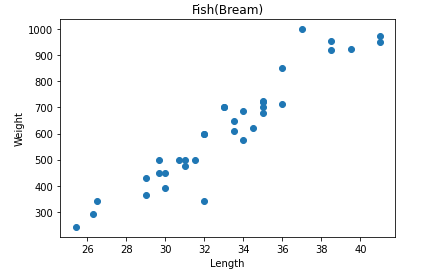

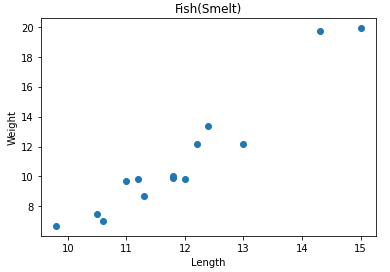

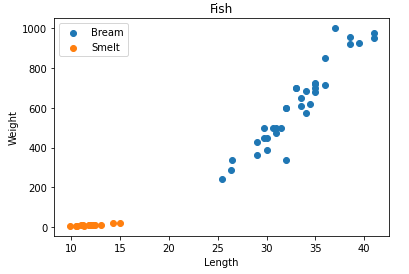


<a id="example-43"></a>

## 43. 공부시간과 성적 산점도·예측 직선

**출처:** 03번 슬라이드 4–5

자료의 여섯 쌍을 그대로 사용합니다. W는 기울기, b는 절편입니다. 첫 그림은 여러 후보 직선을 비교하고, 최소제곱해로 성적을 예측합니다.

> **보완:** 원본 그래프의 후보 직선은 계수값이 제시되지 않아 후보 계수는 비교용으로 추가했습니다. 최소제곱해 역시 개념을 확인하기 위한 보충 구현입니다.

### 예제 코드


   공부시간  시험성적
0   9.0  74.0
1  14.0  81.0
2  21.0  86.0
3  27.0  90.0
4  32.0  88.0
5  37.0  92.0
W, b: 0.5802325581395348 71.62790697674417 24시간 성적 예측: 85.553488372093


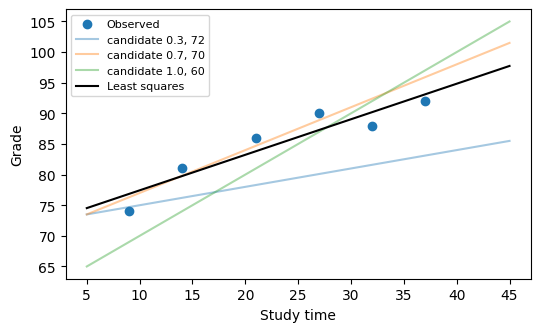

In [ ]:
x = np.array([9,14,21,27,32,37], dtype=float)
t = np.array([74,81,86,90,88,92], dtype=float)

design = np.column_stack([x,np.ones_like(x)])
W, b = np.linalg.lstsq(design,t,rcond=None)[0]
prediction = W*24 + b
print(pd.DataFrame({'공부시간':x,'시험성적':t}))
print('W, b:', W, b, '24시간 성적 예측:', prediction)
grid = np.linspace(5,45,100)
plt.figure()
plt.scatter(x,t,label='Observed')
for w0,b0 in [(0.3,72),(0.7,70),(1.0,60)]:
    plt.plot(grid,w0*grid+b0,alpha=0.4,label=f'candidate {w0}, {b0}')
plt.plot(grid,W*grid+b,'k',label='Least squares')
plt.xlabel('Study time')
plt.ylabel('Grade')
plt.legend(fontsize=8)
plt.show()


### 빈칸 문제 43

**문제 상황과 목표**

공부시간과 성적 데이터에 가장 잘 맞는 직선을 구하고, 그 직선으로 24시간 공부한 학생의 성적을 예상하세요.

**주어진 데이터와 변수**

`x=[9,14,21,27,32,37]`, `t=[74,81,86,90,88,92]`입니다. 직선은 y=Wx+b이고, 최소제곱 계산 코드는 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 첫 열은 공부시간 x, 두 번째 열은 모두 1인 (6,2) 설계 행렬 design을 만드세요. 절편 b도 계수로 함께 구하려면 1인 열이 필요합니다.
2. `____2____`: 구한 W와 b에 공부시간 24를 대입해 prediction을 계산하세요.

**기대 결과와 확인 기준**

design의 각 행은 `[공부시간,1]`입니다. W는 약 0.5802, b는 약 71.6279이며, prediction은 약 85.5535입니다. 소수점 끝자리는 반올림에 따라 달라집니다.

**풀이 힌트**

column_stack은 여러 1차원 배열을 열로 나란히 붙입니다. 예측에서는 24를 넣어 y=Wx+b를 계산하며, 그래프를 보고 성적을 하드코딩하지 마세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_43()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


   공부시간  시험성적
0   9.0  74.0
1  14.0  81.0
2  21.0  86.0
3  27.0  90.0
4  32.0  88.0
5  37.0  92.0
W, b: 0.5802325581395348 71.62790697674417 24시간 성적 예측: 85.553488372093


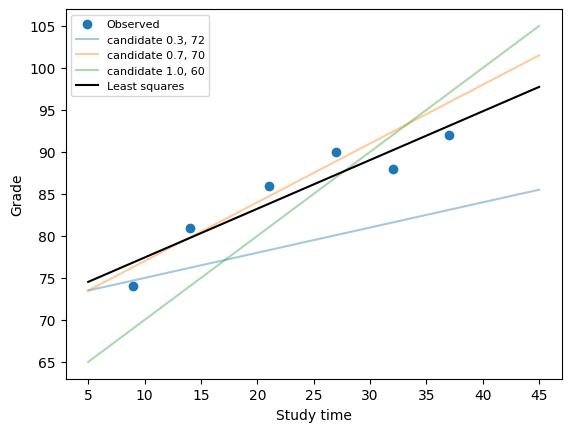

✅ 문제 43 통과


In [ ]:
import matplotlib.pyplot as plt
def practice_43():
    x = np.array([9,14,21,27,32,37], dtype=float)
    t = np.array([74,81,86,90,88,92], dtype=float)

    ones = np.ones((6,1))
    design = np.column_stack((x, ones))
    W, b = np.linalg.lstsq(design,t,rcond=None)[0]
    prediction = W*24+b
    print(pd.DataFrame({'공부시간':x,'시험성적':t}))
    print('W, b:', W, b, '24시간 성적 예측:', prediction)
    grid = np.linspace(5,45,100)
    plt.figure()
    plt.scatter(x,t,label='Observed')
    for w0,b0 in [(0.3,72),(0.7,70),(1.0,60)]:
        plt.plot(grid,w0*grid+b0,alpha=0.4,label=f'candidate {w0}, {b0}')
    plt.plot(grid,W*grid+b,'k',label='Least squares')
    plt.xlabel('Study time')
    plt.ylabel('Grade')
    plt.legend(fontsize=8)
    plt.show()
    assert design.shape == (6,2)
    assert 0.4 < W < 0.7
    assert 84 < prediction < 87
    print("✅ 문제 43 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_43()


<details>
<summary>문제 43 정답과 확인 코드 보기</summary>

- `____1____` → `np.column_stack([x,np.ones_like(x)])`
- `____2____` → `W*24 + b`

```python
def practice_43():
    x = np.array([9,14,21,27,32,37], dtype=float)
    t = np.array([74,81,86,90,88,92], dtype=float)

    design = np.column_stack([x,np.ones_like(x)])
    W, b = np.linalg.lstsq(design,t,rcond=None)[0]
    prediction = W*24 + b
    print(pd.DataFrame({'공부시간':x,'시험성적':t}))
    print('W, b:', W, b, '24시간 성적 예측:', prediction)
    grid = np.linspace(5,45,100)
    plt.figure()
    plt.scatter(x,t,label='Observed')
    for w0,b0 in [(0.3,72),(0.7,70),(1.0,60)]:
        plt.plot(grid,w0*grid+b0,alpha=0.4,label=f'candidate {w0}, {b0}')
    plt.plot(grid,W*grid+b,'k',label='Least squares')
    plt.xlabel('Study time')
    plt.ylabel('Grade')
    plt.legend(fontsize=8)
    plt.show()
    assert design.shape == (6,2)
    assert 0.4 < W < 0.7
    assert 84 < prediction < 87
    print("✅ 문제 43 통과")

practice_43()
```

</details>


<a id="example-44"></a>

## 44. 오차·절댓값 오차·MSE

**출처:** 03번 슬라이드 6–7

부호 있는 오차는 서로 상쇄될 수 있습니다. 절댓값과 제곱으로 오차 크기를 계산합니다. 강의는 제곱 오차의 평균을 선형회귀 손실로 사용합니다.

### 예제 코드


In [ ]:
x = np.array([9,14,21,27,32,37], dtype=float)
t = np.array([74,81,86,90,88,92], dtype=float)

W, b = 0.5, 73.0
y = W*x+b
error = t-y
absolute_sum = np.abs(error).sum()
loss = np.mean(error**2)
print(pd.DataFrame({'x':x,'t':t,'y':y,'오차':error}))
print('절댓값 오차 합:', absolute_sum, 'MSE:', loss)


      x     t     y   오차
0   9.0  74.0  77.5 -3.5
1  14.0  81.0  80.0  1.0
2  21.0  86.0  83.5  2.5
3  27.0  90.0  86.5  3.5
4  32.0  88.0  89.0 -1.0
5  37.0  92.0  91.5  0.5
절댓값 오차 합: 12.0 MSE: 5.5


### 빈칸 문제 44

**문제 상황과 목표**

정해진 직선의 예측값과 실제 성적이 얼마나 다른지 계산하고, 오차 제곱 평균을 손실로 구하세요.

**주어진 데이터와 변수**

공부시간은 `[9,14,21,27,32,37]`, 성적 t는 `[74,81,86,90,88,92]`, 직선의 W=0.5·b=73.0입니다. 이 문제에서는 W와 b를 학습하지 않습니다.

**빈칸별 요구사항**

1. `____1____`: x의 각 공부시간을 직선에 넣어 예측 배열 y를 만드세요.
2. `____2____`: 실제값에서 예측값을 뺀 부호 있는 오차 error를 만드세요.
3. `____3____`: error의 각 원소를 제곱한 뒤 전체 평균을 구해 loss를 계산하세요.

**기대 결과와 확인 기준**

`y=[77.5,80,83.5,86.5,89,91.5]`, `error=[-3.5,1,2.5,3.5,-1,0.5]`. 절댓값 오차 합은 12, MSE는 5.5입니다.

**풀이 힌트**

부호 있는 오차를 그대로 더하면 양수·음수가 상쇄될 수 있습니다. 제곱 오차의 합과 평균도 구분하세요. 이 문제는 평균입니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_44()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_44():
    x = np.array([9,14,21,27,32,37], dtype=float)
    t = np.array([74,81,86,90,88,92], dtype=float)

    W, b = 0.5, 73.0
    y = W * x + b
    error = t-y
    absolute_sum = np.abs(error).sum()
    loss = np.sum(error**2)/len(x)
    print(pd.DataFrame({'x':x,'t':t,'y':y,'오차':error}))
    print('절댓값 오차 합:', absolute_sum, 'MSE:', loss)
    assert np.allclose(y,[77.5,80,83.5,86.5,89,91.5])
    assert np.isclose(loss,5.5)
    assert absolute_sum == 12
    print("✅ 문제 44 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_44()


      x     t     y   오차
0   9.0  74.0  77.5 -3.5
1  14.0  81.0  80.0  1.0
2  21.0  86.0  83.5  2.5
3  27.0  90.0  86.5  3.5
4  32.0  88.0  89.0 -1.0
5  37.0  92.0  91.5  0.5
절댓값 오차 합: 12.0 MSE: 5.5
✅ 문제 44 통과


<details>
<summary>문제 44 정답과 확인 코드 보기</summary>

- `____1____` → `W*x+b`
- `____2____` → `t-y`
- `____3____` → `np.mean(error**2)`

```python
def practice_44():
    x = np.array([9,14,21,27,32,37], dtype=float)
    t = np.array([74,81,86,90,88,92], dtype=float)

    W, b = 0.5, 73.0
    y = W*x+b
    error = t-y
    absolute_sum = np.abs(error).sum()
    loss = np.mean(error**2)
    print(pd.DataFrame({'x':x,'t':t,'y':y,'오차':error}))
    print('절댓값 오차 합:', absolute_sum, 'MSE:', loss)
    assert np.allclose(y,[77.5,80,83.5,86.5,89,91.5])
    assert np.isclose(loss,5.5)
    assert absolute_sum == 12
    print("✅ 문제 44 통과")

practice_44()
```

</details>


<a id="example-45"></a>

## 45. b=0인 손실 함수 표와 그래프

**출처:** 03번 슬라이드 8–9

x=t=[1,2,3]이면 W=1에서 손실이 0입니다. W가 1에서 멀어질수록 제곱 오차가 커집니다.

### 예제 코드


   W       E(W)
0 -1  18.666667
1  0   4.666667
2  1   0.000000
3  2   4.666667
4  3  18.666667


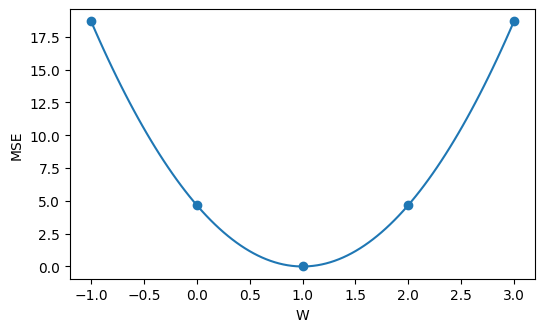

In [ ]:
x = np.array([1,2,3],dtype=float)
t = np.array([1,2,3],dtype=float)
def loss_at(W):
    return np.mean((t-W*x)**2)
weights = np.array([-1,0,1,2,3])
losses = np.array([loss_at(W) for W in weights])
print(pd.DataFrame({'W':weights,'E(W)':losses}))
curve = np.linspace(-1,3,100)
plt.figure()
plt.plot(curve,[loss_at(w) for w in curve])
plt.scatter(weights,losses)
plt.xlabel('W')
plt.ylabel('MSE')
plt.show()


### 빈칸 문제 45

**문제 상황과 목표**

절편 b가 0인 직선에서 가중치 W를 바꾸었을 때 손실이 어떻게 달라지는지 표와 그래프로 확인하세요.

**주어진 데이터와 변수**

`x=t=[1,2,3]`, 후보 `weights=[-1,0,1,2,3]`입니다. loss_at(W)는 W 하나에 대한 MSE를 반환해야 합니다.

**빈칸별 요구사항**

1. `____1____`: 예측을 W×x로 두고 t와의 차이를 제곱한 평균을 반환하세요.
2. `____2____`: 각 후보 W를 loss_at에 넣은 결과를 후보 순서대로 모아 NumPy 배열 losses를 만드세요.

**기대 결과와 확인 기준**

후보 순서대로 손실은 약 `[18.6667,4.6667,0,4.6667,18.6667]`입니다. 손실이 가장 작은 W는 1입니다.

**풀이 힌트**

첫 빈칸은 하나의 실수 손실을 계산하고 두 번째 빈칸은 그 함수를 여러 W에 반복 적용합니다. W=1일 때 예측과 정답이 완전히 일치하는지 먼저 점검하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_45()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


   W       E(W)
0 -1  18.666667
1  0   4.666667
2  1   0.000000
3  2   4.666667
4  3  18.666667


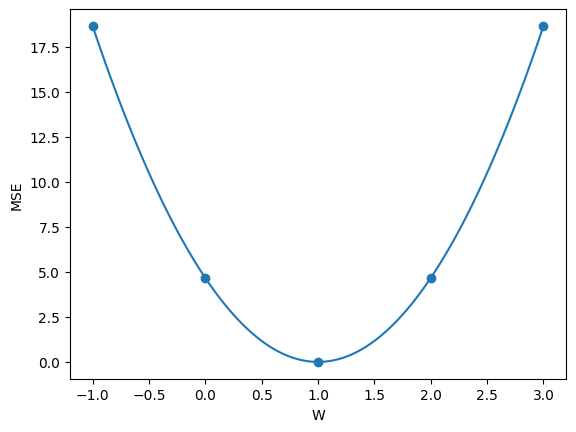

✅ 문제 45 통과


In [ ]:
def practice_45():
    x = np.array([1,2,3],dtype=float)
    t = np.array([1,2,3],dtype=float)
    def loss_at(W):
        return np.sum((W*x - t)**2) / len(x)
    weights = np.array([-1,0,1,2,3])
    losses = np.array([loss_at(W) for W in weights])
    print(pd.DataFrame({'W':weights,'E(W)':losses}))
    curve = np.linspace(-1,3,100)
    plt.figure()
    plt.plot(curve,[loss_at(w) for w in curve])
    plt.scatter(weights,losses)
    plt.xlabel('W')
    plt.ylabel('MSE')
    plt.show()
    assert np.allclose(losses,[56/3,14/3,0,14/3,56/3])
    assert weights[np.argmin(losses)] == 1
    print("✅ 문제 45 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_45()


<details>
<summary>문제 45 정답과 확인 코드 보기</summary>

- `____1____` → `np.mean((t-W*x)**2)`
- `____2____` → `np.array([loss_at(W) for W in weights])`

```python
def practice_45():
    x = np.array([1,2,3],dtype=float)
    t = np.array([1,2,3],dtype=float)
    def loss_at(W):
        return np.mean((t-W*x)**2)
    weights = np.array([-1,0,1,2,3])
    losses = np.array([loss_at(W) for W in weights])
    print(pd.DataFrame({'W':weights,'E(W)':losses}))
    curve = np.linspace(-1,3,100)
    plt.figure()
    plt.plot(curve,[loss_at(w) for w in curve])
    plt.scatter(weights,losses)
    plt.xlabel('W')
    plt.ylabel('MSE')
    plt.show()
    assert np.allclose(losses,[56/3,14/3,0,14/3,56/3])
    assert weights[np.argmin(losses)] == 1
    print("✅ 문제 45 통과")

practice_45()
```

</details>


<a id="example-46"></a>

## 46. 경사하강 한 변수: W=2.8에서 이동

**출처:** 03번 슬라이드 10–11

$W\leftarrow W-\alpha\,\partial E/\partial W$로 업데이트합니다. 양의 기울기면 W를 줄이고 음의 기울기면 늘립니다.

### 예제 코드


In [ ]:
x = np.array([1,2,3],dtype=float)
t = x.copy()
W = 2.8
rate = 0.03
trace = [W]
for step in range(30):
    grad = 2*np.mean(x*(W*x-t))
    W = W-rate*grad
    trace.append(W)
print('첫 다섯 W:', np.round(trace[:5],4))
print('최종 W:', W)


첫 다섯 W: [2.8    2.296  1.9331 1.6718 1.4837]
최종 W: 1.000094459881853


### 빈칸 문제 46

**문제 상황과 목표**

손실이 줄어드는 방향으로 가중치 W를 반복 이동시켜, 정답 t=x인 직선을 찾으세요.

**주어진 데이터와 변수**

`x=t=[1,2,3]`, 초기 W=2.8, 학습률 rate=0.03입니다. 절편은 0이고 30번 반복하며 trace에 W의 경로를 저장합니다.

**빈칸별 요구사항**

1. `____1____`: 현재 W의 MSE 기울기를 계산하세요. MSE를 W로 미분하면 각 데이터에 대해 x×(W×x−t)를 계산한 평균의 두 배입니다.
2. `____2____`: 현재 W에서 학습률×기울기를 빼는 경사하강 업데이트를 작성하세요.

**기대 결과와 확인 기준**

첫 업데이트 W는 2.296, 30번 뒤에는 1에 0.001 이내로 가까워집니다. trace의 W가 목표 1에 점점 가까워져야 합니다.

**풀이 힌트**

기울기가 양수일 때 W를 줄여야 하므로 업데이트의 부호에 주의하세요. grad를 계산할 때 합이 아닌 평균을 사용합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_46()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_46():
    x = np.array([1,2,3],dtype=float)
    t = x.copy()
    W = 2.8
    rate = 0.03
    trace = [W]
    for step in range(30):
        grad = 2*np.mean(x*(W*x-t))
        W = W - rate * grad
        trace.append(W)
    print('첫 다섯 W:', np.round(trace[:5],4))
    print('최종 W:', W)
    assert np.isclose(trace[1],2.296)
    assert abs(W-1) < 0.001
    assert all(abs(w-1) <= abs(prev-1) for prev,w in zip(trace,trace[1:]))
    print("✅ 문제 46 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_46()


첫 다섯 W: [2.8    2.296  1.9331 1.6718 1.4837]
최종 W: 1.000094459881853
✅ 문제 46 통과


<details>
<summary>문제 46 정답과 확인 코드 보기</summary>

- `____1____` → `2*np.mean(x*(W*x-t))`
- `____2____` → `W-rate*grad`

```python
def practice_46():
    x = np.array([1,2,3],dtype=float)
    t = x.copy()
    W = 2.8
    rate = 0.03
    trace = [W]
    for step in range(30):
        grad = 2*np.mean(x*(W*x-t))
        W = W-rate*grad
        trace.append(W)
    print('첫 다섯 W:', np.round(trace[:5],4))
    print('최종 W:', W)
    assert np.isclose(trace[1],2.296)
    assert abs(W-1) < 0.001
    assert all(abs(w-1) <= abs(prev-1) for prev,w in zip(trace,trace[1:]))
    print("✅ 문제 46 통과")

practice_46()
```

</details>


<a id="example-47"></a>

## 47. W와 b의 경사하강 경로

**출처:** 03번 슬라이드 12

W와 b가 함께 손실을 줄이는 경로를 확인합니다. 같은 시점의 두 기울기로 두 파라미터를 업데이트합니다.

> **보완:** 개념 예제의 실습화: 원본 경로 그림의 시작·목표점에 맞춰 x=[1,…,5], t=x+1로 경로를 구현했습니다.

### 예제 코드


처음: (-2.0, 3.0, 67.0) 마지막: (np.float64(0.999999998486531), np.float64(1.0000000054641034), 5.434392223298843e-18)


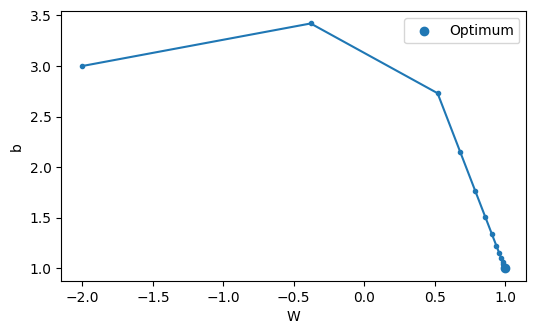

In [ ]:
x = np.arange(1,6,dtype=float)
t = x+1
W,b = -2.0,3.0
path = [(W,b,mse(t,W*x+b))]
for step in range(2000):
    error = W*x+b-t
    grad_W = 2*np.mean(x*error)
    grad_b = 2*np.mean(error)
    W,b = W-0.03*grad_W,b-0.03*grad_b
    if step % 40 == 0:
        path.append((W,b,mse(t,W*x+b)))
print('처음:', path[0], '마지막:', path[-1])
path_array = np.array(path)
plt.figure()
plt.plot(path_array[:,0],path_array[:,1],'.-')
plt.scatter([1],[1],label='Optimum')
plt.xlabel('W')
plt.ylabel('b')
plt.legend()
plt.show()


### 빈칸 문제 47

**문제 상황과 목표**

가중치 W뿐 아니라 절편 b도 함께 학습하여 t=x+1 관계를 찾으세요.

**주어진 데이터와 변수**

`x=[1,2,3,4,5]`, `t=[2,3,4,5,6]`, 초기 `(W,b)=(-2,3)`입니다. error는 예측−정답이며 학습률은 0.03, 반복은 2,000번입니다.

**빈칸별 요구사항**

1. `____1____`: MSE의 W 기울기를 구하세요. 각 x와 error를 곱한 평균의 두 배입니다.
2. `____2____`: MSE의 b 기울기를 구하세요. error 평균의 두 배입니다.
3. `____3____`: W와 b 각각에서 0.03×해당 기울기를 빼고, 두 새 값을 쉼표로 묶어 반환할 식을 작성하세요.

**기대 결과와 확인 기준**

W는 약 1, b도 약 1이 되고 최종 손실은 시작보다 작아야 합니다. 그래프에는 (-2,3)에서 (1,1) 쪽으로 이동하는 경로가 나타납니다.

**풀이 힌트**

이 코드의 error는 t−예측이 아니라 예측−t입니다. 두 기울기를 같은 시점의 W,b에서 계산한 뒤 두 파라미터를 업데이트하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_47()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


처음: (-2.0, 3.0, 67.0) 마지막: (np.float64(0.999999998486531), np.float64(1.0000000054641034), 5.434392223298843e-18)


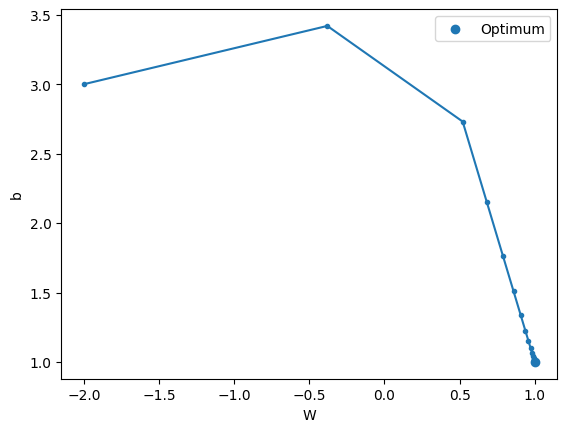

✅ 문제 47 통과


In [ ]:
def practice_47():
    x = np.arange(1,6,dtype=float)
    t = x+1
    W,b = -2.0,3.0
    path = [(W,b,mse(t,W*x+b))]
    for step in range(2000):
        error = W*x+b-t
        grad_W = 2 * np.mean(x * error)
        grad_b = 2 * np.mean(error)
        W,b = W - 0.03 * grad_W, b - 0.03 * grad_b
        if step % 40 == 0:
            path.append((W,b,mse(t,W*x+b)))
    print('처음:', path[0], '마지막:', path[-1])
    path_array = np.array(path)
    plt.figure()
    plt.plot(path_array[:,0],path_array[:,1],'.-')
    plt.scatter([1],[1],label='Optimum')
    plt.xlabel('W')
    plt.ylabel('b')
    plt.legend()
    plt.show()
    assert np.allclose([W,b],[1,1],atol=1e-6)
    assert path[-1][2] < path[0][2]
    print("✅ 문제 47 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_47()


<details>
<summary>문제 47 정답과 확인 코드 보기</summary>

- `____1____` → `2*np.mean(x*error)`
- `____2____` → `2*np.mean(error)`
- `____3____` → `W-0.03*grad_W,b-0.03*grad_b`

```python
def practice_47():
    x = np.arange(1,6,dtype=float)
    t = x+1
    W,b = -2.0,3.0
    path = [(W,b,mse(t,W*x+b))]
    for step in range(2000):
        error = W*x+b-t
        grad_W = 2*np.mean(x*error)
        grad_b = 2*np.mean(error)
        W,b = W-0.03*grad_W,b-0.03*grad_b
        if step % 40 == 0:
            path.append((W,b,mse(t,W*x+b)))
    print('처음:', path[0], '마지막:', path[-1])
    path_array = np.array(path)
    plt.figure()
    plt.plot(path_array[:,0],path_array[:,1],'.-')
    plt.scatter([1],[1],label='Optimum')
    plt.xlabel('W')
    plt.ylabel('b')
    plt.legend()
    plt.show()
    assert np.allclose([W,b],[1,1],atol=1e-6)
    assert path[-1][2] < path[0][2]
    print("✅ 문제 47 통과")

practice_47()
```

</details>


<a id="example-48"></a>

## 48. Case1: XW+b의 행렬 계산

**출처:** 03번 슬라이드 13

X는 5×1, W는 1×1, b는 길이 1 배열입니다. 정답 T도 5×1로 맞춰야 오차가 5×5로 잘못 확장되지 않습니다.

### 예제 코드


In [ ]:
X = np.array([1,2,3,4,5],dtype=float).reshape(5,1)
T = np.array([2,3,4,5,6],dtype=float).reshape(5,1)
W = np.array([[0.5]])
b = np.array([0.2])
Y = X @ W+b
loss = np.sum((T-Y)**2)/len(X)
print('shape:', X.shape,W.shape,b.shape,T.shape,Y.shape)
print('예측:',Y.ravel(),'손실:',loss)


shape: (5, 1) (1, 1) (1,) (5, 1) (5, 1)
예측: [0.7 1.2 1.7 2.2 2.7] 손실: 5.789999999999999


### 빈칸 문제 48

**문제 상황과 목표**

샘플 다섯 개의 예측을 행렬 곱 한 번으로 계산하고 정답과 shape을 맞춰 손실을 구하세요.

**주어진 데이터와 변수**

X는 1부터 5까지 담긴 (5,1) 열 벡터, W는 값 0.5인 (1,1) 행렬, b는 값 0.2인 길이 1 배열입니다.

**빈칸별 요구사항**

1. `____1____`: 정답 2,3,4,5,6을 실수 NumPy 배열로 만들고 (5,1) 열 벡터로 바꾸세요.
2. `____2____`: X와 W를 행렬 곱한 뒤 b를 더해 모든 샘플의 예측 Y를 계산하세요.
3. `____3____`: T와 Y의 차이를 원소별로 제곱해 합산하고 샘플 수로 나눠 MSE를 구하세요.

**기대 결과와 확인 기준**

T와 Y의 shape은 둘 다 (5,1), 예측값을 펼치면 `[0.7,1.2,1.7,2.2,2.7]`, 손실은 5.79입니다.

**풀이 힌트**

행렬 곱은 @를 사용합니다. T를 (5,)로 만들면 (5,1)인 Y와 뺄 때 (5,5)로 퍼질 수 있으므로 열 벡터 형태를 꼭 맞추세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_48()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_48():
    X = np.array([1,2,3,4,5],dtype=float).reshape(5,1)
    T = np.array([2, 3, 4, 5, 6]).reshape(5,1)
    W = np.array([[0.5]])
    b = np.array([0.2])
    Y = X@W + b
    loss = np.sum((T - Y)**2) / len(T)
    print('shape:', X.shape,W.shape,b.shape,T.shape,Y.shape)
    print('예측:',Y.ravel(),'손실:',loss)
    assert Y.shape == T.shape == (5,1)
    assert np.allclose(Y.ravel(),[0.7,1.2,1.7,2.2,2.7])
    assert np.isclose(loss,5.79)
    print("✅ 문제 48 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_48()


shape: (5, 1) (1, 1) (1,) (5, 1) (5, 1)
예측: [0.7 1.2 1.7 2.2 2.7] 손실: 5.789999999999999
✅ 문제 48 통과


<details>
<summary>문제 48 정답과 확인 코드 보기</summary>

- `____1____` → `np.array([2,3,4,5,6],dtype=float).reshape(5,1)`
- `____2____` → `X @ W+b`
- `____3____` → `np.sum((T-Y)**2)/len(X)`

```python
def practice_48():
    X = np.array([1,2,3,4,5],dtype=float).reshape(5,1)
    T = np.array([2,3,4,5,6],dtype=float).reshape(5,1)
    W = np.array([[0.5]])
    b = np.array([0.2])
    Y = X @ W+b
    loss = np.sum((T-Y)**2)/len(X)
    print('shape:', X.shape,W.shape,b.shape,T.shape,Y.shape)
    print('예측:',Y.ravel(),'손실:',loss)
    assert Y.shape == T.shape == (5,1)
    assert np.allclose(Y.ravel(),[0.7,1.2,1.7,2.2,2.7])
    assert np.isclose(loss,5.79)
    print("✅ 문제 48 통과")

practice_48()
```

</details>


<a id="example-49"></a>

## 49. 중심 차분 수치미분과 원상 복구

**출처:** 03번 슬라이드 14

$f\prime(w)\approx[f(w+h)-f(w-h)]/(2h)$를 씁니다. 값을 잠시 바꿨다면 기울기 계산 뒤 반드시 복구합니다.

### 예제 코드


In [ ]:
def derivative(fn,param,delta=1e-4):
    grad = np.zeros_like(param,dtype=float)
    for idx in np.ndindex(param.shape):
        original = param[idx]
        param[idx] = original+delta
        plus = fn()
        param[idx] = original-delta
        minus = fn()
        grad[idx] = (plus-minus)/(2*delta)
        param[idx] = original
    return grad

p = np.array([2.0,-3.0])
before = p.copy()
gradient = derivative(lambda:np.sum(p**2),p)
print('기울기:',gradient,'복구 뒤 p:',p)


기울기: [ 4. -6.] 복구 뒤 p: [ 2. -3.]


### 빈칸 문제 49

**문제 상황과 목표**

미분 공식을 직접 쓰지 않고, 파라미터를 아주 조금씩 움직였을 때의 함수값 차이로 기울기를 계산하세요.

**주어진 데이터와 변수**

`p=[2.0,-3.0]`, `fn()`은 p의 각 원소를 제곱한 합을 반환합니다. delta=0.0001이며 param의 각 원소를 차례로 수정합니다. original은 해당 원소의 원래 값입니다.

**빈칸별 요구사항**

1. `____1____`: 현재 원소를 원래 값보다 delta만큼 크게 설정할 값을 작성하세요. 그 직후 함수값이 plus에 저장됩니다.
2. `____2____`: 현재 원소를 원래 값보다 delta만큼 작게 설정할 값을 작성하세요. 그 직후 함수값이 minus에 저장됩니다.
3. `____3____`: 증가시킨 함수값과 감소시킨 함수값의 차이를 두 지점 사이의 거리로 나눠 중심 차분 기울기를 구하세요.
4. `____4____`: **대입문 한 줄 전체**를 작성해 param[idx]를 original로 되돌리세요. 다음 원소를 계산할 때 이전 원소의 값이 바뀐 채 남으면 안 됩니다.

**기대 결과와 확인 기준**

기울기는 약 `[4,-6]`입니다. 계산 뒤 p는 시작과 똑같은 `[2.0,-3.0]`이어야 합니다.

**풀이 힌트**

두 지점은 original+delta와 original−delta이므로 지점 간 거리는 delta가 아니라 2×delta입니다. 마지막 빈칸은 값 하나가 아니라 복구 동작을 수행하는 문장입니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_49()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_49():
    def derivative(fn,param,delta=1e-4):
        grad = np.zeros_like(param,dtype=float)
        for idx in np.ndindex(param.shape):
            original = param[idx]
            param[idx] = original + delta
            plus = fn()
            param[idx] = original - delta
            minus = fn()
            grad[idx] = (plus - minus) / (2 * delta)
            param[idx] = original
        return grad
    p = np.array([2.0,-3.0])
    before = p.copy()
    gradient = derivative(lambda:np.sum(p**2),p)
    print(gradient,p)
    assert np.allclose(gradient,[4,-6])
    assert np.array_equal(p,before)
    print("✅ 문제 49 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_49()


[ 4. -6.] [ 2. -3.]
✅ 문제 49 통과


<details>
<summary>문제 49 정답과 확인 코드 보기</summary>

- `____1____` → `original+delta`
- `____2____` → `original-delta`
- `____3____` → `(plus-minus)/(2*delta)`
- `____4____` → `param[idx] = original`

```python
def practice_49():
    def derivative(fn,param,delta=1e-4):
        grad = np.zeros_like(param,dtype=float)
        for idx in np.ndindex(param.shape):
            original = param[idx]
            param[idx] = original+delta
            plus = fn()
            param[idx] = original-delta
            minus = fn()
            grad[idx] = (plus-minus)/(2*delta)
            param[idx] = original
        return grad
    p = np.array([2.0,-3.0])
    before = p.copy()
    gradient = derivative(lambda:np.sum(p**2),p)
    print(gradient,p)
    assert np.allclose(gradient,[4,-6])
    assert np.array_equal(p,before)
    print("✅ 문제 49 통과")

practice_49()
```

</details>


<a id="example-50"></a>

## 50. Case1 전체 학습과 7 입력 예측

**출처:** 03번 슬라이드 13–14

수치미분으로 W와 b를 학습합니다. 학습 데이터 t=x+1이므로 최적 W=1, b=1, x=7의 예측은 약 8입니다.

> **보완:** 슬라이드에는 전체 Python 구현이 없어 같은 폴더의 P02 실습 흐름을 참고해 입출력이 명확한 함수로 정리했습니다.

### 예제 코드


In [ ]:
X = np.arange(1,6,dtype=float).reshape(-1,1)
T = X+1
model = fit_linear(X,T,lr=1e-3,steps=8000,method='numeric')
prediction = predict_linear([[7]],model)
print('초기/최종 손실:',model['initial_loss'],model['loss'])
print('W, b:',model['W'].ravel(),model['b'])
print('x=7 예측:',prediction)


초기/최종 손실: 1.7878625753971051 1.0488231553876574e-09
W, b: [1.00002103] [0.99992409]
x=7 예측: [[8.00007127]]


### 빈칸 문제 50

**문제 상황과 목표**

선형회귀 공통 함수를 사용해 t=x+1 관계를 실제로 학습하고 학습에 없던 x=7을 예측하세요.

**주어진 데이터와 변수**

X는 1–5의 (5,1) 배열, T는 각 X에 1을 더한 정답입니다. fit_linear는 X·T·lr·steps·method를 받고, predict_linear는 2차원 입력과 학습 모델을 받습니다.

**빈칸별 요구사항**

1. `____1____`: 학습률 0.001, 반복 8,000회, 방법 numeric으로 fit_linear를 호출해 model을 만드세요.
2. `____2____`: 입력 7을 샘플 1개·특성 1개의 2차원 배열 형태로 전달해 예측하세요.

**기대 결과와 확인 기준**

최종 손실이 초기보다 줄고 W≈1, b≈1이 됩니다. prediction의 shape은 (1,1), 값은 약 8이어야 합니다.

**풀이 힌트**

기계학습 공통 함수 셀을 먼저 실행하세요. 숫자 7 하나나 [7] 대신, 한 행 안에 특성 하나가 들어 있는 형태로 입력을 전달합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_50()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_50():
    X = np.arange(1,6,dtype=float).reshape(-1,1)
    T = X+1
    model = fit_linear(X, T, lr = 0.001, steps = 8000, method = 'numeric')
    prediction = predict_linear([[7]], model)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W, b:',model['W'].ravel(),model['b'])
    print('x=7 예측:',prediction)
    assert model["loss"] < model["initial_loss"]
    assert np.allclose(model["W"],[[1]],atol=0.03)
    assert np.allclose(prediction,[[8]],atol=0.1)
    print("✅ 문제 50 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_50()


초기/최종 손실: 1.7878625753971051 1.0488231553876574e-09
W, b: [1.00002103] [0.99992409]
x=7 예측: [[8.00007127]]
✅ 문제 50 통과


<details>
<summary>문제 50 정답과 확인 코드 보기</summary>

- `____1____` → `fit_linear(X,T,lr=1e-3,steps=8000,method='numeric')`
- `____2____` → `predict_linear([[7]],model)`

```python
def practice_50():
    X = np.arange(1,6,dtype=float).reshape(-1,1)
    T = X+1
    model = fit_linear(X,T,lr=1e-3,steps=8000,method='numeric')
    prediction = predict_linear([[7]],model)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W, b:',model['W'].ravel(),model['b'])
    print('x=7 예측:',prediction)
    assert model["loss"] < model["initial_loss"]
    assert np.allclose(model["W"],[[1]],atol=0.03)
    assert np.allclose(prediction,[[8]],atol=0.1)
    print("✅ 문제 50 통과")

practice_50()
```

</details>


<a id="example-51"></a>

## 51. 국·영·수 다변수 선형회귀

**출처:** 03번 슬라이드 15

25명의 입력 3개로 모의고사 점수 1개를 예측합니다. X=(25,3), T=(25,1), W=(3,1), 출력=(25,1)입니다. 학습한 가중치는 각 과목에 곱해지는 계수입니다.

> **보완:** 25행은 슬라이드와 P03 실습 자료의 동일 데이터를 사용합니다. 슬라이드의 lr=0.0005는 원본 스케일에서 발산할 수 있어 실습 자료의 1e-5로 보완했습니다. 자료 보고값 W=[0.356,0.53,1.126], b=0.098, 손실 약 6.1은 실행과 별개입니다.

### 예제 코드


In [76]:
raw = np.array([
    [73, 80, 75, 152],
    [93, 88, 93, 185],
    [89, 91, 90, 180],
    [96, 98, 100, 196],
    [73, 66, 70, 142],
    [53, 46, 55, 101],
    [69, 74, 77, 149],
    [47, 56, 60, 115],
    [87, 79, 90, 175],
    [79, 70, 88, 164],
    [69, 70, 73, 141],
    [70, 65, 74, 141],
    [93, 95, 91, 184],
    [79, 80, 73, 152],
    [70, 73, 78, 148],
    [93, 89, 96, 192],
    [78, 75, 68, 147],
    [81, 90, 93, 183],
    [88, 92, 86, 177],
    [78, 83, 77, 159],
    [82, 86, 90, 177],
    [86, 82, 89, 175],
    [78, 83, 85, 175],
    [76, 83, 71, 149],
    [96, 93, 95, 192],
],dtype=float)

X = raw[:,:-1]
T = raw[:,[-1]]
model = fit_linear(X,T,lr=1e-5,steps=15000,method='numeric')
test = np.array([[85,90,92],[92,90,85]])
prediction = predict_linear(test,model)
print('X/T shape:',X.shape,T.shape)
print('초기/최종 손실:',model['initial_loss'],model['loss'])
print('W/b:',model['W'].ravel(),model['b'])
print('실행 예측:',prediction.ravel())
print('슬라이드 보고 예측: [181.7, 176.3] (초기화·학습 조건이 다르면 차이 발생)')


X/T shape: (25, 3) (25, 1)
초기/최종 손실: 510.2228852121851 6.13511209514653
W/b: [0.3597 0.5283 1.1231] [0.2015]
실행 예측: [181.6431 176.2996]
슬라이드 보고 예측: [181.7, 176.3] (초기화·학습 조건이 다르면 차이 발생)


### 빈칸 문제 51

**문제 상황과 목표**

국어·영어·수학 점수 세 개를 입력으로 받아 모의고사 점수 하나를 예측하는 다변수 선형회귀를 완성하세요.

**주어진 데이터와 변수**

raw는 학생 25명 × 4열 배열입니다. 열은 국어·영어·수학·모의고사 순서입니다. test는 점수가 `[85,90,92]`, `[92,90,85]`인 두 학생입니다.

**빈칸별 요구사항**

1. `____1____`: 모든 학생의 앞 세 과목 열만 선택해 입력 X를 만드세요. 마지막 모의고사 열은 입력에서 제외합니다.
2. `____2____`: 모든 학생의 마지막 열만 선택해 정답 T를 만드세요. (25,)가 아닌 (25,1)이 되도록 열 차원을 유지하세요.
3. `____3____`: fit_linear를 X,T·학습률 0.00001·반복 15,000회·numeric 방식으로 호출하세요.
4. `____4____`: 학습한 model로 test의 두 학생을 한 번에 예측하세요.

**기대 결과와 확인 기준**

X=(25,3), T=(25,1), W=(3,1), prediction=(2,1)입니다. 손실은 7 미만이며 예측은 대략 170–190점대 범위입니다. 슬라이드 보고 예측 [181.7,176.3]과 소수점까지 일치시킬 필요는 없습니다.

**풀이 힌트**

열 하나를 정수로 선택하면 차원이 줄어들 수 있습니다. 마지막 열의 위치를 목록으로 감싸 선택하면 열 벡터를 유지할 수 있습니다. 원본 점수 스케일에서 학습률을 크게 하면 발산하므로 지정값을 쓰세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_51()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [82]:
import numpy as np
def practice_51():
    raw = np.array([
        [73, 80, 75, 152],
        [93, 88, 93, 185],
        [89, 91, 90, 180],
        [96, 98, 100, 196],
        [73, 66, 70, 142],
        [53, 46, 55, 101],
        [69, 74, 77, 149],
        [47, 56, 60, 115],
        [87, 79, 90, 175],
        [79, 70, 88, 164],
        [69, 70, 73, 141],
        [70, 65, 74, 141],
        [93, 95, 91, 184],
        [79, 80, 73, 152],
        [70, 73, 78, 148],
        [93, 89, 96, 192],
        [78, 75, 68, 147],
        [81, 90, 93, 183],
        [88, 92, 86, 177],
        [78, 83, 77, 159],
        [82, 86, 90, 177],
        [86, 82, 89, 175],
        [78, 83, 85, 175],
        [76, 83, 71, 149],
        [96, 93, 95, 192],
    ],dtype=float)

    X = raw[:, :-1]
    T = raw[:, [-1]]
    model = fit_linear(X, T, lr = 0.00001, steps = 15000, method = 'numeric')
    test = np.array([[85,90,92],[92,90,85]])
    prediction = predict_linear(test, model)
    print('X/T shape:',X.shape,T.shape)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print('실행 예측:',prediction.ravel())
    print('슬라이드 보고 예측: [181.7, 176.3] (초기화·학습 조건이 다르면 차이 발생)')
    assert X.shape == (25,3) and T.shape == (25,1)
    assert model["W"].shape == (3,1)
    assert np.isfinite(model["loss"]) and model["loss"] < 7
    assert prediction.shape == (2,1) and np.all((prediction > 160)&(prediction < 195))
    print("✅ 문제 51 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
practice_51()


X/T shape: (25, 3) (25, 1)
초기/최종 손실: 510.2228852121851 6.13511209514653
W/b: [0.3597 0.5283 1.1231] [0.2015]
실행 예측: [181.6431 176.2996]
슬라이드 보고 예측: [181.7, 176.3] (초기화·학습 조건이 다르면 차이 발생)
✅ 문제 51 통과


<details>
<summary>문제 51 정답과 확인 코드 보기</summary>

- `____1____` → `raw[:,:-1]`
- `____2____` → `raw[:,[-1]]`
- `____3____` → `fit_linear(X,T,lr=1e-5,steps=15000,method='numeric')`
- `____4____` → `predict_linear(test,model)`

```python
def practice_51():
    raw = np.array([
        [73, 80, 75, 152],
        [93, 88, 93, 185],
        [89, 91, 90, 180],
        [96, 98, 100, 196],
        [73, 66, 70, 142],
        [53, 46, 55, 101],
        [69, 74, 77, 149],
        [47, 56, 60, 115],
        [87, 79, 90, 175],
        [79, 70, 88, 164],
        [69, 70, 73, 141],
        [70, 65, 74, 141],
        [93, 95, 91, 184],
        [79, 80, 73, 152],
        [70, 73, 78, 148],
        [93, 89, 96, 192],
        [78, 75, 68, 147],
        [81, 90, 93, 183],
        [88, 92, 86, 177],
        [78, 83, 77, 159],
        [82, 86, 90, 177],
        [86, 82, 89, 175],
        [78, 83, 85, 175],
        [76, 83, 71, 149],
        [96, 93, 95, 192],
    ],dtype=float)

    X = raw[:,:-1]
    T = raw[:,[-1]]
    model = fit_linear(X,T,lr=1e-5,steps=15000,method='numeric')
    test = np.array([[85,90,92],[92,90,85]])
    prediction = predict_linear(test,model)
    print('X/T shape:',X.shape,T.shape)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print('실행 예측:',prediction.ravel())
    print('슬라이드 보고 예측: [181.7, 176.3] (초기화·학습 조건이 다르면 차이 발생)')
    assert X.shape == (25,3) and T.shape == (25,1)
    assert model["W"].shape == (3,1)
    assert np.isfinite(model["loss"]) and model["loss"] < 7
    assert prediction.shape == (2,1) and np.all((prediction > 160)&(prediction < 195))
    print("✅ 문제 51 통과")

practice_51()
```

</details>


<a id="example-52"></a>

## 52. Pass/Fail 데이터로 로지스틱 회귀 맛보기

**출처:** 03번 슬라이드 16–17

공부시간 9·14·21은 Fail(0), 27·32·37은 Pass(1)입니다. 출력은 Pass 확률이며 0.5 이상을 Pass로 정합니다.

> **보완:** 개념 예제의 실습화입니다. 24시간은 경계 근처여서 학습 조건에 따라 분류가 달라질 수 있습니다.

### 예제 코드


In [ ]:
X = np.array([9,14,21,27,32,37],dtype=float).reshape(-1,1)
T = np.array([0,0,0,1,1,1]).reshape(-1,1)
model = fit_logistic(X,T,lr=0.001,steps=20000)
test = np.array([[24],[26],[40]])
probabilities = predict_probability(test,model)
classes = predict_class(test,model)
print(pd.DataFrame({'공부시간':test.ravel(),'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))


   공부시간   Pass 확률  분류
0    24  0.584941   1
1    26  0.712072   1
2    40  0.992171   1


### 빈칸 문제 52

**문제 상황과 목표**

공부시간을 입력받아 합격할 확률과 최종 합격·불합격 판정을 각각 구하세요. 성적 숫자를 예측하는 회귀 문제와 출력의 의미가 다릅니다.

**주어진 데이터와 변수**

공부시간 X는 9·14·21·27·32·37입니다. 앞의 세 학생은 Fail, 뒤의 세 학생은 Pass입니다. 시험 입력 test는 24·26·40시간이며 학습 호출은 이미 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: Fail을 0, Pass를 1로 바꿔 X 순서에 맞는 정답을 만들고 (6,1) 열 벡터로 바꾸세요.
2. `____2____`: test와 model을 확률 예측 함수에 전달해 Pass 확률을 구하세요.
3. `____3____`: 같은 test와 model을 분류 함수에 전달해 0 또는 1의 판정을 구하세요.

**기대 결과와 확인 기준**

T는 `[0,0,0,1,1,1]` 열 벡터입니다. 확률과 분류 모두 (3,1)이며 확률은 0–1입니다. 분류는 확률 0.5 이상일 때 1이고, 40시간은 Pass여야 합니다. 24시간은 경계 근처이므로 결과를 고정하지 않습니다.

**풀이 힌트**

predict_probability는 실수 확률, predict_class는 정수 클래스를 반환합니다. 입력 test에 대한 답은 학습한 model에서 구하고 직접 지정하지 마세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_52()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_52():
    X = np.array([9,14,21,27,32,37],dtype=float).reshape(-1,1)
    T = ____1____
    model = fit_logistic(X,T,lr=0.001,steps=20000)
    test = np.array([[24],[26],[40]])
    probabilities = ____2____
    classes = ____3____
    print(pd.DataFrame({'공부시간':test.ravel(),'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))
    assert T.shape == (6,1)
    assert probabilities.shape == (3,1)
    assert np.all((probabilities >= 0)&(probabilities <= 1))
    assert np.array_equal(classes,(probabilities >= 0.5).astype(int))
    assert classes[-1,0] == 1
    print("✅ 문제 52 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_52()


<details>
<summary>문제 52 정답과 확인 코드 보기</summary>

- `____1____` → `np.array([0,0,0,1,1,1]).reshape(-1,1)`
- `____2____` → `predict_probability(test,model)`
- `____3____` → `predict_class(test,model)`

```python
def practice_52():
    X = np.array([9,14,21,27,32,37],dtype=float).reshape(-1,1)
    T = np.array([0,0,0,1,1,1]).reshape(-1,1)
    model = fit_logistic(X,T,lr=0.001,steps=20000)
    test = np.array([[24],[26],[40]])
    probabilities = predict_probability(test,model)
    classes = predict_class(test,model)
    print(pd.DataFrame({'공부시간':test.ravel(),'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))
    assert T.shape == (6,1)
    assert probabilities.shape == (3,1)
    assert np.all((probabilities >= 0)&(probabilities <= 1))
    assert np.array_equal(classes,(probabilities >= 0.5).astype(int))
    assert classes[-1,0] == 1
    print("✅ 문제 52 통과")

practice_52()
```

</details>


<a id="example-53"></a>

## 53. 시그모이드와 0.5 분류 기준

**출처:** 03번 슬라이드 18

$\sigma(z)=1/(1+e^{-z})$이며 z=0에서 0.5입니다. 0.5와 정확히 같은 값은 이 노트북에서 클래스 1로 정합니다.

### 예제 코드


[-10.  -2.   0.   2.  10.]
[0.     0.1192 0.5    0.8808 1.    ]
[0 0 1 1 1]


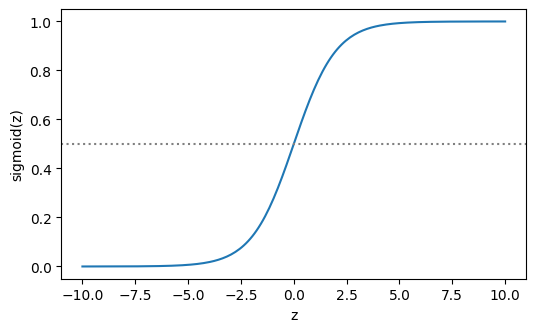

In [ ]:
z = np.array([-10,-2,0,2,10],dtype=float)
y = 1/(1+np.exp(-z))
classes = (y >= 0.5).astype(int)
print(z, y, classes, sep='\n')
grid = np.linspace(-10,10,200)
plt.figure()
plt.plot(grid,sigmoid(grid))
plt.axhline(0.5,color='gray',linestyle=':')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
plt.show()


### 빈칸 문제 53

**문제 상황과 목표**

제한 없는 선형 출력 z를 0–1 사이의 확률로 바꾸고, 확률을 기준으로 이진 분류하세요.

**주어진 데이터와 변수**

`z=[-10,-2,0,2,10]`입니다. 시그모이드의 정의는 1을 (1+e의 −z제곱)으로 나눈 값입니다. 이 문제에서는 확률이 정확히 0.5여도 클래스 1로 둡니다.

**빈칸별 요구사항**

1. `____1____`: np.exp를 사용해 z의 모든 원소에 시그모이드 함수를 적용하세요.
2. `____2____`: 각 확률이 0.5 이상인지 비교하고 True/False를 정수 1/0으로 바꾸세요.

**기대 결과와 확인 기준**

y는 대략 `[0.000045,0.119203,0.5,0.880797,0.999955]`, classes는 `[0,0,1,1,1]`입니다. z가 커질수록 확률이 증가해야 합니다.

**풀이 힌트**

지수는 음의 z입니다. 비교 결과 배열에는 astype을 적용해 자료형을 바꿀 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_53()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_53():
    z = np.array([-10,-2,0,2,10],dtype=float)
    y = ____1____
    classes = ____2____
    print(z, y, classes, sep='\n')
    grid = np.linspace(-10,10,200)
    plt.figure()
    plt.plot(grid,sigmoid(grid))
    plt.axhline(0.5,color='gray',linestyle=':')
    plt.xlabel('z')
    plt.ylabel('sigmoid(z)')
    plt.show()
    assert np.isclose(y[2],0.5)
    assert classes.tolist() == [0,0,1,1,1]
    assert np.all(np.diff(y) > 0)
    print("✅ 문제 53 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_53()


<details>
<summary>문제 53 정답과 확인 코드 보기</summary>

- `____1____` → `1/(1+np.exp(-z))`
- `____2____` → `(y >= 0.5).astype(int)`

```python
def practice_53():
    z = np.array([-10,-2,0,2,10],dtype=float)
    y = 1/(1+np.exp(-z))
    classes = (y >= 0.5).astype(int)
    print(z, y, classes, sep='\n')
    grid = np.linspace(-10,10,200)
    plt.figure()
    plt.plot(grid,sigmoid(grid))
    plt.axhline(0.5,color='gray',linestyle=':')
    plt.xlabel('z')
    plt.ylabel('sigmoid(z)')
    plt.show()
    assert np.isclose(y[2],0.5)
    assert classes.tolist() == [0,0,1,1,1]
    assert np.all(np.diff(y) > 0)
    print("✅ 문제 53 통과")

practice_53()
```

</details>


<a id="example-54"></a>

## 54. 크로스엔트로피: 정답 확률

**출처:** 03번 슬라이드 19

정답 t=1이면 손실은 −log(y), 정답 t=0이면 −log(1−y)입니다. 정답에 높은 확률을 주면 손실이 작아집니다.

### 예제 코드


In [ ]:
T = np.array([1,0],dtype=float)
Y = np.array([0.78,0.07],dtype=float)
correct_prob = T*Y+(1-T)*(1-Y)
terms = -(T*np.log(Y)+(1-T)*np.log(1-Y))
total = terms.sum()
average = terms.mean()
print('정답 확률:',correct_prob,'개별 손실:',terms)
print('합계/평균:',total,average)


정답 확률: [0.78 0.93] 개별 손실: [0.2485 0.0726]
합계/평균: 0.3210320521333351 0.16051602606666754


### 빈칸 문제 54

**문제 상황과 목표**

모델이 정답에 부여한 확률과 그 확률에서 발생하는 크로스엔트로피 손실을 샘플별로 계산하세요.

**주어진 데이터와 변수**

`T=[1,0]`, 클래스 1로 예측한 확률은 `Y=[0.78,0.07]`입니다. 정답이 0인 두 번째 샘플의 정답 확률은 Y가 아니라 1−Y입니다.

**빈칸별 요구사항**

1. `____1____`: 각 샘플에서 T가 1이면 Y, T가 0이면 1−Y가 선택되는 식을 작성하세요.
2. `____2____`: 각 샘플의 이진 크로스엔트로피를 계산하세요. 정답 1의 항은 −log(Y), 정답 0의 항은 −log(1−Y)이며 T와 1−T로 두 경우를 하나의 식에 표현합니다.

**기대 결과와 확인 기준**

correct_prob는 `[0.78,0.93]`, 개별 손실 terms는 약 `[0.248461,0.072571]`입니다. 합계는 약 0.321032, 평균은 약 0.160516으로 합계의 절반입니다.

**풀이 힌트**

로그는 자연로그 np.log를 사용합니다. 두 번째 빈칸에서는 아직 합계·평균을 내지 말고 샘플 두 개의 손실 배열을 만드세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_54()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_54():
    T = np.array([1,0],dtype=float)
    Y = np.array([0.78,0.07],dtype=float)
    correct_prob = ____1____
    terms = ____2____
    total = terms.sum()
    average = terms.mean()
    print('정답 확률:',correct_prob,'개별 손실:',terms)
    print('합계/평균:',total,average)
    assert np.allclose(correct_prob,[0.78,0.93])
    assert np.allclose(terms,-np.log([0.78,0.93]))
    assert np.isclose(total,2*average)
    print("✅ 문제 54 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_54()


<details>
<summary>문제 54 정답과 확인 코드 보기</summary>

- `____1____` → `T*Y+(1-T)*(1-Y)`
- `____2____` → `-(T*np.log(Y)+(1-T)*np.log(1-Y))`

```python
def practice_54():
    T = np.array([1,0],dtype=float)
    Y = np.array([0.78,0.07],dtype=float)
    correct_prob = T*Y+(1-T)*(1-Y)
    terms = -(T*np.log(Y)+(1-T)*np.log(1-Y))
    total = terms.sum()
    average = terms.mean()
    print('정답 확률:',correct_prob,'개별 손실:',terms)
    print('합계/평균:',total,average)
    assert np.allclose(correct_prob,[0.78,0.93])
    assert np.allclose(terms,-np.log([0.78,0.93]))
    assert np.isclose(total,2*average)
    print("✅ 문제 54 통과")

practice_54()
```

</details>


<a id="example-55"></a>

## 55. 우도와 음의 로그우도: M1·M2 비교

**출처:** 03번 슬라이드 20

독립 표본의 우도는 정답 확률들의 곱입니다. 로그를 취하면 합으로 바뀌고 부호를 바꾸면 최소화 손실이 됩니다.

### 예제 코드


In [ ]:
T = np.array([1,0,0,1],dtype=float)
M1 = np.array([0.6,0.4,0.3,0.7])
M2 = np.array([0.9,0.1,0.2,0.8])
p1 = T*M1+(1-T)*(1-M1)
p2 = T*M2+(1-T)*(1-M2)
likelihood1 = np.prod(p1)
likelihood2 = np.prod(p2)
loss1 = -np.log(p1).sum()
loss2 = -np.log(p2).sum()
print('M1:',likelihood1,loss1)
print('M2:',likelihood2,loss2)


M1: 0.1764 1.7350011354094463
M2: 0.5184000000000001 0.657008133944072


### 빈칸 문제 55

**문제 상황과 목표**

두 모델이 정답을 얼마나 그럴듯하게 예측했는지 우도와 음의 로그우도로 비교하세요.

**주어진 데이터와 변수**

정답 T는 `[1,0,0,1]`입니다. 클래스 1의 예측 확률은 M1=`[0.6,0.4,0.3,0.7]`, M2=`[0.9,0.1,0.2,0.8]`입니다. p1과 p2에는 각 모델이 정답에 부여한 확률이 이미 계산되어 있습니다.

**빈칸별 요구사항**

1. `____1____`: 모델 M1의 각 샘플 정답 확률 p1을 모두 곱해 우도를 구하세요.
2. `____2____`: 모델 M2의 정답 확률 p2를 모두 곱해 우도를 구하세요.
3. `____3____`: p1에 자연로그를 적용해 합하고, 부호를 바꿔 M1의 손실을 구하세요.
4. `____4____`: 같은 방식으로 p2에서 M2의 손실을 구하세요.

**기대 결과와 확인 기준**

M1의 우도는 0.1764, M2는 0.5184입니다. 우도가 더 큰 M2의 음의 로그우도는 더 작아야 합니다. loss1은 T,M1으로 계산한 합계 BCE와 같습니다.

**풀이 힌트**

독립 표본의 우도는 확률의 곱입니다. 로그를 취하면 곱이 합이 되고, 앞에 음수를 붙이면 최대화할 값을 최소화 손실로 바꿀 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_55()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_55():
    T = np.array([1,0,0,1],dtype=float)
    M1 = np.array([0.6,0.4,0.3,0.7])
    M2 = np.array([0.9,0.1,0.2,0.8])
    p1 = T*M1+(1-T)*(1-M1)
    p2 = T*M2+(1-T)*(1-M2)
    likelihood1 = ____1____
    likelihood2 = ____2____
    loss1 = ____3____
    loss2 = ____4____
    print('M1:',likelihood1,loss1)
    print('M2:',likelihood2,loss2)
    assert np.isclose(likelihood1,0.1764)
    assert np.isclose(likelihood2,0.5184)
    assert likelihood2 > likelihood1 and loss2 < loss1
    assert np.isclose(loss1,bce(T,M1))
    print("✅ 문제 55 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_55()


<details>
<summary>문제 55 정답과 확인 코드 보기</summary>

- `____1____` → `np.prod(p1)`
- `____2____` → `np.prod(p2)`
- `____3____` → `-np.log(p1).sum()`
- `____4____` → `-np.log(p2).sum()`

```python
def practice_55():
    T = np.array([1,0,0,1],dtype=float)
    M1 = np.array([0.6,0.4,0.3,0.7])
    M2 = np.array([0.9,0.1,0.2,0.8])
    p1 = T*M1+(1-T)*(1-M1)
    p2 = T*M2+(1-T)*(1-M2)
    likelihood1 = np.prod(p1)
    likelihood2 = np.prod(p2)
    loss1 = -np.log(p1).sum()
    loss2 = -np.log(p2).sum()
    print('M1:',likelihood1,loss1)
    print('M2:',likelihood2,loss2)
    assert np.isclose(likelihood1,0.1764)
    assert np.isclose(likelihood2,0.5184)
    assert likelihood2 > likelihood1 and loss2 < loss1
    assert np.isclose(loss1,bce(T,M1))
    print("✅ 문제 55 통과")

practice_55()
```

</details>


<a id="example-56"></a>

## 56. 로지스틱 손실의 수치미분과 분석적 기울기

**출처:** 03번 슬라이드 14·19·21

합계 BCE의 기울기는 W에 대해 `X.T@(Y−T)`, b에 대해 `(Y−T).sum()`입니다. 수치미분으로 같은 결과인지 비교할 수 있습니다.

> **보완:** P04의 수치미분 구현과 같은 손실을 확인하는 보충 실습입니다. 긴 반복 학습에서는 계산량을 줄이기 위해 분석적 기울기를 사용합니다.

### 예제 코드


In [ ]:
X = np.array([[2.],[4.],[6.]])
T = np.array([[0.],[0.],[1.]])
W = np.array([[0.2]])
b = np.array([-0.5])
def loss():
    z = X @ W+b
    return float(np.sum(np.logaddexp(0,z)-T*z))
Y = sigmoid(X @ W+b)
numeric_W = numerical_gradient(loss,W)
numeric_b = numerical_gradient(loss,b)
analytic_W = X.T @ (Y-T)
analytic_b = (Y-T).sum(axis=0)
print('W 기울기:',numeric_W,analytic_W)
print('b 기울기:',numeric_b,analytic_b)


W 기울기: [[1.2569]] [[1.2569]]
b 기울기: [0.7177] [0.7177]


### 빈칸 문제 56

**문제 상황과 목표**

같은 로지스틱 손실을 수치미분과 미분 공식으로 각각 계산해 기울기가 일치하는지 확인하세요.

**주어진 데이터와 변수**

X=`[[2],[4],[6]]`, T=`[[0],[0],[1]]`, W=`[[0.2]]`, b=`[-0.5]`입니다. Y는 현재 확률이고 loss는 **합계 BCE**를 반환합니다. b의 수치미분은 이미 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 공통 numerical_gradient 함수에 손실 함수와 W를 전달해 W의 수치미분을 구하세요. loss()의 결과가 아니라 호출 가능한 loss 자체를 전달합니다.
2. `____2____`: 합계 BCE의 W 기울기를 X의 전치와 확률 오차 Y−T의 행렬 곱으로 계산하세요.
3. `____3____`: 합계 BCE의 b 기울기를 확률 오차 Y−T의 샘플 방향 합으로 계산하세요.

**기대 결과와 확인 기준**

numeric_W와 analytic_W는 같은 값, numeric_b와 analytic_b도 같은 값이어야 합니다(오차 1e−6 이내). 계산 뒤 W와 b는 원래 값이어야 합니다.

**풀이 힌트**

합계 손실이므로 기울기에 샘플 수로 나누는 처리를 추가하지 않습니다. X.T의 shape은 (1,3), Y−T는 (3,1)이므로 W 기울기는 (1,1)입니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_56()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_56():
    X = np.array([[2.],[4.],[6.]])
    T = np.array([[0.],[0.],[1.]])
    W = np.array([[0.2]])
    b = np.array([-0.5])
    def loss():
        z = X @ W+b
        return float(np.sum(np.logaddexp(0,z)-T*z))
    Y = sigmoid(X @ W+b)
    numeric_W = ____1____
    numeric_b = numerical_gradient(loss,b)
    analytic_W = ____2____
    analytic_b = ____3____
    print('W 기울기:',numeric_W,analytic_W)
    print('b 기울기:',numeric_b,analytic_b)
    assert np.allclose(numeric_W,analytic_W,atol=1e-6)
    assert np.allclose(numeric_b,analytic_b,atol=1e-6)
    assert np.array_equal(W,[[0.2]]) and np.array_equal(b,[-0.5])
    print("✅ 문제 56 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_56()


<details>
<summary>문제 56 정답과 확인 코드 보기</summary>

- `____1____` → `numerical_gradient(loss,W)`
- `____2____` → `X.T @ (Y-T)`
- `____3____` → `(Y-T).sum(axis=0)`

```python
def practice_56():
    X = np.array([[2.],[4.],[6.]])
    T = np.array([[0.],[0.],[1.]])
    W = np.array([[0.2]])
    b = np.array([-0.5])
    def loss():
        z = X @ W+b
        return float(np.sum(np.logaddexp(0,z)-T*z))
    Y = sigmoid(X @ W+b)
    numeric_W = numerical_gradient(loss,W)
    numeric_b = numerical_gradient(loss,b)
    analytic_W = X.T @ (Y-T)
    analytic_b = (Y-T).sum(axis=0)
    print('W 기울기:',numeric_W,analytic_W)
    print('b 기울기:',numeric_b,analytic_b)
    assert np.allclose(numeric_W,analytic_W,atol=1e-6)
    assert np.allclose(numeric_b,analytic_b,atol=1e-6)
    assert np.array_equal(W,[[0.2]]) and np.array_equal(b,[-0.5])
    print("✅ 문제 56 통과")

practice_56()
```

</details>


<a id="example-57"></a>

## 57. 공부시간 단일 변수 로지스틱 회귀

**출처:** 03번 슬라이드 21

공부시간 2–12는 0, 14–20은 1입니다. 학습률 0.01로 10,000번 반복합니다. 결정 경계는 `−b/W`입니다.

> **보완:** 슬라이드 보고값은 W≈1.15, b≈−14.85, 합계 손실≈0.621입니다. 초기 난수와 업데이트 방식에 따라 실행 값은 달라집니다.

### 예제 코드


초기/최종 손실: 31.79403370769342 0.6230144286272423
W/b: [1.1501] [-14.8261] 결정 경계: 12.891528656833795
     시간   Pass 확률  분류
0  12.0  0.263993   0
1  13.0  0.531147   1
2  23.0  0.999991   1


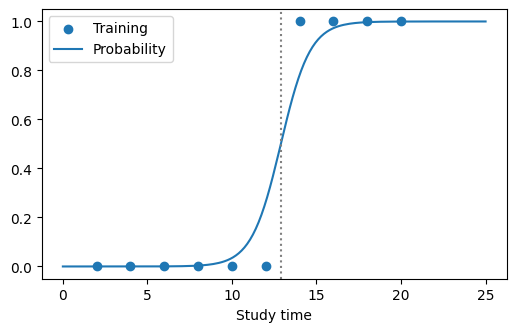

In [ ]:
X = np.arange(2,21,2,dtype=float).reshape(-1,1)
T = np.array([0,0,0,0,0,0,1,1,1,1]).reshape(-1,1)
model = fit_logistic(X,T,lr=0.01,steps=10000)
test = np.array([[12],[13],[23]],dtype=float)
probabilities = predict_probability(test,model)
classes = predict_class(test,model)
boundary = -model['b'].item()/model['W'].item()
print('초기/최종 손실:',model['initial_loss'],model['loss'])
print('W/b:',model['W'].ravel(),model['b'],'결정 경계:',boundary)
print(pd.DataFrame({'시간':test.ravel(),'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))
grid = np.linspace(0,25,150).reshape(-1,1)
plt.figure()
plt.scatter(X.ravel(),T.ravel(),label='Training')
plt.plot(grid.ravel(),predict_probability(grid,model).ravel(),label='Probability')
plt.axvline(boundary,color='gray',linestyle=':')
plt.legend()
plt.xlabel('Study time')
plt.show()


### 빈칸 문제 57

**문제 상황과 목표**

공부시간 한 개로 합격 여부를 분류하는 모델을 학습하고, Pass 확률이 0.5가 되는 공부시간 경계를 구하세요.

**주어진 데이터와 변수**

공부시간은 2부터 20까지 2시간 간격입니다. 2–12시간은 Fail(0), 14–20시간은 Pass(1)입니다. 정답 T와 테스트 시간 12·13·23은 이미 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 공부시간 10개를 실수 배열로 만들고 샘플 10개·특성 1개의 열 벡터로 바꾸세요.
2. `____2____`: fit_logistic에 X,T를 전달하고 학습률 0.01·반복 10,000회로 학습하세요.
3. `____3____`: W×x+b=0을 x에 대해 풀어 결정 경계를 구하세요. model의 W와 b는 원소 하나짜리 배열이므로 스칼라로 꺼내 계산하세요.

**기대 결과와 확인 기준**

X=(10,1), 합계 손실은 1 미만, 결정 경계는 12–14시간 사이입니다. 12시간은 Fail, 23시간은 Pass이며 학습 데이터 10개를 모두 맞혀야 합니다.

**풀이 힌트**

시그모이드는 선형 입력 z가 0일 때 확률 0.5입니다. 따라서 경계는 확률식 전체를 풀 필요 없이 직선의 0점으로 구합니다. .item()으로 배열의 단일 값을 꺼낼 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_57()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_57():
    X = ____1____
    T = np.array([0,0,0,0,0,0,1,1,1,1]).reshape(-1,1)
    model = ____2____
    test = np.array([[12],[13],[23]],dtype=float)
    probabilities = predict_probability(test,model)
    classes = predict_class(test,model)
    boundary = ____3____
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'],'결정 경계:',boundary)
    print(pd.DataFrame({'시간':test.ravel(),'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))
    grid = np.linspace(0,25,150).reshape(-1,1)
    plt.figure()
    plt.scatter(X.ravel(),T.ravel(),label='Training')
    plt.plot(grid.ravel(),predict_probability(grid,model).ravel(),label='Probability')
    plt.axvline(boundary,color='gray',linestyle=':')
    plt.legend()
    plt.xlabel('Study time')
    plt.show()
    assert X.shape == (10,1)
    assert model["loss"] < 1
    assert 12 < boundary < 14
    assert classes[0,0] == 0 and classes[2,0] == 1
    assert np.array_equal(predict_class(X,model),T)
    print("✅ 문제 57 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_57()


<details>
<summary>문제 57 정답과 확인 코드 보기</summary>

- `____1____` → `np.arange(2,21,2,dtype=float).reshape(-1,1)`
- `____2____` → `fit_logistic(X,T,lr=0.01,steps=10000)`
- `____3____` → `-model['b'].item()/model['W'].item()`

```python
def practice_57():
    X = np.arange(2,21,2,dtype=float).reshape(-1,1)
    T = np.array([0,0,0,0,0,0,1,1,1,1]).reshape(-1,1)
    model = fit_logistic(X,T,lr=0.01,steps=10000)
    test = np.array([[12],[13],[23]],dtype=float)
    probabilities = predict_probability(test,model)
    classes = predict_class(test,model)
    boundary = -model['b'].item()/model['W'].item()
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'],'결정 경계:',boundary)
    print(pd.DataFrame({'시간':test.ravel(),'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))
    grid = np.linspace(0,25,150).reshape(-1,1)
    plt.figure()
    plt.scatter(X.ravel(),T.ravel(),label='Training')
    plt.plot(grid.ravel(),predict_probability(grid,model).ravel(),label='Probability')
    plt.axvline(boundary,color='gray',linestyle=':')
    plt.legend()
    plt.xlabel('Study time')
    plt.show()
    assert X.shape == (10,1)
    assert model["loss"] < 1
    assert 12 < boundary < 14
    assert classes[0,0] == 0 and classes[2,0] == 1
    assert np.array_equal(predict_class(X,model),T)
    print("✅ 문제 57 통과")

practice_57()
```

</details>


<a id="example-58"></a>

## 58. 예습·복습 다변수 로지스틱 회귀

**출처:** 03번 슬라이드 22

입력 열이 2개이므로 W=(2,1)입니다. 학습률 0.01·80,000회 조건을 사용하고 네 가지 미지 입력을 분류합니다.

> **보완:** 슬라이드 보고값은 W=[2.28,1.06], b≈−26.82, 확률≈[0.128,0.001,0.999,0.635]입니다. 반올림된 계수와 출력은 정확히 일치하지 않을 수 있습니다.

### 예제 코드


In [ ]:
X = np.array([[2,4],[4,11],[6,6],[8,5],[10,7],[12,16],[14,8],[16,3],[18,7]],dtype=float)
T = np.array([0,0,0,0,1,1,1,1,1]).reshape(-1,1)

model = fit_logistic(X,T,lr=0.01,steps=80000)
test = np.array([[3,17],[5,8],[7,21],[12,0]],dtype=float)
probabilities = predict_probability(test,model)
classes = predict_class(test,model)
print('초기/최종 손실:',model['initial_loss'],model['loss'])
print('W/b:',model['W'].ravel(),model['b'])
print(pd.DataFrame({'예습':test[:,0],'복습':test[:,1],'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))


초기/최종 손실: 38.935937794815786 0.07328691270562408
W/b: [2.281  1.0623] [-26.817]
     예습    복습   Pass 확률  분류
0   3.0  17.0  0.128454   0
1   5.0   8.0  0.000993   0
2   7.0  21.0  0.999989   1
3  12.0   0.0  0.635321   1


### 빈칸 문제 58

**문제 상황과 목표**

예습시간과 복습시간을 함께 고려하는 이진 분류 모델을 학습하고, 새로운 학생 네 명의 Pass 확률과 판정을 구하세요.

**주어진 데이터와 변수**

X는 학생 9명의 `[예습,복습]` 두 열, T는 합격 여부입니다. 테스트 입력은 `[[3,17],[5,8],[7,21],[12,0]]`입니다.

**빈칸별 요구사항**

1. `____1____`: X,T로 fit_logistic을 학습률 0.01·반복 80,000회 호출하세요.
2. `____2____`: test와 model을 이용해 네 학생의 Pass 확률을 구하세요.
3. `____3____`: 같은 입력과 모델로 확률 0.5 이상을 1로 분류한 결과를 구하세요.

**기대 결과와 확인 기준**

W의 shape은 (2,1), 예측은 (4,1), 합계 손실은 0.1 미만입니다. 네 분류는 입력 순서대로 `[0,0,1,1]`, 즉 Fail·Fail·Pass·Pass입니다.

**풀이 힌트**

시간 두 개를 각각 따로 학습하는 것이 아니라 두 열을 한꺼번에 입력으로 사용합니다. 확률과 최종 클래스는 서로 다른 예측 함수를 호출하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_58()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_58():
    X = np.array([[2,4],[4,11],[6,6],[8,5],[10,7],[12,16],[14,8],[16,3],[18,7]],dtype=float)
    T = np.array([0,0,0,0,1,1,1,1,1]).reshape(-1,1)

    model = ____1____
    test = np.array([[3,17],[5,8],[7,21],[12,0]],dtype=float)
    probabilities = ____2____
    classes = ____3____
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'예습':test[:,0],'복습':test[:,1],'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))
    assert model["W"].shape == (2,1)
    assert model["loss"] < 0.1
    assert classes.ravel().tolist() == [0,0,1,1]
    assert np.array_equal(predict_class(X,model),T)
    print("✅ 문제 58 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_58()


<details>
<summary>문제 58 정답과 확인 코드 보기</summary>

- `____1____` → `fit_logistic(X,T,lr=0.01,steps=80000)`
- `____2____` → `predict_probability(test,model)`
- `____3____` → `predict_class(test,model)`

```python
def practice_58():
    X = np.array([[2,4],[4,11],[6,6],[8,5],[10,7],[12,16],[14,8],[16,3],[18,7]],dtype=float)
    T = np.array([0,0,0,0,1,1,1,1,1]).reshape(-1,1)

    model = fit_logistic(X,T,lr=0.01,steps=80000)
    test = np.array([[3,17],[5,8],[7,21],[12,0]],dtype=float)
    probabilities = predict_probability(test,model)
    classes = predict_class(test,model)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'예습':test[:,0],'복습':test[:,1],'Pass 확률':probabilities.ravel(),'분류':classes.ravel()}))
    assert model["W"].shape == (2,1)
    assert model["loss"] < 0.1
    assert classes.ravel().tolist() == [0,0,1,1]
    assert np.array_equal(predict_class(X,model),T)
    print("✅ 문제 58 통과")

practice_58()
```

</details>


<a id="example-59"></a>

## 59. 2변수 회귀의 결정 경계 시각화

**출처:** 03번 슬라이드 22의 분류 예제 보충

meshgrid로 평면의 모든 입력을 만든 뒤 확률을 계산해 다시 격자로 바꿉니다. 확률 0.5인 선이 결정 경계입니다.

> **보완:** P04 실습의 시각화 흐름을 참고한 보충 구현입니다.

### 예제 코드


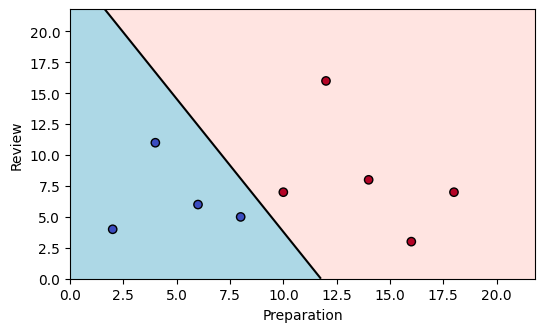

In [ ]:
X = np.array([[2,4],[4,11],[6,6],[8,5],[10,7],[12,16],[14,8],[16,3],[18,7]],dtype=float)
T = np.array([0,0,0,0,1,1,1,1,1]).reshape(-1,1)

# 슬라이드의 보고 계수로 경계를 빠르게 재현. 직전 학습의 model과 별개입니다.
model = {'W':np.array([[2.28],[1.06]]),'b':np.array([-26.82])}
axis = np.arange(0,22,0.2)
xx,yy = np.meshgrid(axis,axis)
grid = np.column_stack([xx.ravel(),yy.ravel()])
probability_grid = predict_probability(grid,model).reshape(xx.shape)
plt.figure()
plt.contourf(xx,yy,probability_grid,levels=[0,0.5,1],colors=['lightblue','mistyrose'])
plt.contour(xx,yy,probability_grid,levels=[0.5],colors='black')
plt.scatter(X[:,0],X[:,1],c=T.ravel(),cmap='coolwarm',edgecolor='black')
plt.xlabel('Preparation')
plt.ylabel('Review')
plt.show()


### 빈칸 문제 59

**문제 상황과 목표**

예습·복습 평면 전체에 모델을 적용해 어느 영역이 Pass인지 색으로 표시하세요. 격자와 모델 입력의 모양을 서로 변환하는 연습입니다.

**주어진 데이터와 변수**

xx,yy는 0부터 22 미만까지 0.2 간격으로 만든 좌표 격자입니다. 슬라이드 보고 계수 W=[2.28,1.06], b=−26.82인 model이 주어져 있어 새로 학습할 필요가 없습니다.

**빈칸별 요구사항**

1. `____1____`: xx와 yy를 각각 1차원으로 펼친 뒤 같은 위치의 x,y가 한 행이 되도록 두 열로 묶으세요.
2. `____2____`: grid의 모든 좌표를 확률로 예측한 뒤, 결과를 원래 격자 xx와 같은 shape으로 되돌리세요.

**기대 결과와 확인 기준**

grid는 (12100,2), probability_grid는 (110,110)이며 모든 값은 0–1입니다. 확률 0.5 경계선과 두 분류 영역이 그림에 표시됩니다.

**풀이 힌트**

ravel은 펼치기, column_stack은 열 결합, reshape는 원래 모양 복구에 사용합니다. 펼칠 때의 좌표 순서가 복구할 때도 유지되어야 합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_59()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_59():
    X = np.array([[2,4],[4,11],[6,6],[8,5],[10,7],[12,16],[14,8],[16,3],[18,7]],dtype=float)
    T = np.array([0,0,0,0,1,1,1,1,1]).reshape(-1,1)

    # 슬라이드의 보고 계수로 경계를 빠르게 재현. 직전 학습의 model과 별개입니다.
    model = {'W':np.array([[2.28],[1.06]]),'b':np.array([-26.82])}
    axis = np.arange(0,22,0.2)
    xx,yy = np.meshgrid(axis,axis)
    grid = ____1____
    probability_grid = ____2____
    plt.figure()
    plt.contourf(xx,yy,probability_grid,levels=[0,0.5,1],colors=['lightblue','mistyrose'])
    plt.contour(xx,yy,probability_grid,levels=[0.5],colors='black')
    plt.scatter(X[:,0],X[:,1],c=T.ravel(),cmap='coolwarm',edgecolor='black')
    plt.xlabel('Preparation')
    plt.ylabel('Review')
    plt.show()
    assert grid.shape == (xx.size,2)
    assert probability_grid.shape == xx.shape
    assert np.all((probability_grid >= 0)&(probability_grid <= 1))
    print("✅ 문제 59 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_59()


<details>
<summary>문제 59 정답과 확인 코드 보기</summary>

- `____1____` → `np.column_stack([xx.ravel(),yy.ravel()])`
- `____2____` → `predict_probability(grid,model).reshape(xx.shape)`

```python
def practice_59():
    X = np.array([[2,4],[4,11],[6,6],[8,5],[10,7],[12,16],[14,8],[16,3],[18,7]],dtype=float)
    T = np.array([0,0,0,0,1,1,1,1,1]).reshape(-1,1)

    # 슬라이드의 보고 계수로 경계를 빠르게 재현. 직전 학습의 model과 별개입니다.
    model = {'W':np.array([[2.28],[1.06]]),'b':np.array([-26.82])}
    axis = np.arange(0,22,0.2)
    xx,yy = np.meshgrid(axis,axis)
    grid = np.column_stack([xx.ravel(),yy.ravel()])
    probability_grid = predict_probability(grid,model).reshape(xx.shape)
    plt.figure()
    plt.contourf(xx,yy,probability_grid,levels=[0,0.5,1],colors=['lightblue','mistyrose'])
    plt.contour(xx,yy,probability_grid,levels=[0.5],colors='black')
    plt.scatter(X[:,0],X[:,1],c=T.ravel(),cmap='coolwarm',edgecolor='black')
    plt.xlabel('Preparation')
    plt.ylabel('Review')
    plt.show()
    assert grid.shape == (xx.size,2)
    assert probability_grid.shape == xx.shape
    assert np.all((probability_grid >= 0)&(probability_grid <= 1))
    print("✅ 문제 59 통과")

practice_59()
```

</details>


<a id="example-60"></a>

## 60. 논리 게이트 진리표와 NOT

**출처:** 03번 슬라이드 23–24

게이트의 입력·출력은 분류 학습 데이터입니다. AND·OR·NAND·XOR는 2입력, NOT은 1입력입니다. 뉴런은 가중합에 활성함수를 적용합니다.

### 예제 코드


In [ ]:
X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=int)
and_t = (X[:,0] & X[:,1]).reshape(-1,1)
or_t = (X[:,0] | X[:,1]).reshape(-1,1)
nand_t = 1-and_t
xor_t = (X[:,0] ^ X[:,1]).reshape(-1,1)
table = pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'AND':and_t.ravel(),
                     'OR':or_t.ravel(),'NAND':nand_t.ravel(),'XOR':xor_t.ravel()})
not_x = np.array([[0],[1]])
not_t = 1-not_x
print(table)
print('NOT:',np.column_stack([not_x.ravel(),not_t.ravel()]))


   x1  x2  AND  OR  NAND  XOR
0   0   0    0   0     1    0
1   0   1    0   1     1    1
2   1   0    0   1     1    1
3   1   1    1   1     0    0
NOT: [[0 1]
 [1 0]]


### 빈칸 문제 60

**문제 상황과 목표**

입력 비트 조합을 이용해 논리 게이트의 정답 레이블을 직접 생성하세요.

**주어진 데이터와 변수**

X의 네 행은 `[0,0]`, `[0,1]`, `[1,0]`, `[1,1]`입니다. not_x는 `[0]`, `[1]` 두 행입니다. 두 입력 열은 각각 X의 첫 번째·두 번째 열입니다.

**빈칸별 요구사항**

1. `____1____`: 두 입력이 모두 1일 때만 1인 AND 결과를 만들고 열 벡터로 바꾸세요.
2. `____2____`: 둘 중 하나라도 1이면 1인 OR 결과를 만들고 열 벡터로 바꾸세요.
3. `____3____`: 이미 계산한 AND의 0·1을 뒤집어 NAND를 만드세요.
4. `____4____`: 두 입력이 서로 다를 때만 1인 XOR 결과를 만들고 열 벡터로 바꾸세요.
5. `____5____`: not_x의 각 비트를 뒤집어 NOT 결과를 만드세요.

**기대 결과와 확인 기준**

입력 순서대로 AND=`[0,0,0,1]`, OR=`[0,1,1,1]`, NAND=`[1,1,1,0]`, XOR=`[0,1,1,0]`입니다. NOT은 `[1,0]`입니다.

**풀이 힌트**

정수 0·1 배열에는 비트 연산자 &·|·^를 사용할 수 있습니다. 0·1의 반전은 1에서 값을 빼는 방법으로도 계산할 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_60()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_60():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=int)
    and_t = ____1____
    or_t = ____2____
    nand_t = ____3____
    xor_t = ____4____
    table = pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'AND':and_t.ravel(),
                         'OR':or_t.ravel(),'NAND':nand_t.ravel(),'XOR':xor_t.ravel()})
    not_x = np.array([[0],[1]])
    not_t = ____5____
    print(table)
    print('NOT:',np.column_stack([not_x.ravel(),not_t.ravel()]))
    assert and_t.ravel().tolist() == [0,0,0,1]
    assert or_t.ravel().tolist() == [0,1,1,1]
    assert nand_t.ravel().tolist() == [1,1,1,0]
    assert xor_t.ravel().tolist() == [0,1,1,0]
    assert not_t.ravel().tolist() == [1,0]
    print("✅ 문제 60 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_60()


<details>
<summary>문제 60 정답과 확인 코드 보기</summary>

- `____1____` → `(X[:,0] & X[:,1]).reshape(-1,1)`
- `____2____` → `(X[:,0] | X[:,1]).reshape(-1,1)`
- `____3____` → `1-and_t`
- `____4____` → `(X[:,0] ^ X[:,1]).reshape(-1,1)`
- `____5____` → `1-not_x`

```python
def practice_60():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=int)
    and_t = (X[:,0] & X[:,1]).reshape(-1,1)
    or_t = (X[:,0] | X[:,1]).reshape(-1,1)
    nand_t = 1-and_t
    xor_t = (X[:,0] ^ X[:,1]).reshape(-1,1)
    table = pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'AND':and_t.ravel(),
                         'OR':or_t.ravel(),'NAND':nand_t.ravel(),'XOR':xor_t.ravel()})
    not_x = np.array([[0],[1]])
    not_t = 1-not_x
    print(table)
    print('NOT:',np.column_stack([not_x.ravel(),not_t.ravel()]))
    assert and_t.ravel().tolist() == [0,0,0,1]
    assert or_t.ravel().tolist() == [0,1,1,1]
    assert nand_t.ravel().tolist() == [1,1,1,0]
    assert xor_t.ravel().tolist() == [0,1,1,0]
    assert not_t.ravel().tolist() == [1,0]
    print("✅ 문제 60 통과")

practice_60()
```

</details>


<a id="example-61"></a>

## 61. AND 게이트를 로지스틱 회귀로 학습

**출처:** 03번 슬라이드 25

AND 진리표를 합계 BCE로 학습합니다. 학습률 0.01·8,000회이며, 슬라이드의 보고 계수는 W≈[5.1405,5.1406], b≈−7.893입니다.

### 예제 코드


In [ ]:
X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
T = np.array([0, 0, 0, 1]).reshape(-1,1)

model = fit_logistic(X,T,lr=0.01,steps=8000)
probabilities = predict_probability(X,model)
classes = predict_class(X,model)
print('초기/최종 손실:',model['initial_loss'],model['loss'])
print('W/b:',model['W'].ravel(),model['b'])
print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))


초기/최종 손실: 4.716080131788896 0.2116386943690283
W/b: [5.1424 5.1424] [-7.8962]
    x1   x2        확률  분류  정답
0  0.0  0.0  0.000372   0   0
1  0.0  1.0  0.059873   0   0
2  1.0  0.0  0.059871   0   0
3  1.0  1.0  0.915955   1   1


### 빈칸 문제 61

**문제 상황과 목표**

AND 게이트의 진리표를 학습 데이터로 만들어, 로지스틱 뉴런 하나가 같은 출력을 내도록 학습시키세요.

**주어진 데이터와 변수**

X의 네 행은 [0,0]·[0,1]·[1,0]·[1,1] 순서입니다. AND의 규칙은 “두 입력이 모두 1일 때만 1”입니다. probabilities를 구하는 코드는 이미 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 규칙에 따라 네 입력의 정답 T를 NumPy 배열로 만들고 (4,1) 열 벡터로 바꾸세요.
2. `____2____`: fit_logistic에 X,T를 전달하고 학습률 0.01·반복 8,000회로 모델을 학습하세요.
3. `____3____`: 학습한 모델로 X를 다시 분류하여 네 개의 정수 클래스(0/1)를 구하세요.

**기대 결과와 확인 기준**

확률이 아니라 최종 분류 classes를 펼쳤을 때 `[0, 0, 0, 1]`가 되어야 합니다. 확률·정답·분류의 shape은 (4,1)이고 최종 손실은 초기보다 작아야 합니다.

**풀이 힌트**

T는 입력 행 순서에 맞춰 작성합니다. 정답 리스트를 classes에 복사하지 말고 predict_class를 통해 학습된 모델의 실제 출력을 확인하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_61()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_61():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
    T = ____1____

    model = ____2____
    probabilities = predict_probability(X,model)
    classes = ____3____
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))
    assert model["loss"] < model["initial_loss"]
    assert np.array_equal(classes,T)
    print("✅ 문제 61 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_61()


<details>
<summary>문제 61 정답과 확인 코드 보기</summary>

- `____1____` → `np.array([0, 0, 0, 1]).reshape(-1,1)`
- `____2____` → `fit_logistic(X,T,lr=0.01,steps=8000)`
- `____3____` → `predict_class(X,model)`

```python
def practice_61():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
    T = np.array([0, 0, 0, 1]).reshape(-1,1)

    model = fit_logistic(X,T,lr=0.01,steps=8000)
    probabilities = predict_probability(X,model)
    classes = predict_class(X,model)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))
    assert model["loss"] < model["initial_loss"]
    assert np.array_equal(classes,T)
    print("✅ 문제 61 통과")

practice_61()
```

</details>


<a id="example-62"></a>

## 62. OR 게이트를 로지스틱 회귀로 학습

**출처:** 03번 슬라이드 25

OR 진리표를 합계 BCE로 학습합니다. 학습률 0.01·8,000회이며, 슬라이드의 보고 계수는 W≈[6.357,6.356], b≈−2.697입니다.

### 예제 코드


In [ ]:
X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
T = np.array([0, 1, 1, 1]).reshape(-1,1)

model = fit_logistic(X,T,lr=0.01,steps=8000)
probabilities = predict_probability(X,model)
classes = predict_class(X,model)
print('초기/최종 손실:',model['initial_loss'],model['loss'])
print('W/b:',model['W'].ravel(),model['b'])
print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))


초기/최종 손실: 1.6423994837242675 0.11704190132194368
W/b: [6.339  6.3415] [-2.689]
    x1   x2        확률  분류  정답
0  0.0  0.0  0.063627   0   0
1  0.0  1.0  0.974729   1   1
2  1.0  0.0  0.974667   1   1
3  1.0  1.0  0.999954   1   1


### 빈칸 문제 62

**문제 상황과 목표**

OR 게이트의 진리표를 학습 데이터로 만들어, 로지스틱 뉴런 하나가 같은 출력을 내도록 학습시키세요.

**주어진 데이터와 변수**

X의 네 행은 [0,0]·[0,1]·[1,0]·[1,1] 순서입니다. OR의 규칙은 “두 입력 중 하나라도 1이면 1”입니다. probabilities를 구하는 코드는 이미 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 규칙에 따라 네 입력의 정답 T를 NumPy 배열로 만들고 (4,1) 열 벡터로 바꾸세요.
2. `____2____`: fit_logistic에 X,T를 전달하고 학습률 0.01·반복 8,000회로 모델을 학습하세요.
3. `____3____`: 학습한 모델로 X를 다시 분류하여 네 개의 정수 클래스(0/1)를 구하세요.

**기대 결과와 확인 기준**

확률이 아니라 최종 분류 classes를 펼쳤을 때 `[0, 1, 1, 1]`가 되어야 합니다. 확률·정답·분류의 shape은 (4,1)이고 최종 손실은 초기보다 작아야 합니다.

**풀이 힌트**

T는 입력 행 순서에 맞춰 작성합니다. 정답 리스트를 classes에 복사하지 말고 predict_class를 통해 학습된 모델의 실제 출력을 확인하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_62()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_62():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
    T = ____1____

    model = ____2____
    probabilities = predict_probability(X,model)
    classes = ____3____
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))
    assert model["loss"] < model["initial_loss"]
    assert np.array_equal(classes,T)
    print("✅ 문제 62 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_62()


<details>
<summary>문제 62 정답과 확인 코드 보기</summary>

- `____1____` → `np.array([0, 1, 1, 1]).reshape(-1,1)`
- `____2____` → `fit_logistic(X,T,lr=0.01,steps=8000)`
- `____3____` → `predict_class(X,model)`

```python
def practice_62():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
    T = np.array([0, 1, 1, 1]).reshape(-1,1)

    model = fit_logistic(X,T,lr=0.01,steps=8000)
    probabilities = predict_probability(X,model)
    classes = predict_class(X,model)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))
    assert model["loss"] < model["initial_loss"]
    assert np.array_equal(classes,T)
    print("✅ 문제 62 통과")

practice_62()
```

</details>


<a id="example-63"></a>

## 63. NAND 게이트를 로지스틱 회귀로 학습

**출처:** 03번 슬라이드 25

NAND 진리표를 합계 BCE로 학습합니다. 학습률 0.01·8,000회이며, 슬라이드의 보고 계수는 W≈[−5.131,−5.131], b≈7.879입니다.

### 예제 코드


In [ ]:
X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
T = np.array([1, 1, 1, 0]).reshape(-1,1)

model = fit_logistic(X,T,lr=0.01,steps=8000)
probabilities = predict_probability(X,model)
classes = predict_class(X,model)
print('초기/최종 손실:',model['initial_loss'],model['loss'])
print('W/b:',model['W'].ravel(),model['b'])
print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))


초기/최종 손실: 3.1647087512985097 0.2142379871312195
W/b: [-5.1171 -5.1171] [7.8585]
    x1   x2        확률  분류  정답
0  0.0  0.0  0.999614   1   1
1  0.0  1.0  0.939424   1   1
2  1.0  0.0  0.939422   1   1
3  1.0  1.0  0.085039   0   0


### 빈칸 문제 63

**문제 상황과 목표**

NAND 게이트의 진리표를 학습 데이터로 만들어, 로지스틱 뉴런 하나가 같은 출력을 내도록 학습시키세요.

**주어진 데이터와 변수**

X의 네 행은 [0,0]·[0,1]·[1,0]·[1,1] 순서입니다. NAND의 규칙은 “두 입력이 모두 1일 때만 0이고 그 외는 1”입니다. probabilities를 구하는 코드는 이미 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 규칙에 따라 네 입력의 정답 T를 NumPy 배열로 만들고 (4,1) 열 벡터로 바꾸세요.
2. `____2____`: fit_logistic에 X,T를 전달하고 학습률 0.01·반복 8,000회로 모델을 학습하세요.
3. `____3____`: 학습한 모델로 X를 다시 분류하여 네 개의 정수 클래스(0/1)를 구하세요.

**기대 결과와 확인 기준**

확률이 아니라 최종 분류 classes를 펼쳤을 때 `[1, 1, 1, 0]`가 되어야 합니다. 확률·정답·분류의 shape은 (4,1)이고 최종 손실은 초기보다 작아야 합니다.

**풀이 힌트**

T는 입력 행 순서에 맞춰 작성합니다. 정답 리스트를 classes에 복사하지 말고 predict_class를 통해 학습된 모델의 실제 출력을 확인하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_63()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_63():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
    T = ____1____

    model = ____2____
    probabilities = predict_probability(X,model)
    classes = ____3____
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))
    assert model["loss"] < model["initial_loss"]
    assert np.array_equal(classes,T)
    print("✅ 문제 63 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_63()


<details>
<summary>문제 63 정답과 확인 코드 보기</summary>

- `____1____` → `np.array([1, 1, 1, 0]).reshape(-1,1)`
- `____2____` → `fit_logistic(X,T,lr=0.01,steps=8000)`
- `____3____` → `predict_class(X,model)`

```python
def practice_63():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
    T = np.array([1, 1, 1, 0]).reshape(-1,1)

    model = fit_logistic(X,T,lr=0.01,steps=8000)
    probabilities = predict_probability(X,model)
    classes = predict_class(X,model)
    print('초기/최종 손실:',model['initial_loss'],model['loss'])
    print('W/b:',model['W'].ravel(),model['b'])
    print(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'확률':probabilities.ravel(),'분류':classes.ravel(),'정답':T.ravel()}))
    assert model["loss"] < model["initial_loss"]
    assert np.array_equal(classes,T)
    print("✅ 문제 63 통과")

practice_63()
```

</details>


<a id="example-64"></a>

## 64. XOR를 단일 뉴런으로 학습하면

**출처:** 03번 슬라이드 25

XOR의 두 클래스는 직선 하나로 분리할 수 없습니다. 단일 로지스틱 뉴런의 확률은 약 0.5에 머물며, 합계 BCE는 약 4×log(2)=2.7726입니다.

> **보완:** 0.5 근처의 부동소수점 오차와 경계 처리에 따라 출력 0·1 조합은 달라질 수 있어 특정 오답 패턴을 강제하지 않습니다.

### 예제 코드


In [ ]:
X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)

T = np.array([0,1,1,0]).reshape(-1,1)
model = fit_logistic(X,T,lr=0.01,steps=8000)
probabilities = predict_probability(X,model)
classes = predict_class(X,model)
accuracy = np.mean(classes == T)
print('최종 손실:',model['loss'],'4log(2):',4*np.log(2))
print('확률:',probabilities.ravel(),'정확도:',accuracy)


최종 손실: 2.7725887222398957 4log(2): 2.772588722239781
확률: [0.5 0.5 0.5 0.5] 정확도: 0.25


### 빈칸 문제 64

**문제 상황과 목표**

XOR 진리표를 단일 로지스틱 뉴런으로 학습해 보고, 학습 호출이 정상이어도 모든 문제를 풀 수 있는 것은 아니라는 점을 확인하세요.

**주어진 데이터와 변수**

X의 행 순서는 [0,0]·[0,1]·[1,0]·[1,1]입니다. XOR는 두 입력이 다를 때만 1입니다. 학습과 확률·클래스 예측 코드는 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: XOR 규칙에 맞는 네 정답을 입력 순서대로 만들고 (4,1) 열 벡터로 바꾸세요.
2. `____2____`: classes와 T가 같은지를 원소별로 비교한 뒤 맞은 비율을 평균으로 구하세요.

**기대 결과와 확인 기준**

T는 `[0,1,1,0]`입니다. 학습 후 네 확률은 모두 약 0.5, 합계 손실은 약 2.7726이며 정확도는 1보다 작습니다. 이 문제의 목표는 100% 달성이 아니라 한계 확인입니다.

**풀이 힌트**

두 클래스가 직선 한 개로 분리되지 않으면 단일 로지스틱 뉴런으로 완벽히 분류할 수 없습니다. 확률이 0.5 근처일 때의 구체적 오답 패턴은 고정하지 않습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_64()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_64():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)

    T = ____1____
    model = fit_logistic(X,T,lr=0.01,steps=8000)
    probabilities = predict_probability(X,model)
    classes = predict_class(X,model)
    accuracy = ____2____
    print('최종 손실:',model['loss'],'4log(2):',4*np.log(2))
    print('확률:',probabilities.ravel(),'정확도:',accuracy)
    assert np.allclose(probabilities,0.5,atol=0.01)
    assert np.isclose(model["loss"],4*np.log(2),atol=0.01)
    assert accuracy < 1
    print("✅ 문제 64 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_64()


<details>
<summary>문제 64 정답과 확인 코드 보기</summary>

- `____1____` → `np.array([0,1,1,0]).reshape(-1,1)`
- `____2____` → `np.mean(classes == T)`

```python
def practice_64():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)

    T = np.array([0,1,1,0]).reshape(-1,1)
    model = fit_logistic(X,T,lr=0.01,steps=8000)
    probabilities = predict_probability(X,model)
    classes = predict_class(X,model)
    accuracy = np.mean(classes == T)
    print('최종 손실:',model['loss'],'4log(2):',4*np.log(2))
    print('확률:',probabilities.ravel(),'정확도:',accuracy)
    assert np.allclose(probabilities,0.5,atol=0.01)
    assert np.isclose(model["loss"],4*np.log(2),atol=0.01)
    assert accuracy < 1
    print("✅ 문제 64 통과")

practice_64()
```

</details>


<a id="example-65"></a>

## 65. NAND·OR·AND로 다층 XOR 구성

**출처:** 03번 슬라이드 26–27

은닉층에서 NAND와 OR를 계산하고, 그 출력을 AND에 넣으면 XOR가 됩니다. 이전 뉴런의 출력이 다음 뉴런의 입력입니다.

> **보완:** 개념 회로의 실행 구현입니다. 이미 주어진 게이트 가중치를 연결하며 다층 전체를 새로 학습시키는 예제와 구분합니다.

### 예제 코드


In [ ]:
X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)

# 슬라이드의 게이트 보고 계수를 사용해 순전파를 확인
nand_model = {'W':np.array([[-5.131],[-5.131]]),'b':np.array([7.879])}
or_model = {'W':np.array([[6.357],[6.356]]),'b':np.array([-2.697])}
and_model = {'W':np.array([[5.1405],[5.1406]]),'b':np.array([-7.893])}
h_nand = predict_probability(X,nand_model)
h_or = predict_probability(X,or_model)
hidden = np.hstack([h_nand,h_or])
output = predict_probability(hidden,and_model)
classes = (output >= 0.5).astype(int)
print('은닉 출력:',hidden)
print('최종 확률:',output.ravel(),'XOR:',classes.ravel())


은닉 출력: [[0.9996 0.0632]
 [0.9398 0.9749]
 [0.9398 0.9749]
 [0.0845 1.    ]]
최종 확률: [0.0809 0.8754 0.8754 0.0896] XOR: [0 1 1 0]


### 빈칸 문제 65

**문제 상황과 목표**

NAND와 OR의 출력을 다음 AND 뉴런의 입력으로 연결하여, 단일 뉴런이 풀지 못한 XOR를 구현하세요.

**주어진 데이터와 변수**

네 비트 입력 X와 세 게이트의 가중치가 주어져 있습니다. h_nand와 h_or는 각 (4,1) 확률 배열이며, 다음 층에는 샘플마다 두 출력을 한 행으로 전달해야 합니다.

**빈칸별 요구사항**

1. `____1____`: 첫 열이 h_nand, 두 번째 열이 h_or인 은닉 출력 hidden을 만드세요.
2. `____2____`: hidden을 입력으로 and_model의 출력 확률을 계산하세요.
3. `____3____`: 최종 확률이 0.5 이상이면 1, 작으면 0인 정수 classes를 만드세요.

**기대 결과와 확인 기준**

hidden=(4,2), output=(4,1)입니다. 입력 [0,0]·[0,1]·[1,0]·[1,1]에 대한 최종 분류는 `[0,1,1,0]`이어야 합니다.

**풀이 힌트**

같은 샘플의 두 출력을 좌우로 붙이므로 수평 결합합니다. 가운데 층은 주어진 코드처럼 확률값을 그대로 다음 뉴런에 전달하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_65()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_65():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)

    # 슬라이드의 게이트 보고 계수를 사용해 순전파를 확인
    nand_model = {'W':np.array([[-5.131],[-5.131]]),'b':np.array([7.879])}
    or_model = {'W':np.array([[6.357],[6.356]]),'b':np.array([-2.697])}
    and_model = {'W':np.array([[5.1405],[5.1406]]),'b':np.array([-7.893])}
    h_nand = predict_probability(X,nand_model)
    h_or = predict_probability(X,or_model)
    hidden = ____1____
    output = ____2____
    classes = ____3____
    print('은닉 출력:',hidden)
    print('최종 확률:',output.ravel(),'XOR:',classes.ravel())
    assert hidden.shape == (4,2)
    assert classes.ravel().tolist() == [0,1,1,0]
    print("✅ 문제 65 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_65()


<details>
<summary>문제 65 정답과 확인 코드 보기</summary>

- `____1____` → `np.hstack([h_nand,h_or])`
- `____2____` → `predict_probability(hidden,and_model)`
- `____3____` → `(output >= 0.5).astype(int)`

```python
def practice_65():
    X = np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)

    # 슬라이드의 게이트 보고 계수를 사용해 순전파를 확인
    nand_model = {'W':np.array([[-5.131],[-5.131]]),'b':np.array([7.879])}
    or_model = {'W':np.array([[6.357],[6.356]]),'b':np.array([-2.697])}
    and_model = {'W':np.array([[5.1405],[5.1406]]),'b':np.array([-7.893])}
    h_nand = predict_probability(X,nand_model)
    h_or = predict_probability(X,or_model)
    hidden = np.hstack([h_nand,h_or])
    output = predict_probability(hidden,and_model)
    classes = (output >= 0.5).astype(int)
    print('은닉 출력:',hidden)
    print('최종 확률:',output.ravel(),'XOR:',classes.ravel())
    assert hidden.shape == (4,2)
    assert classes.ravel().tolist() == [0,1,1,0]
    print("✅ 문제 65 통과")

practice_65()
```

</details>


<a id="example-66"></a>

## 66. 다층 신경망의 순전파와 shape

**출처:** 03번 슬라이드 28

배치 X=(N,input), 첫 가중치 W1=(input,hidden), 두 번째 W2=(hidden,output)으로 두면 행렬 곱이 이어집니다. 은닉층의 활성함수가 비선형 관계를 표현하게 합니다.

> **보완:** 개념 예제의 실습화입니다. 층 수를 늘린다고 정확도가 자동으로 높아지는 것은 아니며 데이터·학습 조건에 따라 달라집니다.

### 예제 코드


In [ ]:
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
W1 = np.array([[1.,-1.,0.5],[0.5,1.,-1.]])
b1 = np.zeros((1,3))
W2 = np.array([[1.],[-1.],[0.5]])
b2 = np.zeros((1,1))
hidden = sigmoid(X @ W1+b1)
output = sigmoid(hidden @ W2+b2)
print('shape:',X.shape,W1.shape,hidden.shape,W2.shape,output.shape)
print(output)


shape: (4, 2) (2, 3) (4, 3) (3, 1) (4, 1)
[[0.5622]
 [0.5065]
 [0.6842]
 [0.6239]]


### 빈칸 문제 66

**문제 상황과 목표**

입력에서 은닉층, 은닉층에서 출력층으로 계산이 이어지는 신경망의 순전파를 작성하세요.

**주어진 데이터와 변수**

샘플 네 개 X의 shape은 (4,2), W1=(2,3), b1=(1,3), W2=(3,1), b2=(1,1)입니다. 각 층은 선형 가중합 뒤 sigmoid를 적용합니다.

**빈칸별 요구사항**

1. `____1____`: X와 W1을 행렬 곱하고 b1을 더한 뒤 sigmoid를 적용해 hidden을 구하세요.
2. `____2____`: hidden과 W2를 행렬 곱하고 b2를 더한 뒤 sigmoid를 적용해 output을 구하세요.

**기대 결과와 확인 기준**

hidden의 shape은 (4,3), output은 (4,1)이며 출력 확률은 0–1입니다. 가중치는 주어진 값 그대로 사용하며 이 문제에서는 학습하지 않습니다.

**풀이 힌트**

행렬 곱에서 앞 행렬의 열 수와 뒤 행렬의 행 수가 같아야 합니다. 각 층의 출력이 다음 층의 입력으로 들어갑니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_66()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_66():
    X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
    W1 = np.array([[1.,-1.,0.5],[0.5,1.,-1.]])
    b1 = np.zeros((1,3))
    W2 = np.array([[1.],[-1.],[0.5]])
    b2 = np.zeros((1,1))
    hidden = ____1____
    output = ____2____
    print('shape:',X.shape,W1.shape,hidden.shape,W2.shape,output.shape)
    print(output)
    assert hidden.shape == (4,3)
    assert output.shape == (4,1)
    assert np.all((output >= 0)&(output <= 1))
    print("✅ 문제 66 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_66()


<details>
<summary>문제 66 정답과 확인 코드 보기</summary>

- `____1____` → `sigmoid(X @ W1+b1)`
- `____2____` → `sigmoid(hidden @ W2+b2)`

```python
def practice_66():
    X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
    W1 = np.array([[1.,-1.,0.5],[0.5,1.,-1.]])
    b1 = np.zeros((1,3))
    W2 = np.array([[1.],[-1.],[0.5]])
    b2 = np.zeros((1,1))
    hidden = sigmoid(X @ W1+b1)
    output = sigmoid(hidden @ W2+b2)
    print('shape:',X.shape,W1.shape,hidden.shape,W2.shape,output.shape)
    print(output)
    assert hidden.shape == (4,3)
    assert output.shape == (4,1)
    assert np.all((output >= 0)&(output <= 1))
    print("✅ 문제 66 통과")

practice_66()
```

</details>


<a id="example-67"></a>

## 67. XOR 다층 신경망을 역전파로 학습

**출처:** 03번 슬라이드 29, 26–28 보충

출력의 BCE와 시그모이드를 함께 미분하면 출력 오차는 Y−T입니다. 은닉 오차는 다음 층의 가중치와 시그모이드 미분 H(1−H)를 곱합니다. 모든 기울기를 계산한 뒤 가중치를 업데이트합니다.

> **보완:** 개념 예제의 실습화입니다. 원본은 역전파의 개념만 설명하므로 2–4–1 구조와 학습 코드를 보충했습니다. 심층 학습의 역전파는 연쇄법칙으로 미분을 계산합니다.

### 예제 코드


In [ ]:
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
T = np.array([[0.],[1.],[1.],[0.]])
rng = np.random.default_rng(42)
W1 = rng.normal(0,1,(2,4))
b1 = np.zeros((1,4))
W2 = rng.normal(0,1,(4,1))
b2 = np.zeros((1,1))
losses = []
for step in range(12000):
    H = sigmoid(X @ W1+b1)
    Y = sigmoid(H @ W2+b2)
    dZ2 = (Y-T)/len(X)  # 평균 BCE
    dW2 = H.T @ dZ2
    db2 = dZ2.sum(axis=0,keepdims=True)
    dZ1 = (dZ2 @ W2.T)*H*(1-H)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0,keepdims=True)
    W1 -= 0.5*dW1
    b1 -= 0.5*db1
    W2 -= 0.5*dW2
    b2 -= 0.5*db2
    if step % 1000 == 0:
        losses.append(bce(T,Y,reduction='mean'))
H = sigmoid(X @ W1+b1)
Y = sigmoid(H @ W2+b2)
classes = (Y >= 0.5).astype(int)
print('평균 BCE 기록:',np.round(losses,4))
print('XOR 확률:',Y.ravel(),'분류:',classes.ravel())


평균 BCE 기록: [0.7568 0.0643 0.0128 0.0062 0.0039 0.0028 0.0022 0.0018 0.0015 0.0013
 0.0011 0.001 ]
XOR 확률: [0.0004 0.9989 0.9993 0.0013] 분류: [0 1 1 0]


### 빈칸 문제 67

**문제 상황과 목표**

XOR 신경망을 역전파로 학습하세요. 출력 오차에서 시작해 출력층 가중치, 은닉층 오차, 입력층 가중치 순서로 기울기를 계산합니다.

**주어진 데이터와 변수**

X=(4,2), T=(4,1), W1=(2,4), W2=(4,1)입니다. H는 은닉층 sigmoid 출력, Y는 최종 확률입니다. 손실은 **평균 BCE**이며, 학습률 0.5·반복 12,000회·파라미터 업데이트 코드는 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: 출력층 선형 입력의 기울기 dZ2를 구하세요. sigmoid+BCE의 결과는 Y−T이고, 평균 손실이므로 샘플 수로 나눕니다.
2. `____2____`: 은닉 출력 H의 전치와 dZ2를 행렬 곱하여 출력층 가중치 기울기 dW2를 구하세요.
3. `____3____`: dZ2를 W2의 전치로 이전 층에 전달하고, 은닉 sigmoid의 미분 H×(1−H)를 원소별로 곱해 dZ1을 구하세요.
4. `____4____`: 입력 X의 전치와 dZ1을 행렬 곱해 입력층 가중치 기울기 dW1을 구하세요.

**기대 결과와 확인 기준**

dZ2=(4,1), dW2=(4,1), dZ1=(4,4), dW1=(2,4)입니다. 학습 후 분류는 `[0,1,1,0]`, 평균 BCE는 0.02 미만이며 손실 기록이 감소해야 합니다.

**풀이 힌트**

층 사이 전달에는 행렬 곱 @, sigmoid 미분을 붙일 때는 원소별 곱 *를 사용합니다. 네 기울기를 모두 계산한 뒤 파라미터를 업데이트해야 같은 시점의 W2를 사용할 수 있습니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_67()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_67():
    X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
    T = np.array([[0.],[1.],[1.],[0.]])
    rng = np.random.default_rng(42)
    W1 = rng.normal(0,1,(2,4))
    b1 = np.zeros((1,4))
    W2 = rng.normal(0,1,(4,1))
    b2 = np.zeros((1,1))
    losses = []
    for step in range(12000):
        H = sigmoid(X @ W1+b1)
        Y = sigmoid(H @ W2+b2)
        dZ2 = ____1____  # 평균 BCE
        dW2 = ____2____
        db2 = dZ2.sum(axis=0,keepdims=True)
        dZ1 = ____3____
        dW1 = ____4____
        db1 = dZ1.sum(axis=0,keepdims=True)
        W1 -= 0.5*dW1
        b1 -= 0.5*db1
        W2 -= 0.5*dW2
        b2 -= 0.5*db2
        if step % 1000 == 0:
            losses.append(bce(T,Y,reduction='mean'))
    H = sigmoid(X @ W1+b1)
    Y = sigmoid(H @ W2+b2)
    classes = (Y >= 0.5).astype(int)
    print('평균 BCE 기록:',np.round(losses,4))
    print('XOR 확률:',Y.ravel(),'분류:',classes.ravel())
    assert classes.ravel().tolist() == [0,1,1,0]
    assert bce(T,Y,reduction="mean") < 0.02
    assert losses[-1] < losses[0]
    print("✅ 문제 67 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_67()


<details>
<summary>문제 67 정답과 확인 코드 보기</summary>

- `____1____` → `(Y-T)/len(X)`
- `____2____` → `H.T @ dZ2`
- `____3____` → `(dZ2 @ W2.T)*H*(1-H)`
- `____4____` → `X.T @ dZ1`

```python
def practice_67():
    X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
    T = np.array([[0.],[1.],[1.],[0.]])
    rng = np.random.default_rng(42)
    W1 = rng.normal(0,1,(2,4))
    b1 = np.zeros((1,4))
    W2 = rng.normal(0,1,(4,1))
    b2 = np.zeros((1,1))
    losses = []
    for step in range(12000):
        H = sigmoid(X @ W1+b1)
        Y = sigmoid(H @ W2+b2)
        dZ2 = (Y-T)/len(X)  # 평균 BCE
        dW2 = H.T @ dZ2
        db2 = dZ2.sum(axis=0,keepdims=True)
        dZ1 = (dZ2 @ W2.T)*H*(1-H)
        dW1 = X.T @ dZ1
        db1 = dZ1.sum(axis=0,keepdims=True)
        W1 -= 0.5*dW1
        b1 -= 0.5*db1
        W2 -= 0.5*dW2
        b2 -= 0.5*db2
        if step % 1000 == 0:
            losses.append(bce(T,Y,reduction='mean'))
    H = sigmoid(X @ W1+b1)
    Y = sigmoid(H @ W2+b2)
    classes = (Y >= 0.5).astype(int)
    print('평균 BCE 기록:',np.round(losses,4))
    print('XOR 확률:',Y.ravel(),'분류:',classes.ravel())
    assert classes.ravel().tolist() == [0,1,1,0]
    assert bce(T,Y,reduction="mean") < 0.02
    assert losses[-1] < losses[0]
    print("✅ 문제 67 통과")

practice_67()
```

</details>


<a id="example-68"></a>

## 68. MNIST 이미지의 784 입력과 정규화

**출처:** 03번 슬라이드 30–31

MNIST는 학습 60,000개·시험 10,000개, 이미지 한 장은 28×28=784 픽셀입니다. 픽셀 0–255를 255로 나눠 0–1로 바꿉니다.

> **보완:** 개념 예제의 실습화이며 배열은 모양 연습용입니다. 실제 MNIST 다운로드·학습은 마지막 예제에 있습니다.

### 예제 코드


In [ ]:
# 데이터 다운로드 없이 형태만 익히는 보충 배열. 실제 MNIST 이미지가 아님
images = np.arange(2*28*28).reshape(2,28,28)%256
labels = np.array([5,2])
normalized = images.astype('float32')/255.0
flat = normalized.reshape(len(images),-1)
print('이미지/레이블 shape:',images.shape,labels.shape)
print('정규화/평탄화 shape:',normalized.shape,flat.shape)
print('CSV에 레이블도 넣는다면 열 개수:',flat.shape[1]+1)


이미지/레이블 shape: (2, 28, 28) (2,)
정규화/평탄화 shape: (2, 28, 28) (2, 784)
CSV에 레이블도 넣는다면 열 개수: 785


### 빈칸 문제 68

**문제 상황과 목표**

이미지 픽셀의 범위를 0–1로 바꾸고, 이미지 한 장을 신경망에 넣을 길이 784의 벡터로 펼치세요.

**주어진 데이터와 변수**

images는 값이 0–255인 (2,28,28) 연습용 배열입니다. 이미지 두 장이 각각 28행 28열이며, 실제 MNIST 다운로드 데이터는 아닙니다. labels=[5,2]는 이미지와 따로 저장되어 있습니다.

**빈칸별 요구사항**

1. `____1____`: images를 float32로 바꾼 뒤 최대 픽셀값 255로 나눠 normalized를 만드세요.
2. `____2____`: 이미지 개수 두 개는 첫 축에 유지하고, 나머지 두 픽셀 축을 하나로 합쳐 flat을 만드세요. 합쳐질 길이는 -1로 자동 계산하세요.

**기대 결과와 확인 기준**

normalized=(2,28,28)이며 최솟값·최댓값은 0–1 범위입니다. flat=(2,784)입니다. 레이블 한 열까지 함께 저장하는 CSV라면 한 행은 785열이 됩니다.

**풀이 힌트**

배열 전체를 완전히 1차원으로 만들면 두 이미지가 합쳐집니다. 첫 축을 이미지 수로 남겨 각 행이 이미지 한 장이 되게 하세요.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_68()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_68():
    # 데이터 다운로드 없이 형태만 익히는 보충 배열. 실제 MNIST 이미지가 아님
    images = np.arange(2*28*28).reshape(2,28,28)%256
    labels = np.array([5,2])
    normalized = ____1____
    flat = ____2____
    print('이미지/레이블 shape:',images.shape,labels.shape)
    print('정규화/평탄화 shape:',normalized.shape,flat.shape)
    print('CSV에 레이블도 넣는다면 열 개수:',flat.shape[1]+1)
    assert normalized.shape == (2,28,28)
    assert flat.shape == (2,784)
    assert normalized.min() >= 0 and normalized.max() <= 1
    assert flat.shape[1]+1 == 785
    print("✅ 문제 68 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_68()


<details>
<summary>문제 68 정답과 확인 코드 보기</summary>

- `____1____` → `images.astype('float32')/255.0`
- `____2____` → `normalized.reshape(len(images),-1)`

```python
def practice_68():
    # 데이터 다운로드 없이 형태만 익히는 보충 배열. 실제 MNIST 이미지가 아님
    images = np.arange(2*28*28).reshape(2,28,28)%256
    labels = np.array([5,2])
    normalized = images.astype('float32')/255.0
    flat = normalized.reshape(len(images),-1)
    print('이미지/레이블 shape:',images.shape,labels.shape)
    print('정규화/평탄화 shape:',normalized.shape,flat.shape)
    print('CSV에 레이블도 넣는다면 열 개수:',flat.shape[1]+1)
    assert normalized.shape == (2,28,28)
    assert flat.shape == (2,784)
    assert normalized.min() >= 0 and normalized.max() <= 1
    assert flat.shape[1]+1 == 785
    print("✅ 문제 68 통과")

practice_68()
```

</details>


<a id="example-69"></a>

## 69. MNIST 신경망 784–128–64–10 구조

**출처:** 03번 슬라이드 32

32장 그림은 은닉 128·64개와 출력 10개입니다. ReLU는 max(0,z), softmax는 출력 열의 합이 1인 확률 벡터를 만듭니다.

> **보완:** 개념 예제의 실습화입니다. 32장의 2개 은닉층 구조와 34장의 3개 은닉층 구조를 각각 따로 정리했습니다. 이 배열에는 실제 MNIST를 넣지 않았습니다.

### 예제 코드


In [ ]:
rng = np.random.default_rng(32)
X = rng.random((3,784))  # 구조 확인용 가상 픽셀
W1 = rng.normal(0,np.sqrt(2/784),(784,128))
W2 = rng.normal(0,np.sqrt(2/128),(128,64))
W3 = rng.normal(0,np.sqrt(2/64),(64,10))
H1 = np.maximum(0,X @ W1)
H2 = np.maximum(0,H1 @ W2)
logits = H2 @ W3
exp_values = np.exp(logits-logits.max(axis=1,keepdims=True))
probabilities = exp_values/exp_values.sum(axis=1,keepdims=True)
classes = probabilities.argmax(axis=1)
print('shape:',H1.shape,H2.shape,probabilities.shape)
print('확률 합:',probabilities.sum(axis=1),'예측:',classes)


shape: (3, 128) (3, 64) (3, 10)
확률 합: [1. 1. 1.] 예측: [0 8 2]


### 빈칸 문제 69

**문제 상황과 목표**

두 은닉층의 ReLU와 10개 클래스의 softmax를 계산한 뒤 가장 확률이 높은 숫자 클래스를 선택하세요.

**주어진 데이터와 변수**

X=(3,784), W1=(784,128), W2=(128,64), W3=(64,10)입니다. 가상 이미지 세 장을 사용합니다. logits와 안정적인 지수값 exp_values를 만드는 코드는 주어져 있습니다.

**빈칸별 요구사항**

1. `____1____`: X와 W1의 가중합에서 음수는 0으로, 양수는 그대로 두는 ReLU를 적용해 H1을 구하세요.
2. `____2____`: H1과 W2의 가중합에도 같은 ReLU를 적용해 H2를 구하세요.
3. `____3____`: 각 이미지의 지수값 10개를 그 이미지의 지수값 합으로 나눠 확률을 만드세요. 나눗셈을 위해 합계의 열 축을 유지하세요.
4. `____4____`: 각 이미지에서 확률이 가장 큰 열의 인덱스를 구해 0–9 클래스 번호를 만드세요.

**기대 결과와 확인 기준**

H1=(3,128), H2=(3,64), probabilities=(3,10), classes=(3,)입니다. 이미지마다 확률 합은 1이고 클래스는 0–9입니다. 학습하지 않은 가상 데이터이므로 특정 숫자를 맞히지는 않습니다.

**풀이 힌트**

np.maximum으로 음수 부분을 없앨 수 있습니다. 확률을 합할 때 샘플 축이 아니라 클래스 축을 합하고 keepdims로 차원을 유지하세요. 최대값 자체 대신 최대값의 위치를 구합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_69()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_69():
    rng = np.random.default_rng(32)
    X = rng.random((3,784))  # 구조 확인용 가상 픽셀
    W1 = rng.normal(0,np.sqrt(2/784),(784,128))
    W2 = rng.normal(0,np.sqrt(2/128),(128,64))
    W3 = rng.normal(0,np.sqrt(2/64),(64,10))
    H1 = ____1____
    H2 = ____2____
    logits = H2 @ W3
    exp_values = np.exp(logits-logits.max(axis=1,keepdims=True))
    probabilities = ____3____
    classes = ____4____
    print('shape:',H1.shape,H2.shape,probabilities.shape)
    print('확률 합:',probabilities.sum(axis=1),'예측:',classes)
    assert H1.shape == (3,128) and H2.shape == (3,64)
    assert probabilities.shape == (3,10)
    assert np.allclose(probabilities.sum(axis=1),1)
    assert np.all((classes >= 0)&(classes < 10))
    print("✅ 문제 69 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_69()


<details>
<summary>문제 69 정답과 확인 코드 보기</summary>

- `____1____` → `np.maximum(0,X @ W1)`
- `____2____` → `np.maximum(0,H1 @ W2)`
- `____3____` → `exp_values/exp_values.sum(axis=1,keepdims=True)`
- `____4____` → `probabilities.argmax(axis=1)`

```python
def practice_69():
    rng = np.random.default_rng(32)
    X = rng.random((3,784))  # 구조 확인용 가상 픽셀
    W1 = rng.normal(0,np.sqrt(2/784),(784,128))
    W2 = rng.normal(0,np.sqrt(2/128),(128,64))
    W3 = rng.normal(0,np.sqrt(2/64),(64,10))
    H1 = np.maximum(0,X @ W1)
    H2 = np.maximum(0,H1 @ W2)
    logits = H2 @ W3
    exp_values = np.exp(logits-logits.max(axis=1,keepdims=True))
    probabilities = exp_values/exp_values.sum(axis=1,keepdims=True)
    classes = probabilities.argmax(axis=1)
    print('shape:',H1.shape,H2.shape,probabilities.shape)
    print('확률 합:',probabilities.sum(axis=1),'예측:',classes)
    assert H1.shape == (3,128) and H2.shape == (3,64)
    assert probabilities.shape == (3,10)
    assert np.allclose(probabilities.sum(axis=1),1)
    assert np.all((classes >= 0)&(classes < 10))
    print("✅ 문제 69 통과")

practice_69()
```

</details>


<a id="example-70"></a>

## 70. ReLU·초기화·Dropout의 동작

**출처:** 03번 슬라이드 33

자료는 데이터 부족·계산량·초기화·활성함수를 고려하며 과적합 방지에 Dropout과 규제를 소개합니다. Dropout은 학습 때 일부 출력을 0으로 만들고 남은 출력을 1/(1−비율)로 보정하는 방식으로 구현할 수 있습니다.

> **보완:** 개념 예제의 실습화입니다. sigmoid는 용도에 따라 여전히 쓰며, 여기서는 깊은 은닉층에서 기울기가 작아질 수 있다는 자료의 주의를 설명합니다.

### 예제 코드


In [ ]:
z = np.array([-2.,-1.,0.,1.,2.])
relu = np.maximum(0,z)
rng = np.random.default_rng(33)
W_he = rng.normal(0,np.sqrt(2/4),(4,3))
W_xavier = rng.normal(0,np.sqrt(1/4),(4,3))
H = np.ones((20,3))
rate = 0.2
keep = rng.random(H.shape) >= rate
training_output = H*keep/(1-rate)
evaluation_output = H.copy()
print('ReLU:',relu)
print('학습 시 유지 개수:',keep.sum(),'평가 시 shape:',evaluation_output.shape)
print('He/Xavier shape:',W_he.shape,W_xavier.shape)


ReLU: [0. 0. 0. 1. 2.]
학습 시 유지 개수: 48 평가 시 shape: (20, 3)
He/Xavier shape: (4, 3) (4, 3)


### 빈칸 문제 70

**문제 상황과 목표**

ReLU의 값 변환과, 학습 때 일부 뉴런을 끄는 Dropout을 직접 계산하세요. 평가 단계에서는 뉴런을 무작위로 끄지 않습니다.

**주어진 데이터와 변수**

`z=[-2,-1,0,1,2]`, H는 값이 모두 1인 (20,3) 배열, dropout rate=0.2입니다. 유지 여부를 판단할 무작위 값은 0 이상 1 미만입니다.

**빈칸별 요구사항**

1. `____1____`: z에서 음수만 0으로 바꾸고 나머지는 그대로 두는 ReLU 결과를 구하세요.
2. `____2____`: H와 같은 shape으로 난수를 만들고, rate 이상인 위치를 True로 하는 유지 마스크 keep을 만드세요. 약 80%를 유지하는 조건입니다.
3. `____3____`: H에 유지 마스크를 원소별로 곱한 뒤, 유지 확률 1−rate로 나눠 training_output을 구하세요.

**기대 결과와 확인 기준**

ReLU는 `[0,0,0,1,2]`입니다. training_output은 꺼진 위치 0, 유지된 위치 1.25만 가집니다. evaluation_output은 원래 H와 같아야 합니다. 실제 유지 개수가 정확히 80%일 필요는 없습니다.

**풀이 힌트**

일부 출력을 0으로 만들면 평균 크기가 작아지므로 살아남은 출력을 유지 확률로 나눠 보정합니다. rate는 유지 비율이 아니라 버릴 비율입니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_70()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_70():
    z = np.array([-2.,-1.,0.,1.,2.])
    relu = ____1____
    rng = np.random.default_rng(33)
    W_he = rng.normal(0,np.sqrt(2/4),(4,3))
    W_xavier = rng.normal(0,np.sqrt(1/4),(4,3))
    H = np.ones((20,3))
    rate = 0.2
    keep = ____2____
    training_output = ____3____
    evaluation_output = H.copy()
    print('ReLU:',relu)
    print('학습 시 유지 개수:',keep.sum(),'평가 시 shape:',evaluation_output.shape)
    print('He/Xavier shape:',W_he.shape,W_xavier.shape)
    assert np.array_equal(relu,[0,0,0,1,2])
    assert set(np.unique(training_output)).issubset({0.0,1.25})
    assert np.array_equal(evaluation_output,H)
    assert W_he.shape == W_xavier.shape == (4,3)
    print("✅ 문제 70 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_70()


<details>
<summary>문제 70 정답과 확인 코드 보기</summary>

- `____1____` → `np.maximum(0,z)`
- `____2____` → `rng.random(H.shape) >= rate`
- `____3____` → `H*keep/(1-rate)`

```python
def practice_70():
    z = np.array([-2.,-1.,0.,1.,2.])
    relu = np.maximum(0,z)
    rng = np.random.default_rng(33)
    W_he = rng.normal(0,np.sqrt(2/4),(4,3))
    W_xavier = rng.normal(0,np.sqrt(1/4),(4,3))
    H = np.ones((20,3))
    rate = 0.2
    keep = rng.random(H.shape) >= rate
    training_output = H*keep/(1-rate)
    evaluation_output = H.copy()
    print('ReLU:',relu)
    print('학습 시 유지 개수:',keep.sum(),'평가 시 shape:',evaluation_output.shape)
    print('He/Xavier shape:',W_he.shape,W_xavier.shape)
    assert np.array_equal(relu,[0,0,0,1,2])
    assert set(np.unique(training_output)).issubset({0.0,1.25})
    assert np.array_equal(evaluation_output,H)
    assert W_he.shape == W_xavier.shape == (4,3)
    print("✅ 문제 70 통과")

practice_70()
```

</details>


<a id="example-71"></a>

## 71. Keras로 MNIST 전체 학습

**출처:** 03번 슬라이드 34: 코드 이미지 전체

슬라이드의 코드 이미지를 직접 읽어 데이터 로드·정규화·Flatten·128개 은닉층 3개·각 Dropout(0.2)·10개 softmax·Adam·정수 레이블 크로스엔트로피·10 epochs 학습·평가를 모두 옮겼습니다. 시험 데이터를 학습에 넣지 않습니다.

> **보완:** 원본 Flatten(input_shape=...)은 Input(shape=...)+Flatten()으로 분리했습니다. 이 환경에 TensorFlow가 없어 MNIST 학습은 실행 검증하지 못했으며, 10 epochs 전체 학습은 사용자가 실행하도록 준비했습니다.

### 예제 코드


In [ ]:
if RUN_MNIST:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(34)
    mnist = tf.keras.datasets.mnist
    (x_train,y_train),(x_test,y_test) = mnist.load_data()
    x_train = x_train.astype('float32')/255.0
    x_test = x_test.astype('float32')/255.0
    print('학습 이미지:',x_train.shape,'시험 이미지:',x_test.shape)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(28,28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10,activation='softmax'),
    ])
    model.summary()
    model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    model.fit(x_train,y_train,epochs=10)
    test_loss,test_accuracy = model.evaluate(x_test,y_test,verbose=2)
    print('시험 손실/정확도:',test_loss,test_accuracy)
    probabilities = model.predict(x_test[:10],verbose=0)
    print('예측/정답:',probabilities.argmax(axis=1),y_test[:10])
    plt.figure()
    plt.imshow(x_test[0],cmap='gray')
    plt.title(f'Label {y_test[0]}, prediction {probabilities[0].argmax()}')
    plt.axis('off')
    plt.show()
else:
    print('MNIST 전체 학습을 건너뜁니다. 설치·다운로드 준비 후 준비 셀의 RUN_MNIST=True로 바꾸세요.')


MNIST 전체 학습을 건너뜁니다. 설치·다운로드 준비 후 준비 셀의 RUN_MNIST=True로 바꾸세요.


### 빈칸 문제 71

**문제 상황과 목표**

MNIST 분류 모델의 전처리와 층 구성을 Keras로 완성하세요. 구조 확인용 가상 이미지 두 장으로 순전파만 수행하며, 실제 10 epochs 학습은 위 예제에서 별도로 실행합니다.

**주어진 데이터와 변수**

문제 실행에는 TensorFlow가 필요합니다. images=(2,28,28), 픽셀은 0–255입니다. 목표 구조는 Flatten → 128 ReLU → Dropout 0.2를 세 번 → 10 softmax입니다. 이미 주어진 나머지 두 은닉층과 Dropout도 유지합니다.

**빈칸별 요구사항**

1. `____1____`: 픽셀을 float32로 바꾸고 255로 나눠 normalized를 만드세요.
2. `____2____`: 이미지 한 장의 28×28 픽셀을 784차원 벡터로 펴는 Keras 층을 생성하세요.
3. `____3____`: 뉴런 128개에 relu 활성함수를 쓰는 첫 Dense 은닉층을 생성하세요.
4. `____4____`: 학습 때 출력의 20%를 무작위로 끄는 첫 Dropout 층을 생성하세요.
5. `____5____`: 숫자 0–9의 확률을 내도록 뉴런 10개와 softmax 활성함수를 갖는 출력층을 생성하세요.
6. `____6____`: 정답이 원핫 벡터가 아닌 정수 0–9일 때 사용할 다중 분류 크로스엔트로피 손실 이름을 **문자열**로 지정하세요.

**기대 결과와 확인 기준**

Dense 뉴런 수는 `[128,128,128,10]`, Dropout 층은 총 세 개입니다. output=(2,10)이고 각 행의 확률 합은 1입니다. 이 문제에서는 다운로드나 학습 정확도를 채점하지 않습니다.

**풀이 힌트**

tf.keras.layers의 층 객체를 생성합니다. 정수 레이블용 손실 이름에는 sparse가 들어갑니다. model을 training=False로 호출하면 Dropout 없이 평가 시 순전파를 확인합니다.

**실행 방법:** 준비 셀을 먼저 실행하세요. 2부는 기계학습 공통 함수 셀도 필요합니다. 빈칸을 채운 뒤 마지막의 `# practice_71()`에서 `#`을 지우고 문제 셀을 실행하면 아래 assert가 결과를 확인합니다. 함수 정의만 실행하면 채점까지 진행되지는 않습니다.


In [ ]:
def practice_71():
    import tensorflow as tf  # 이 문제를 호출할 때 TensorFlow가 필요
    rng = np.random.default_rng(34)
    images = rng.integers(0,256,size=(2,28,28))  # 다운로드 없는 구조 채점용 데이터
    normalized = ____1____
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(28,28)),
        ____2____,
        ____3____,
        ____4____,
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        ____5____,
    ])
    loss_name = ____6____
    model.compile(optimizer='adam',loss=loss_name,metrics=['accuracy'])
    output = model(normalized,training=False).numpy()
    assert normalized.shape == (2,28,28) and normalized.max() <= 1
    dense = [layer for layer in model.layers if isinstance(layer,tf.keras.layers.Dense)]
    assert [layer.units for layer in dense] == [128,128,128,10]
    assert sum(isinstance(layer,tf.keras.layers.Dropout) for layer in model.layers) == 3
    assert loss_name == 'sparse_categorical_crossentropy'
    assert output.shape == (2,10) and np.allclose(output.sum(axis=1),1,atol=1e-6)
    print("✅ 문제 71 통과")

# 빈칸을 모두 채운 뒤 아래 줄의 #을 지우고 실행하세요.
# practice_71()


<details>
<summary>문제 71 정답과 확인 코드 보기</summary>

- `____1____` → `images.astype('float32')/255.0`
- `____2____` → `tf.keras.layers.Flatten()`
- `____3____` → `tf.keras.layers.Dense(128,activation='relu')`
- `____4____` → `tf.keras.layers.Dropout(0.2)`
- `____5____` → `tf.keras.layers.Dense(10,activation='softmax')`
- `____6____` → `'sparse_categorical_crossentropy'`

```python
def practice_71():
    import tensorflow as tf  # 이 문제를 호출할 때 TensorFlow가 필요
    rng = np.random.default_rng(34)
    images = rng.integers(0,256,size=(2,28,28))  # 다운로드 없는 구조 채점용 데이터
    normalized = images.astype('float32')/255.0
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(28,28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10,activation='softmax'),
    ])
    loss_name = 'sparse_categorical_crossentropy'
    model.compile(optimizer='adam',loss=loss_name,metrics=['accuracy'])
    output = model(normalized,training=False).numpy()
    assert normalized.shape == (2,28,28) and normalized.max() <= 1
    dense = [layer for layer in model.layers if isinstance(layer,tf.keras.layers.Dense)]
    assert [layer.units for layer in dense] == [128,128,128,10]
    assert sum(isinstance(layer,tf.keras.layers.Dropout) for layer in model.layers) == 3
    assert loss_name == 'sparse_categorical_crossentropy'
    assert output.shape == (2,10) and np.allclose(output.sum(axis=1),1,atol=1e-6)
    print("✅ 문제 71 통과")

practice_71()
```

</details>


# 슬라이드별 학습 안내

표지·개요는 별도 코드 문제를 만들지 않고 설명으로 정리했습니다. 나머지 슬라이드의 예제는 아래 번호와 연결됩니다. 46장의 API 목록, 28·29·33장의 개념 설명은 각각 실행 가능한 소형 예제로 보완했습니다.


| 자료 | 슬라이드 | 정리·문제 번호 |
|---|---|---|
| 02 | 1–6 | Python 소개·환경·라이브러리: 1부 개요 |
| 02 | 7 | 1 |
| 02 | 8 | 2 |
| 02 | 9 | 3 |
| 02 | 10 | 4 |
| 02 | 11 | 5 |
| 02 | 12 | 6 |
| 02 | 13 | 7 |
| 02 | 14 | 8 |
| 02 | 15–16 | 9 |
| 02 | 17 | 10 |
| 02 | 18 | 11 |
| 02 | 19 | 12 |
| 02 | 20–21 | 13 |
| 02 | 22–23 | 14 |
| 02 | 24 | 15 |
| 02 | 25 | 16 |
| 02 | 26 | 17 |
| 02 | 27 | 18 |
| 02 | 28 | 19 |
| 02 | 29 | 20 |
| 02 | 30 | 21 |
| 02 | 31 | 22 |
| 02 | 32 | 23 |
| 02 | 33 | 24 |
| 02 | 34 | 24·25 |
| 02 | 35 | 26 |
| 02 | 36 | 27 |
| 02 | 37 | 28 |
| 02 | 38 | 29 |
| 02 | 39 | Pandas 개요 |
| 02 | 40 | 30 |
| 02 | 41 | 31 |
| 02 | 42 | 32 |
| 02 | 43 | 33 |
| 02 | 44 | 34 |
| 02 | 45 | 35 |
| 02 | 46 | 36–41 |
| 03 | 1 | 2부 개요 |
| 03 | 2–3 | 42 |
| 03 | 4–5 | 43 |
| 03 | 6–7 | 44 |
| 03 | 8–9 | 45 |
| 03 | 10–11 | 46 |
| 03 | 12 | 47 |
| 03 | 13 | 48·50 |
| 03 | 14 | 49·50·54 |
| 03 | 15 | 51 |
| 03 | 16–17 | 52 |
| 03 | 18 | 53 |
| 03 | 19 | 54·56 |
| 03 | 20 | 55 |
| 03 | 21 | 56·57 |
| 03 | 22 | 58·59 |
| 03 | 23–24 | 60 |
| 03 | 25 | 61–64 |
| 03 | 26–27 | 65 |
| 03 | 28 | 66·67 |
| 03 | 29 | 67 |
| 03 | 30–31 | 68 |
| 03 | 32 | 69 |
| 03 | 33 | 70 |
| 03 | 34 | 71 |


## 자주 생기는 실수

- Python 리스트 인덱스·range·NumPy 위치 슬라이스·Pandas iloc는 끝을 제외합니다. Pandas loc의 라벨 슬라이스는 끝을 포함합니다.
- DataFrame의 `df['열']`은 열 선택입니다. 행 하나는 `df.loc['행 이름']` 또는 `df.iloc[위치]`로 선택합니다.
- `and`와 `or`는 스칼라 조건에 사용합니다. 배열·Series 원소별 조건에는 `(조건1) & (조건2)` 또는 `(조건1) | (조건2)`를 사용합니다.
- `(N,)`와 `(N,1)`을 빼면 `(N,N)`이 될 수 있습니다. 학습 입력과 정답의 shape을 먼저 확인하세요.
- `a.T`는 속성이므로 괄호가 없고 `reshape()`는 메서드이므로 괄호가 있습니다.
- `x.sort()`·`np.random.shuffle(x)`는 원본을 바꿉니다. 반환값을 원래 변수에 대입하면 None이 들어갈 수 있습니다.
- BCE 합계와 평균을 혼동하지 마세요. 수치 비교·학습률·기울기 크기가 달라집니다.
- XOR는 단일 선형 경계로 풀 수 없습니다. 여러 뉴런과 비선형 활성함수를 사용합니다.
- MNIST 10개 클래스는 softmax·sparse categorical crossentropy, 이진 분류는 sigmoid·binary crossentropy를 사용합니다.

## 원본과 보충 자료

- 주 자료: `강의자료/02)Python_Numpy_Pandas.pptx`, `강의자료/03)DAnML_기계학습_Beginning.pptx`
- 같은 폴더 프로젝트의 `P02_1var_LinearRegress-1.ipynb`, `P03_3Var_LinearRegress-1.ipynb`, `P04_1var_2var_LogisticRegress-1.ipynb`는 슬라이드의 회귀 학습 흐름과 다변수 데이터 확인에만 참고했습니다. 이 노트북들에 추가된 독립 실습을 모두 복제하는 범위는 아닙니다.
- 원본 물고기 그래프는 첨부 이미지로 보존했습니다. 개념에서 코드로 확장한 데이터·회로·역전파·배열 예제에는 보충 표시가 있습니다.
